In [3]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats


# Plotting
set_matplotlib_formats("retina")

plt.style.use(
    "https://raw.githubusercontent.com/"
    "ksingh1121/python-plot-style/main/physics.mplstyle"
)


================ SYSTEM =================
Theoretical magnification = 182.371 x
Magnification used         = 182.200 x
Difference                 = -0.094 %

Object-space pixel = 18.9352 nm/pixel

Ideal point-source Airy values:
First zero radius  = 514.50 nm = 27.17 px
Second zero radius = 942.01 nm = 49.75 px
Third zero radius  = 1366.03 nm = 72.14 px
Airy FWHM          = 433.64 nm

TIFF information:
shape = (1080, 1440)
dtype = uint16
min   = 1
max   = 1001
median= 1.0

Rough PSF position:
x = 536
y = 389

Background:
median border background = 2.000
border std               = 1.472

================ FIT =================
Amplitude     = 1013.8178
Background    = 7.2443
dx            = 0.0662 px
dy            = -0.2058 px

Fitted PSF centroid:
x = 536.0662 camera pixels
y = 388.7942 camera pixels



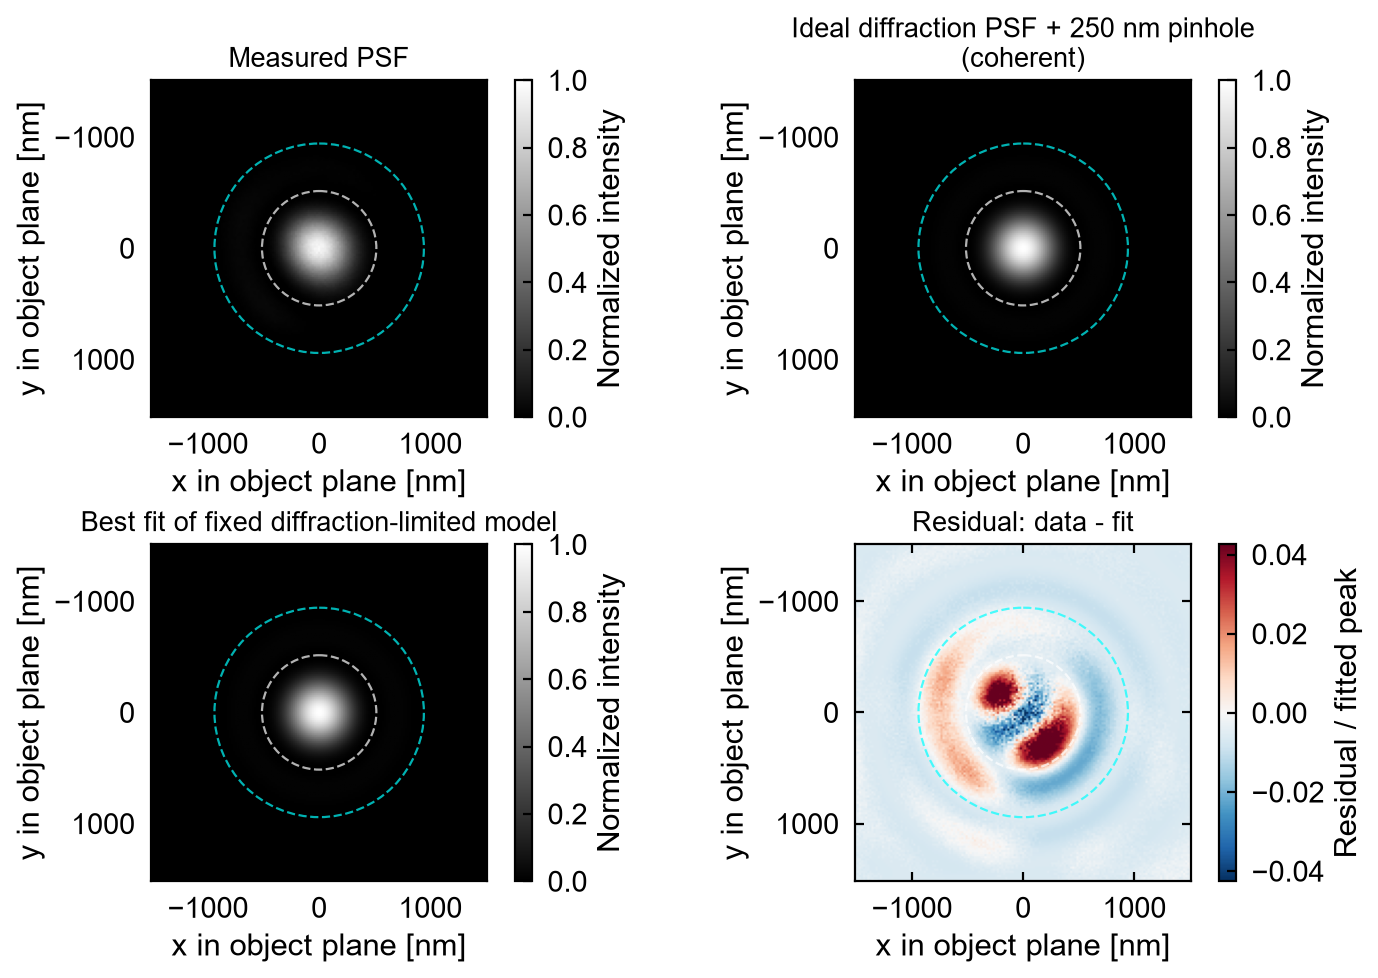

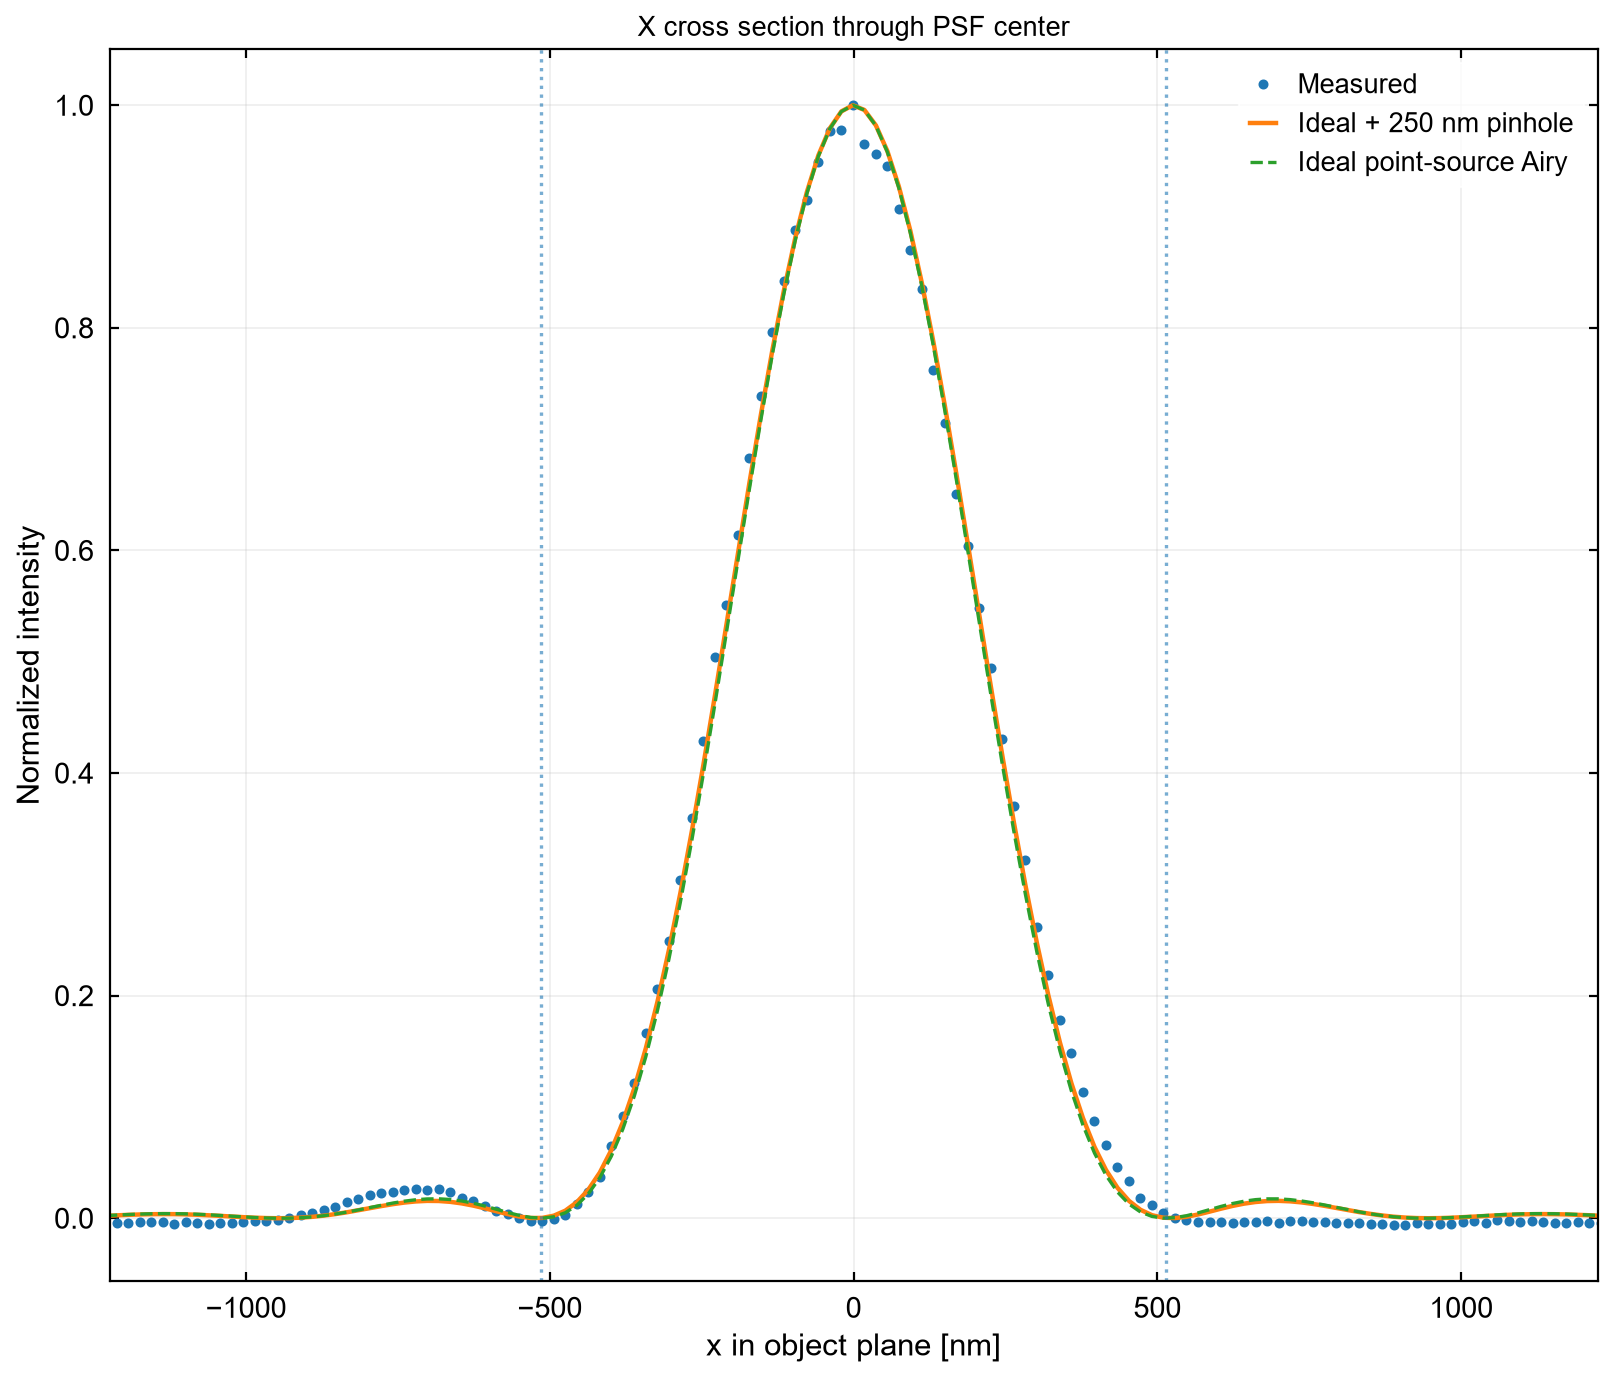

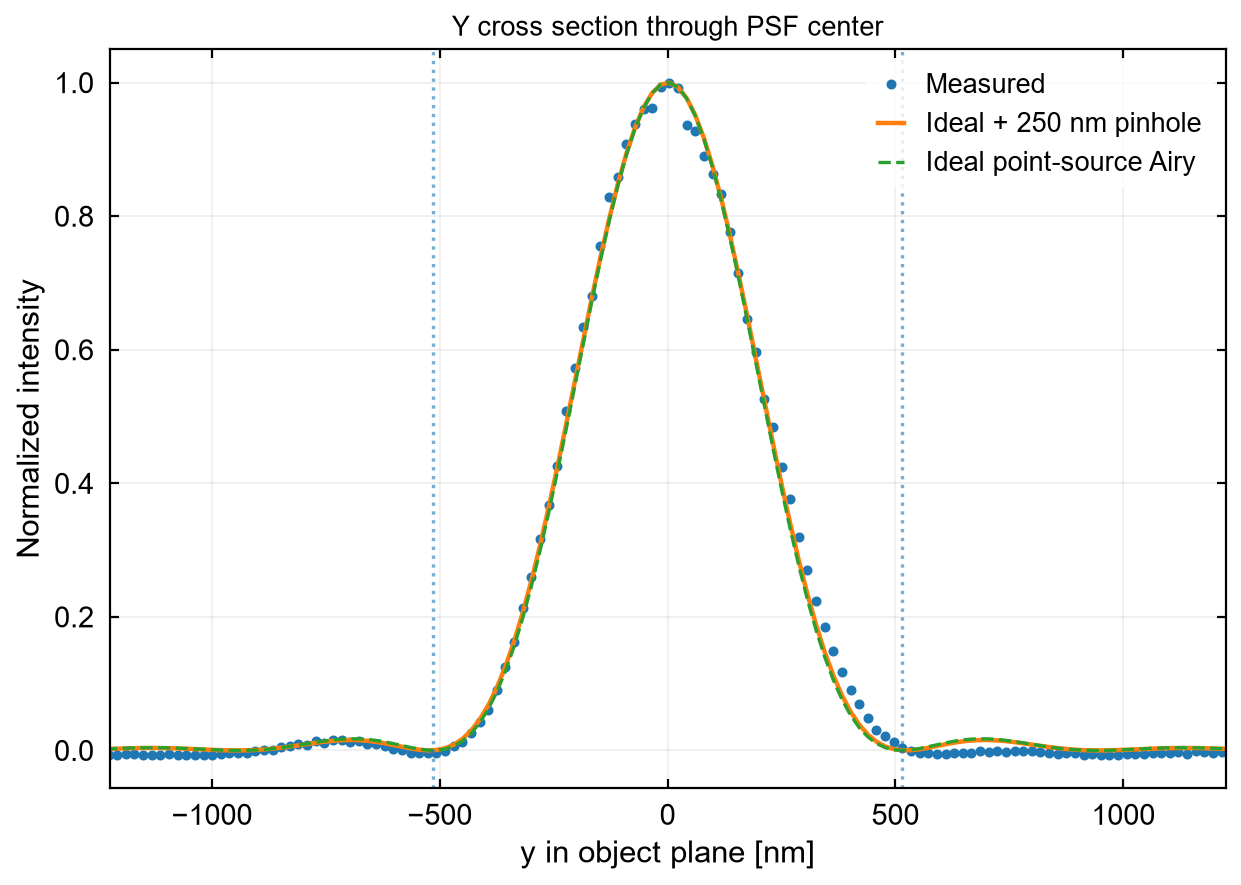


================ FWHM =================
Measured X FWHM = 455.29 nm
Measured Y FWHM = 451.29 nm
Finite-pinhole theory X FWHM = 438.53 nm
Finite-pinhole theory Y FWHM = 438.59 nm
Point-source theoretical Airy FWHM = 433.64 nm


================ STREHL =================
Strehl ROI radius = second Airy zero = 942.01 nm
                     = 49.75 camera pixels

Finite-pinhole Strehl estimate = 0.9066



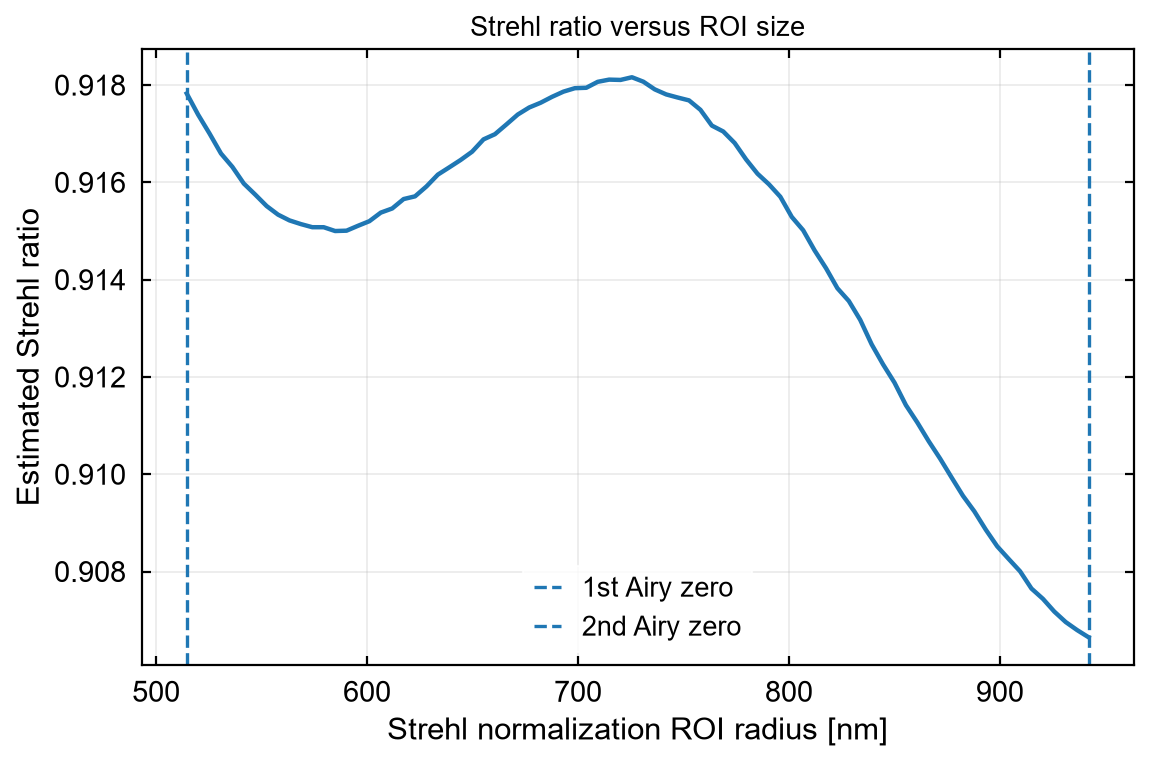



================ FINAL SUMMARY =================
lambda                     = 759.30 nm
NA                         = 0.900
magnification              = 182.200 x
object sampling            = 18.9352 nm/pixel
ideal point Airy FWHM      = 433.64 nm
first Airy zero radius     = 514.50 nm
second Airy zero radius    = 942.01 nm
measured X FWHM            = 455.29 nm
measured Y FWHM            = 451.29 nm
finite-source theory X     = 438.53 nm
finite-source theory Y     = 438.59 nm
Strehl <= second zero      = 0.9066



In [4]:
# ============================================================
# PSF ANALYSIS
#
# System:
#   lambda = 759.3 nm
#   Objective = Zeiss EC Epiplan-Neofluar 100x/0.9 DIC M27
#   NA = 0.9
#   Tube lens = 300 mm
#   Camera pixel pitch = 3.45 um
#   Magnification = measured from resolution target
#   Object = 250 nm diameter pinhole
#
# Produces:
#   1. Raw cropped PSF
#   2. Ideal diffraction-limited PSF including 250 nm pinhole
#   3. Best fit to data
#   4. Residual
#   5. X cross section: experiment vs theory
#   6. Y cross section: experiment vs theory
#   7. Strehl ratio using ROI <= second Airy zero
#
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import tifffile

from scipy.special import j1, jn_zeros
from scipy.signal import fftconvolve
from scipy.ndimage import (
    shift as nd_shift,
    gaussian_filter,
    map_coordinates,
)
from scipy.optimize import least_squares


# ============================================================
# USER SETTINGS
# ============================================================

PSF_FILE = r"C:\Users\admin\Desktop\Projects\Zeiss test\PSFs\psf with lens tiff.tif"

# Optical parameters
LAMBDA_NM = 759.3
NA = 0.90

# Camera
CAMERA_PIXEL_UM = 3.45

# ------------------------------------------------------------
# IMPORTANT:
# replace this if your final lp/mm calibration gives another M
# ------------------------------------------------------------
MAGNIFICATION = 182.2

# Zeiss theoretical magnification for comparison
ZEISS_TUBE_LENS_MM = 164.5
MY_TUBE_LENS_MM = 300.0
M_THEORY = 100.0 * MY_TUBE_LENS_MM / ZEISS_TUBE_LENS_MM

# Finite pinhole diameter
PINHOLE_DIAMETER_NM = 250.0

# Crop around PSF
CROP_HALF_SIZE = 80       # gives 161 x 161 crop

# Oversampling used to calculate theoretical PSF
# Odd integer is convenient because it preserves exact center.
OVERSAMPLE = 9

# ------------------------------------------------------------
# Finite pinhole model
#
# "coherent":
#     amplitude convolution, appropriate for a laser-illuminated
#     transmission pinhole.
#
# "incoherent":
#     intensity PSF convolved with 250 nm disk.
# ------------------------------------------------------------

SOURCE_MODE = "coherent"

# Fit centroid allowed to move this many camera pixels
MAX_SHIFT_PX = 8.0


# ============================================================
# DERIVED QUANTITIES
# ============================================================

OBJECT_PIXEL_NM = CAMERA_PIXEL_UM * 1000.0 / MAGNIFICATION

# Zeros of J1:
j1zeros = jn_zeros(1, 3)

# Airy dark-ring radii
r1_nm = j1zeros[0] * LAMBDA_NM / (2.0 * np.pi * NA)
r2_nm = j1zeros[1] * LAMBDA_NM / (2.0 * np.pi * NA)
r3_nm = j1zeros[2] * LAMBDA_NM / (2.0 * np.pi * NA)

r1_px = r1_nm / OBJECT_PIXEL_NM
r2_px = r2_nm / OBJECT_PIXEL_NM
r3_px = r3_nm / OBJECT_PIXEL_NM

airy_fwhm_nm = 0.514 * LAMBDA_NM / NA


print("\n================ SYSTEM =================")
print(f"Theoretical magnification = {M_THEORY:.3f} x")
print(f"Magnification used         = {MAGNIFICATION:.3f} x")
print(
    f"Difference                 = "
    f"{100*(MAGNIFICATION/M_THEORY - 1):+.3f} %"
)

print(f"\nObject-space pixel = {OBJECT_PIXEL_NM:.4f} nm/pixel")

print("\nIdeal point-source Airy values:")
print(f"First zero radius  = {r1_nm:.2f} nm = {r1_px:.2f} px")
print(f"Second zero radius = {r2_nm:.2f} nm = {r2_px:.2f} px")
print(f"Third zero radius  = {r3_nm:.2f} nm = {r3_px:.2f} px")
print(f"Airy FWHM          = {airy_fwhm_nm:.2f} nm")
print("=========================================\n")


# ============================================================
# LOAD TIFF
# ============================================================

raw = tifffile.imread(PSF_FILE)
raw = np.squeeze(raw)

if raw.ndim != 2:
    raise ValueError(f"Expected 2D TIFF; got shape {raw.shape}")

print("TIFF information:")
print("shape =", raw.shape)
print("dtype =", raw.dtype)
print("min   =", raw.min())
print("max   =", raw.max())
print("median=", np.median(raw))


# Work in floating point
data = raw.astype(np.float64)


# ============================================================
# FIND PSF
#
# Slight smoothing avoids accidentally selecting a single hot pixel.
# ============================================================

smooth = gaussian_filter(data, sigma=1.5)

y_peak_rough, x_peak_rough = np.unravel_index(
    np.argmax(smooth),
    smooth.shape
)

print("\nRough PSF position:")
print(f"x = {x_peak_rough}")
print(f"y = {y_peak_rough}")


# ============================================================
# CROP
# ============================================================

h = CROP_HALF_SIZE

x1 = x_peak_rough - h
x2 = x_peak_rough + h + 1

y1 = y_peak_rough - h
y2 = y_peak_rough + h + 1

if x1 < 0 or y1 < 0 or x2 > data.shape[1] or y2 > data.shape[0]:
    raise ValueError("Crop touches image edge. Reduce CROP_HALF_SIZE.")

crop = data[y1:y2, x1:x2]

ny, nx = crop.shape

xc = (nx - 1) / 2.0
yc = (ny - 1) / 2.0


# ============================================================
# BACKGROUND ESTIMATE
#
# Estimate background from crop edges, well outside Airy rings.
# ============================================================

border_width = 10

border = np.concatenate(
    [
        crop[:border_width, :].ravel(),
        crop[-border_width:, :].ravel(),
        crop[:, :border_width].ravel(),
        crop[:, -border_width:].ravel(),
    ]
)

background_border = np.median(border)
background_std = np.std(border)

print("\nBackground:")
print(f"median border background = {background_border:.3f}")
print(f"border std               = {background_std:.3f}")


# ============================================================
# AIRY FUNCTIONS
# ============================================================

def airy_amplitude(r_nm, wavelength_nm=LAMBDA_NM, na=NA):
    """
    Scalar circular-aperture coherent amplitude PSF:

        A(r) = 2 J1(u) / u

    where

        u = 2*pi*NA*r / lambda.
    """

    u = 2.0 * np.pi * na * r_nm / wavelength_nm

    out = np.ones_like(u, dtype=np.float64)

    mask = np.abs(u) > 1e-12

    out[mask] = 2.0 * j1(u[mask]) / u[mask]

    return out


def make_theory_psf(
    shape,
    object_pixel_nm,
    pinhole_diameter_nm,
    oversample=9,
    source_mode="coherent",
):
    """
    Generate:

      point-source Airy intensity PSF

    and

      finite-pinhole diffraction-limited PSF

    at the actual camera sampling.

    Camera pixel integration is included by oversampling and block averaging.
    """

    ny, nx = shape

    ny_hi = ny * oversample
    nx_hi = nx * oversample

    d_nm = object_pixel_nm / oversample

    x = (
        np.arange(nx_hi)
        - (nx_hi - 1) / 2.0
    ) * d_nm

    y = (
        np.arange(ny_hi)
        - (ny_hi - 1) / 2.0
    ) * d_nm

    X, Y = np.meshgrid(x, y)

    R = np.sqrt(X**2 + Y**2)

    # --------------------------------------------------------
    # Point-source PSF
    # --------------------------------------------------------

    amp = airy_amplitude(R)

    point_intensity = np.abs(amp)**2


    # --------------------------------------------------------
    # Finite 250 nm pinhole
    # --------------------------------------------------------

    radius_nm = pinhole_diameter_nm / 2.0

    disk = (R <= radius_nm).astype(np.float64)

    # normalize aperture representation
    disk /= disk.sum()


    if source_mode.lower() == "coherent":

        # coherent imaging:
        #
        # field_image = h_amplitude (*) object_amplitude
        #
        field = fftconvolve(
            amp,
            disk,
            mode="same"
        )

        finite_intensity = np.abs(field)**2


    elif source_mode.lower() == "incoherent":

        # incoherent imaging:
        #
        # I_image = PSF_intensity (*) object_intensity
        #
        finite_intensity = fftconvolve(
            point_intensity,
            disk,
            mode="same"
        )

    else:

        raise ValueError(
            "SOURCE_MODE must be 'coherent' or 'incoherent'"
        )


    # --------------------------------------------------------
    # Camera pixel integration
    # --------------------------------------------------------

    def camera_bin(image):

        image = image.reshape(
            ny,
            oversample,
            nx,
            oversample
        )

        return image.mean(axis=(1, 3))


    point_camera = camera_bin(point_intensity)
    finite_camera = camera_bin(finite_intensity)


    # Normalize to unit peak
    point_camera /= point_camera.max()
    finite_camera /= finite_camera.max()

    return point_camera, finite_camera


# ============================================================
# CREATE THEORETICAL PSFs
# ============================================================

point_theory, finite_theory = make_theory_psf(
    crop.shape,
    OBJECT_PIXEL_NM,
    PINHOLE_DIAMETER_NM,
    oversample=OVERSAMPLE,
    source_mode=SOURCE_MODE,
)


# ============================================================
# FIT MODEL TO DATA
#
# IMPORTANT:
#
# The diffraction width is NOT a fit parameter here.
#
# We keep:
#   lambda fixed
#   NA fixed
#   magnification fixed
#   pinhole diameter fixed
#
# Only fit:
#   amplitude
#   background
#   x position
#   y position
#
# This is much more meaningful for asking:
#
#     "Does my data agree with the diffraction-limited model?"
#
# Fit ROI is restricted to the SECOND AIRY ZERO.
# ============================================================

yy, xx = np.indices(crop.shape)

rr_center = np.sqrt(
    (xx - xc)**2 +
    (yy - yc)**2
)

fit_mask = rr_center <= r2_px


def model_from_parameters(params):

    amplitude, background, dx, dy = params

    shifted = nd_shift(
        finite_theory,
        shift=(dy, dx),
        order=3,
        mode="constant",
        cval=0.0,
        prefilter=True,
    )

    return background + amplitude * shifted


def residual_function(params):

    model = model_from_parameters(params)

    return (
        model[fit_mask]
        - crop[fit_mask]
    )


initial_amplitude = crop.max() - background_border

p0 = [
    initial_amplitude,
    background_border,
    0.0,
    0.0,
]


lower_bounds = [
    0.0,
    -np.inf,
    -MAX_SHIFT_PX,
    -MAX_SHIFT_PX,
]


upper_bounds = [
    np.inf,
    np.inf,
    MAX_SHIFT_PX,
    MAX_SHIFT_PX,
]


result = least_squares(
    residual_function,
    p0,
    bounds=(lower_bounds, upper_bounds),
)


A_fit, B_fit, dx_fit, dy_fit = result.x

fit_image = model_from_parameters(result.x)


x_fit_crop = xc + dx_fit
y_fit_crop = yc + dy_fit

x_fit_full = x1 + x_fit_crop
y_fit_full = y1 + y_fit_crop


print("\n================ FIT =================")
print(f"Amplitude     = {A_fit:.4f}")
print(f"Background    = {B_fit:.4f}")
print(f"dx            = {dx_fit:.4f} px")
print(f"dy            = {dy_fit:.4f} px")

print("\nFitted PSF centroid:")
print(f"x = {x_fit_full:.4f} camera pixels")
print(f"y = {y_fit_full:.4f} camera pixels")
print("======================================\n")


# Aligned theoretical model without amplitude/background
ideal_aligned = nd_shift(
    finite_theory,
    shift=(dy_fit, dx_fit),
    order=3,
    mode="constant",
    cval=0.0,
    prefilter=True,
)

point_aligned = nd_shift(
    point_theory,
    shift=(dy_fit, dx_fit),
    order=3,
    mode="constant",
    cval=0.0,
    prefilter=True,
)


# ============================================================
# OBJECT-SPACE COORDINATES
# ============================================================

x_nm = (
    np.arange(nx) - x_fit_crop
) * OBJECT_PIXEL_NM

y_nm = (
    np.arange(ny) - y_fit_crop
) * OBJECT_PIXEL_NM

extent = [
    x_nm[0],
    x_nm[-1],
    y_nm[-1],
    y_nm[0],
]


# ============================================================
# 2D FIGURES
# ============================================================

data_bgsub = crop - B_fit

data_norm = data_bgsub / A_fit
fit_norm = (fit_image - B_fit) / A_fit

residual = crop - fit_image
residual_norm = residual / A_fit


fig, axes = plt.subplots(
    2,
    2,
    figsize=(9, 6),
    constrained_layout=True,
)


# ------------------------------------------------------------
# RAW DATA
# ------------------------------------------------------------

im = axes[0, 0].imshow(
    data_norm,
    origin="upper",
    extent=extent,
    cmap="gray",
    vmin=0,
    vmax=1,
)

axes[0, 0].set_title("Measured PSF")
axes[0, 0].set_xlabel("x in object plane [nm]")
axes[0, 0].set_ylabel("y in object plane [nm]")

plt.colorbar(
    im,
    ax=axes[0, 0],
    label="Normalized intensity"
)


# ------------------------------------------------------------
# IDEAL FINITE PINHOLE
# ------------------------------------------------------------

im = axes[0, 1].imshow(
    ideal_aligned,
    origin="upper",
    extent=extent,
    cmap="gray",
    vmin=0,
    vmax=1,
)

axes[0, 1].set_title(
    f"Ideal diffraction PSF + {PINHOLE_DIAMETER_NM:.0f} nm pinhole\n"
    f"({SOURCE_MODE})"
)

axes[0, 1].set_xlabel("x in object plane [nm]")
axes[0, 1].set_ylabel("y in object plane [nm]")

plt.colorbar(
    im,
    ax=axes[0, 1],
    label="Normalized intensity"
)


# ------------------------------------------------------------
# BEST FIT
# ------------------------------------------------------------

im = axes[1, 0].imshow(
    fit_norm,
    origin="upper",
    extent=extent,
    cmap="gray",
    vmin=0,
    vmax=1,
)

axes[1, 0].set_title(
    "Best fit of fixed diffraction-limited model"
)

axes[1, 0].set_xlabel("x in object plane [nm]")
axes[1, 0].set_ylabel("y in object plane [nm]")

plt.colorbar(
    im,
    ax=axes[1, 0],
    label="Normalized intensity"
)


# ------------------------------------------------------------
# RESIDUAL
# ------------------------------------------------------------

residual_limit = np.percentile(
    np.abs(residual_norm),
    99
)

im = axes[1, 1].imshow(
    residual_norm,
    origin="upper",
    extent=extent,
    cmap="RdBu_r",
    vmin=-residual_limit,
    vmax=residual_limit,
)

axes[1, 1].set_title("Residual: data - fit")
axes[1, 1].set_xlabel("x in object plane [nm]")
axes[1, 1].set_ylabel("y in object plane [nm]")

plt.colorbar(
    im,
    ax=axes[1, 1],
    label="Residual / fitted peak"
)


# Draw first and second ideal Airy zeros
for ax in axes.ravel():

    circle1 = plt.Circle(
        (0, 0),
        r1_nm,
        fill=False,
        color="white",
        linestyle="--",
        linewidth=1,
        alpha=0.7,
    )

    circle2 = plt.Circle(
        (0, 0),
        r2_nm,
        fill=False,
        color="cyan",
        linestyle="--",
        linewidth=1,
        alpha=0.7,
    )

    ax.add_patch(circle1)
    ax.add_patch(circle2)


plt.show()


# ============================================================
# 1D X AND Y CROSS SECTIONS
#
# Use interpolation because fitted centroid may lie between pixels.
# ============================================================

# ------------------------------------------------------------
# X cross section
# ------------------------------------------------------------

x_indices = np.arange(nx, dtype=float)

y_constant = np.full(
    nx,
    y_fit_crop,
    dtype=float
)

data_x = map_coordinates(
    crop - B_fit,
    [y_constant, x_indices],
    order=1,
)

theory_x = map_coordinates(
    ideal_aligned,
    [y_constant, x_indices],
    order=1,
)

point_x = map_coordinates(
    point_aligned,
    [y_constant, x_indices],
    order=1,
)


# normalize to own peak for SHAPE comparison
data_x_norm = data_x / data_x.max()
theory_x_norm = theory_x / theory_x.max()
point_x_norm = point_x / point_x.max()


plt.figure(figsize=(12,10))

plt.plot(
    x_nm,
    data_x_norm,
    "o",
    markersize=3,
    label="Measured",
)

plt.plot(
    x_nm,
    theory_x_norm,
    linewidth=2,
    label=f"Ideal + {PINHOLE_DIAMETER_NM:.0f} nm pinhole",
)

plt.plot(
    x_nm,
    point_x_norm,
    "--",
    linewidth=1.5,
    label="Ideal point-source Airy",
)

plt.axvline(
    +r1_nm,
    linestyle=":",
    alpha=0.6
)

plt.axvline(
    -r1_nm,
    linestyle=":",
    alpha=0.6
)

plt.xlabel("x in object plane [nm]")
plt.ylabel("Normalized intensity")
plt.title("X cross section through PSF center")
plt.legend()
plt.grid(alpha=0.2)

plt.xlim(-1.3 * r2_nm, 1.3 * r2_nm)

plt.show()


# ------------------------------------------------------------
# Y cross section
# ------------------------------------------------------------

y_indices = np.arange(ny, dtype=float)

x_constant = np.full(
    ny,
    x_fit_crop,
    dtype=float
)

data_y = map_coordinates(
    crop - B_fit,
    [y_indices, x_constant],
    order=1,
)

theory_y = map_coordinates(
    ideal_aligned,
    [y_indices, x_constant],
    order=1,
)

point_y = map_coordinates(
    point_aligned,
    [y_indices, x_constant],
    order=1,
)


data_y_norm = data_y / data_y.max()
theory_y_norm = theory_y / theory_y.max()
point_y_norm = point_y / point_y.max()


plt.figure(figsize=(9, 6))

plt.plot(
    y_nm,
    data_y_norm,
    "o",
    markersize=3,
    label="Measured",
)

plt.plot(
    y_nm,
    theory_y_norm,
    linewidth=2,
    label=f"Ideal + {PINHOLE_DIAMETER_NM:.0f} nm pinhole",
)

plt.plot(
    y_nm,
    point_y_norm,
    "--",
    linewidth=1.5,
    label="Ideal point-source Airy",
)

plt.axvline(
    +r1_nm,
    linestyle=":",
    alpha=0.6
)

plt.axvline(
    -r1_nm,
    linestyle=":",
    alpha=0.6
)

plt.xlabel("y in object plane [nm]")
plt.ylabel("Normalized intensity")
plt.title("Y cross section through PSF center")
plt.legend()
plt.grid(alpha=0.2)

plt.xlim(-1.3 * r2_nm, 1.3 * r2_nm)

plt.show()


# ============================================================
# FWHM HELPER
# ============================================================

def fwhm_from_profile(position, intensity):

    intensity = np.asarray(intensity, dtype=float)

    intensity = intensity - np.min(intensity)

    if intensity.max() <= 0:
        return np.nan

    intensity = intensity / intensity.max()

    i0 = np.argmax(intensity)

    # search left crossing
    left = None

    for i in range(i0, 0, -1):

        if intensity[i - 1] < 0.5 <= intensity[i]:

            x1p = position[i - 1]
            x2p = position[i]

            y1p = intensity[i - 1]
            y2p = intensity[i]

            left = (
                x1p
                + (0.5 - y1p)
                * (x2p - x1p)
                / (y2p - y1p)
            )

            break


    # search right crossing
    right = None

    for i in range(i0, len(intensity) - 1):

        if intensity[i] >= 0.5 > intensity[i + 1]:

            x1p = position[i]
            x2p = position[i + 1]

            y1p = intensity[i]
            y2p = intensity[i + 1]

            right = (
                x1p
                + (0.5 - y1p)
                * (x2p - x1p)
                / (y2p - y1p)
            )

            break


    if left is None or right is None:
        return np.nan

    return right - left


print("\n================ FWHM =================")

print(
    f"Measured X FWHM = "
    f"{fwhm_from_profile(x_nm, data_x):.2f} nm"
)

print(
    f"Measured Y FWHM = "
    f"{fwhm_from_profile(y_nm, data_y):.2f} nm"
)

print(
    f"Finite-pinhole theory X FWHM = "
    f"{fwhm_from_profile(x_nm, theory_x):.2f} nm"
)

print(
    f"Finite-pinhole theory Y FWHM = "
    f"{fwhm_from_profile(y_nm, theory_y):.2f} nm"
)

print(
    f"Point-source theoretical Airy FWHM = "
    f"{airy_fwhm_nm:.2f} nm"
)

print("=======================================\n")


# ============================================================
# STREHL RATIO
#
# Standard logic:
#
#            measured peak / measured energy
# Strehl = ------------------------------------
#              ideal peak / ideal energy
#
# We use the SAME circular ROI for experiment and theory.
#
# IMPORTANT:
# ROI stops at SECOND DARK RING.
#
# This corresponds approximately to:
#
# central lobe + first bright side lobe
#
# and prevents far-away background/stray light from corrupting
# the normalization.
#
# Since the measured source is a finite 250 nm pinhole, the
# reference here is the IDEAL FINITE-PINHOLE PSF.
#
# Therefore this is the relevant experimental Strehl estimate
# for this dataset.
# ============================================================


# radial coordinates around fitted center
rr_fit = np.sqrt(
    (xx - x_fit_crop)**2
    + (yy - y_fit_crop)**2
)


# ------------------------------------------------------------
# Choose background for Strehl
#
# Border estimate is generally safer than fitting background
# from within the PSF itself.
# ------------------------------------------------------------

background_for_strehl = background_border

measured_for_strehl = crop - background_for_strehl


# ------------------------------------------------------------
# Estimate subpixel peak using local quadratic fit
# ------------------------------------------------------------

def quadratic_peak(image, x0, y0, half_width=3):

    xi = int(round(x0))
    yi = int(round(y0))

    ylo = max(0, yi - half_width)
    yhi = min(image.shape[0], yi + half_width + 1)

    xlo = max(0, xi - half_width)
    xhi = min(image.shape[1], xi + half_width + 1)

    patch = image[ylo:yhi, xlo:xhi]

    yy_p, xx_p = np.indices(patch.shape)

    xx_p = xx_p + xlo - x0
    yy_p = yy_p + ylo - y0

    Xmat = np.column_stack(
        [
            np.ones(patch.size),
            xx_p.ravel(),
            yy_p.ravel(),
            xx_p.ravel()**2,
            xx_p.ravel() * yy_p.ravel(),
            yy_p.ravel()**2,
        ]
    )

    coeff, *_ = np.linalg.lstsq(
        Xmat,
        patch.ravel(),
        rcond=None
    )

    c0, cx, cy, cxx, cxy, cyy = coeff

    H = np.array(
        [
            [2*cxx, cxy],
            [cxy, 2*cyy],
        ]
    )

    grad = np.array([cx, cy])

    try:

        delta = -np.linalg.solve(H, grad)

        dx, dy = delta

        # only trust fit if maximum lies reasonably close
        if (
            abs(dx) <= half_width
            and abs(dy) <= half_width
            and np.all(np.linalg.eigvals(H) < 0)
        ):

            peak = (
                c0
                + cx*dx
                + cy*dy
                + cxx*dx**2
                + cxy*dx*dy
                + cyy*dy**2
            )

            return peak

    except np.linalg.LinAlgError:
        pass

    # fallback
    return patch.max()


def calculate_strehl(radius_px):

    roi = rr_fit <= radius_px

    measured_energy = np.sum(
        measured_for_strehl[roi]
    )

    ideal_energy = np.sum(
        ideal_aligned[roi]
    )

    measured_peak = quadratic_peak(
        measured_for_strehl,
        x_fit_crop,
        y_fit_crop,
    )

    ideal_peak = quadratic_peak(
        ideal_aligned,
        x_fit_crop,
        y_fit_crop,
    )


    measured_peak_per_energy = (
        measured_peak / measured_energy
    )

    ideal_peak_per_energy = (
        ideal_peak / ideal_energy
    )

    strehl = (
        measured_peak_per_energy
        / ideal_peak_per_energy
    )

    return strehl


# ------------------------------------------------------------
# Recommended Strehl:
# ROI out to second Airy zero
# ------------------------------------------------------------

strehl_r2 = calculate_strehl(r2_px)


print("\n================ STREHL =================")

print(
    f"Strehl ROI radius = second Airy zero = "
    f"{r2_nm:.2f} nm"
)

print(
    f"                     = "
    f"{r2_px:.2f} camera pixels"
)

print(
    f"\nFinite-pinhole Strehl estimate = "
    f"{strehl_r2:.4f}"
)

print("=========================================\n")


# ============================================================
# CHECK HOW STREHL DEPENDS ON ROI
#
# This is useful because you correctly pointed out that the
# chosen ROI matters.
#
# We NEVER go beyond the second Airy zero.
# ============================================================

roi_radii_px = np.linspace(
    r1_px,
    r2_px,
    80
)

strehl_vs_roi = np.array(
    [
        calculate_strehl(r)
        for r in roi_radii_px
    ]
)

roi_radii_nm = (
    roi_radii_px * OBJECT_PIXEL_NM
)


plt.figure(figsize=(8, 5))

plt.plot(
    roi_radii_nm,
    strehl_vs_roi,
    linewidth=2
)

plt.axvline(
    r1_nm,
    linestyle="--",
    label="1st Airy zero"
)

plt.axvline(
    r2_nm,
    linestyle="--",
    label="2nd Airy zero"
)

plt.xlabel("Strehl normalization ROI radius [nm]")
plt.ylabel("Estimated Strehl ratio")
plt.title("Strehl ratio versus ROI size")
plt.grid(alpha=0.25)
plt.legend()

plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n\n================ FINAL SUMMARY =================")

print(f"lambda                     = {LAMBDA_NM:.2f} nm")
print(f"NA                         = {NA:.3f}")

print(
    f"magnification              = "
    f"{MAGNIFICATION:.3f} x"
)

print(
    f"object sampling            = "
    f"{OBJECT_PIXEL_NM:.4f} nm/pixel"
)

print(
    f"ideal point Airy FWHM      = "
    f"{airy_fwhm_nm:.2f} nm"
)

print(
    f"first Airy zero radius     = "
    f"{r1_nm:.2f} nm"
)

print(
    f"second Airy zero radius    = "
    f"{r2_nm:.2f} nm"
)

print(
    f"measured X FWHM            = "
    f"{fwhm_from_profile(x_nm, data_x):.2f} nm"
)

print(
    f"measured Y FWHM            = "
    f"{fwhm_from_profile(y_nm, data_y):.2f} nm"
)

print(
    f"finite-source theory X     = "
    f"{fwhm_from_profile(x_nm, theory_x):.2f} nm"
)

print(
    f"finite-source theory Y     = "
    f"{fwhm_from_profile(y_nm, theory_y):.2f} nm"
)

print(
    f"Strehl <= second zero      = "
    f"{strehl_r2:.4f}"
)

print("=================================================\n")

image (1080, 1440) uint16  min 1  max 1001
centre (536.066, 388.794);  annulus bg median 1.000, clipped mean 1.395, sd 0.678

object pixel 18.9352 nm; illumination model: coherent; D = 250.0 nm
measured peak (poly fit, r<=5.0 px) = 983.50 +- 3.88 counts above bg (max pixel 999.6)
            ROI radius      px annulus clipped mean (1.40)      annulus median (1.00)       border median (2.00)        fit offset B (7.24)
  1st zero    514.5 nm   27.17                     0.9167                     0.9156                     0.9183                     0.9327
  2nd zero    942.0 nm   49.75                     0.9008                     0.8969                     0.9069                     0.9637
  3rd zero   1366.0 nm   72.14                     0.9139                     0.9052                     0.9275                     1.0663
  4th zero   1789.0 nm   94.48                     0.9127                     0.8978                     0.9364                     1.2117
  5th zero   2211.6 nm 

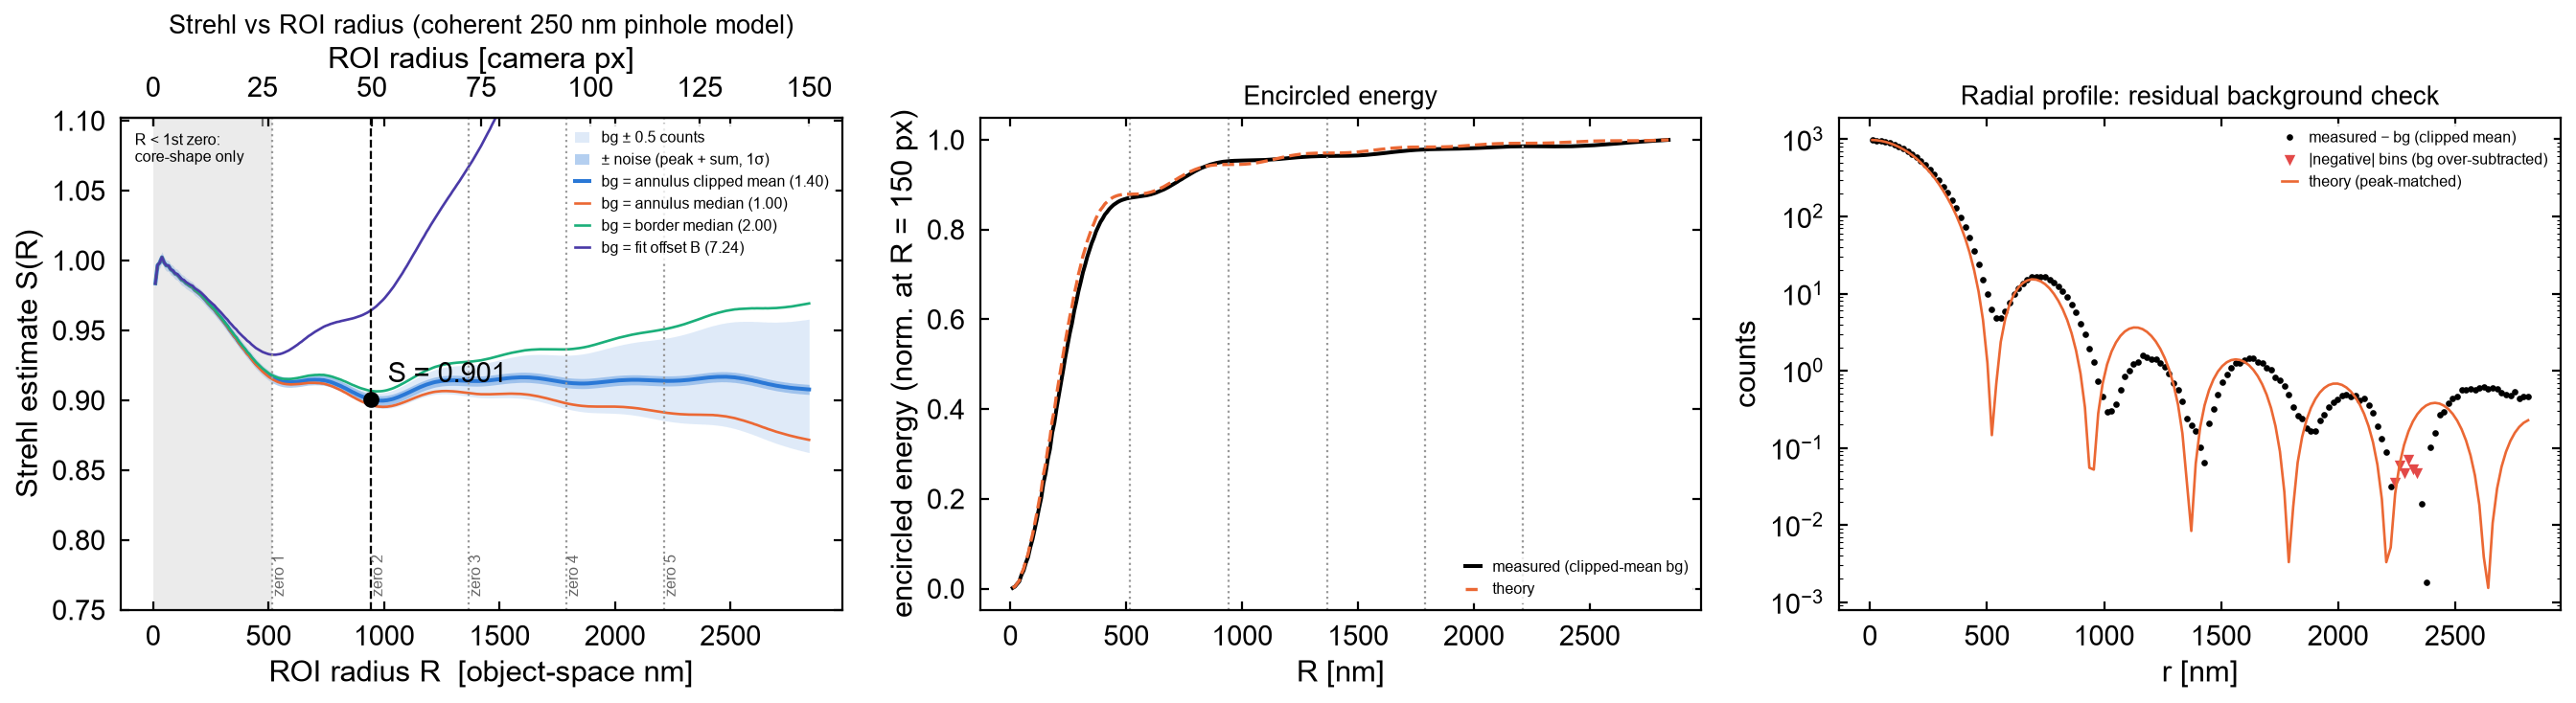

In [5]:
"""
strehl_vs_roi.py  -  Strehl-ratio estimate as a function of the integration ROI radius
===============================================================================

Definition used (normalised-peak / "energy-normalised" Strehl within a circular ROI):

                 I_meas(0) / sum_{r<R} I_meas
      S(R) = -----------------------------------
                 I_theo(0) / sum_{r<R} I_theo

  I_meas : background-subtracted camera image
  I_theo : diffraction-limited image of the finite pinhole (NA, lambda, D), computed
           exactly with a Hankel integral, then pixel-integrated on the SAME camera grid
           with the SAME sub-pixel centre as the measurement
  I(0)   : peak from a 2D 4th-order polynomial fitted to the pixels within 5 px - applied
           identically to the measured and to the theory image, so the estimator's
           small bias (the Airy core is not a paraboloid) cancels

Notes
  * S(R) -> 1 trivially for R -> 0 (both profiles are "all peak"); it only tests the
    core shape for R < first zero. It becomes meaningful for R >= 2nd-3rd Airy zero.
  * For large R the result is dominated by the background: an offset error dB changes
    sum_{r<R} I_meas by dB * pi R^2. The script therefore shows S(R) for several
    background choices - if the curve does not flatten into a plateau, the background
    (not the optics) is what you are measuring.
  * Requires the raw, linear, unsaturated image (e.g. 16-bit TIFF from the CS165MU,
    10-bit ADC -> max 1023). Do not use display-scaled 8-bit exports.

Requires: numpy, scipy, matplotlib, tifffile (or pillow)
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j0, j1
from scipy.optimize import least_squares

# =============================== USER SETTINGS ==================================
TIFF_FILE = r"C:\Users\admin\Desktop\Projects\Zeiss test\PSFs\psf with lens tiff.tif"
LAM_NM = 759.3
NA = 0.90
M = 182.2                 # magnification used
PIX_UM = 3.45             # camera pixel
D_PIN_NM = 250.0          # pinhole diameter
ILLUMINATION = "coherent" # "coherent" (laser-illuminated pinhole; your 438.5 nm FWHM
                          #  corresponds to this) or "incoherent" (Airy (x) disk, 452.6 nm)
CENTER = (536.0662, 388.7942)   # (x, y) camera px; set None to fit automatically
R_MAX_PX = 150            # largest ROI radius to scan
R_STEP_PX = 0.5
BG_ANNULUS_PX = (160, 260)  # annulus (around the PSF) used for the local background
# extra background levels to compare (label: value in counts); the annulus median is
# always included. Your border median (2.0) and the fitted offset (7.24) are shown too.
BG_EXTRA = {"border median": 2.0, "fit offset B": 7.2443}
PEAK_FIT_R_PX = 5.0       # radius of the pixel disk used to estimate the peak (<~ HWHM/2)
BG_DELTA = 0.5            # +/- band (counts) drawn around the annulus background
ROI_MARK_NM = None        # ROI to highlight; None -> second Airy zero
OUT_PNG = "strehl_vs_roi.png"
# ================================================================================

P_OBJ_NM = PIX_UM * 1e3 / M
AIRY_ZEROS = np.array([3.8317060, 7.0155867, 10.1734681, 13.3236919, 16.4706301])


def load_image(fn):
    try:
        import tifffile
        a = tifffile.imread(fn)
    except ImportError:
        from PIL import Image
        a = np.array(Image.open(fn))
    if a.ndim == 3:
        a = a[..., 0] if a.shape[-1] in (3, 4) else a[0]
    return a.astype(float), a.dtype


# ---------------------------------------------------------------- theory
def radial_model(r_nm, lam=LAM_NM, na=NA, d=D_PIN_NM, kind=ILLUMINATION, n=4000):
    """Normalised (I(0)=1) radial image of a uniformly illuminated disk of diameter d."""
    r = np.atleast_1d(np.asarray(r_nm, float))
    nc = (na / lam) if kind == "coherent" else (2 * na / lam)      # cycles / nm
    nu = (np.arange(n) + 0.5) / n * nc
    x = np.pi * d * nu
    dhat = np.where(x > 1e-12, 2 * j1(x) / np.where(x > 1e-12, x, 1), 1.0)
    if kind == "coherent":
        w = dhat * 2 * np.pi * nu
        E = j0(2 * np.pi * np.outer(r, nu)) @ w
        return (E / w.sum()) ** 2
    s = nu / nc
    otf = (2 / np.pi) * (np.arccos(s) - s * np.sqrt(1 - s ** 2))
    w = otf * dhat * 2 * np.pi * nu
    return (j0(2 * np.pi * np.outer(r, nu)) @ w) / w.sum()


def theory_image(shape, xc, yc, rmax_px, sub=5):
    """Pixel-integrated (sub x sub) theory image on the camera grid, centred at (xc, yc)."""
    rr = np.linspace(0, (rmax_px + 3) * P_OBJ_NM, 8000)
    Ir = radial_model(rr)
    yy, xx = np.indices(shape)
    m = np.hypot(xx - xc, yy - yc) <= rmax_px + 2
    X, Y = xx[m].astype(float), yy[m].astype(float)
    off = (np.arange(sub) + 0.5) / sub - 0.5
    acc = np.zeros(X.size)
    for dx in off:
        for dy in off:
            acc += np.interp(np.hypot(X + dx - xc, Y + dy - yc) * P_OBJ_NM, rr, Ir)
    img = np.zeros(shape)
    img[m] = acc / sub ** 2
    # peak for a pixel centred exactly on the PSF centre
    peak = np.mean([np.interp(np.hypot(dx, dy) * P_OBJ_NM, rr, Ir) for dx in off for dy in off])
    return img, peak


# ---------------------------------------------------------------- measurement
def fit_center(a):
    y0, x0 = np.unravel_index(np.argmax(a), a.shape)
    h = 12
    yy, xx = np.mgrid[y0 - h:y0 + h + 1, x0 - h:x0 + h + 1]
    z = a[y0 - h:y0 + h + 1, x0 - h:x0 + h + 1]
    f = lambda p: (p[0] + p[1] * np.exp(-((xx - p[2]) ** 2 + (yy - p[3]) ** 2) / (2 * p[4] ** 2)) - z).ravel()
    p = least_squares(f, [np.median(a), z.max(), x0, y0, 10]).x
    return p[2], p[3]


def fit_peak(a, xc, yc, rfit=PEAK_FIT_R_PX, deg=4):
    """Peak value from a 2D polynomial (degree `deg`) fitted to all pixels within rfit of the
    centre, maximised on a fine grid (|dr| < 2 px). Returns (peak, 1-sigma from residuals).
    Using ~80 pixels instead of the single brightest pixel reduces the shot-noise error of
    the peak - which is the dominant statistical error of any Strehl estimate."""
    ix, iy = int(round(xc)), int(round(yc))
    h = int(np.ceil(rfit)) + 1
    yy, xx = np.mgrid[iy - h:iy + h + 1, ix - h:ix + h + 1]
    m = np.hypot(xx - xc, yy - yc) <= rfit
    X, Y = (xx[m] - xc).astype(float), (yy[m] - yc).astype(float)
    z = a[yy[m], xx[m]]
    terms = [(i, j) for i in range(deg + 1) for j in range(deg + 1 - i)]
    A = np.stack([X ** i * Y ** j for i, j in terms], 1)
    c, *_ = np.linalg.lstsq(A, z, rcond=None)
    dof = z.size - len(terms)
    cov = np.linalg.pinv(A.T @ A) * ((z - A @ c) ** 2).sum() / dof
    g = np.linspace(-2, 2, 81)
    GX, GY = np.meshgrid(g, g)
    G = np.stack([GX.ravel() ** i * GY.ravel() ** j for i, j in terms], 1)
    v = G @ c
    k = np.argmax(v)
    return float(v[k]), float(np.sqrt(G[k] @ cov @ G[k]))


def background(a, xc, yc, r_in, r_out):
    yy, xx = np.indices(a.shape)
    r = np.hypot(xx - xc, yy - yc)
    v = a[(r >= r_in) & (r < r_out)]
    for _ in range(5):  # sigma clipping
        med, sd = np.median(v), np.std(v)
        v = v[np.abs(v - med) < 3 * sd]
    return float(np.median(v)), float(np.mean(v)), float(np.std(v))


def cumulative(img, xc, yc, radii):
    yy, xx = np.indices(img.shape)
    r = np.hypot(xx - xc, yy - yc).ravel()
    o = np.argsort(r)
    rs, cs = r[o], np.cumsum(img.ravel()[o])
    npix = np.searchsorted(rs, radii, side="left")
    return np.where(npix > 0, cs[np.maximum(npix - 1, 0)], 0.0), npix


def main():
    a, dtype = load_image(TIFF_FILE)
    print(f"image {a.shape} {dtype}  min {a.min():.0f}  max {a.max():.0f}")
    xc, yc = CENTER if CENTER is not None else fit_center(a)
    if np.issubdtype(dtype, np.integer):
        lim = min(np.iinfo(dtype).max, 1023)          # CS165MU: 10-bit ADC
        yy_, xx_ = np.indices(a.shape)
        nsat = int(((a >= lim) & (np.hypot(xx_ - xc, yy_ - yc) < 30)).sum())
        if nsat:
            print(f"WARNING: {nsat} pixels at {lim} in the PSF core -> saturated, Strehl invalid")
    bg_med, bg_mean, bg_sd = background(a, xc, yc, *BG_ANNULUS_PX)
    print(f"centre ({xc:.3f}, {yc:.3f});  annulus bg median {bg_med:.3f}, clipped mean {bg_mean:.3f}, sd {bg_sd:.3f}")

    radii = np.arange(R_STEP_PX, R_MAX_PX + 1e-9, R_STEP_PX)
    th_img, th_peak_exact = theory_image(a.shape, xc, yc, R_MAX_PX)
    th_peak, _ = fit_peak(th_img, xc, yc)          # same estimator -> its bias cancels
    Et, npix = cumulative(th_img, xc, yc, radii)
    raw_sum, _ = cumulative(a, xc, yc, radii)
    raw_peak, s_peak = fit_peak(a, xc, yc)

    k_px = 2 * np.pi * NA / LAM_NM * P_OBJ_NM          # Airy k in 1/px
    zeros_px = AIRY_ZEROS / k_px
    R_mark = (ROI_MARK_NM / P_OBJ_NM) if ROI_MARK_NM else zeros_px[1]

    def strehl(B):
        Em = raw_sum - B * npix                          # sum of (I - B) over r < R
        return ((raw_peak - B) / Em) / (th_peak / Et), Em
    # NOTE: default = sigma-clipped MEAN. The median of integer data is quantised to whole
    # counts (e.g. exactly 1.0 or 2.0) -> up to 0.5 count bias, which over pi R^2 pixels
    # biases S(R) by several % at large R.
    bg_med, bg_median_only = bg_mean, bg_med
    bgs = {f"annulus clipped mean ({bg_mean:.2f})": bg_mean,
           f"annulus median ({bg_median_only:.2f})": bg_median_only}
    bgs.update({f"{k} ({v:.2f})": v for k, v in BG_EXTRA.items()})

    # statistical error: peak (fit residuals) and ROI sum (read/background noise + shot
    # noise of the signal, gain unknown -> signal shot noise approximated from the peak-fit
    # residual scaling: var = bg_sd^2 * N + gain_ADU * Em, gain_ADU ~ s_peak_pix^2 / peak)
    S0, Em0 = strehl(bg_med)
    rel_peak = s_peak / (raw_peak - bg_med)
    rel_sum = bg_sd * np.sqrt(npix) / Em0
    sS_stat = S0 * np.hypot(rel_peak, rel_sum)
    S_lo, _ = strehl(bg_med + BG_DELTA)
    S_hi, _ = strehl(bg_med - BG_DELTA)

    # ------------------------------------------------------------- printout
    print(f"\nobject pixel {P_OBJ_NM:.4f} nm; illumination model: {ILLUMINATION}; D = {D_PIN_NM} nm")
    print(f"measured peak (poly fit, r<={PEAK_FIT_R_PX} px) = {raw_peak - bg_med:.2f} +- {s_peak:.2f} counts above bg"
          f" (max pixel {a.max() - bg_med:.1f})")
    print(f"{'ROI radius':>22} {'px':>7}", *[f"{k:>26}" for k in bgs])
    rows = [("1st zero", zeros_px[0]), ("2nd zero", zeros_px[1]), ("3rd zero", zeros_px[2]),
            ("4th zero", zeros_px[3]), ("5th zero", zeros_px[4]), ("R_max", radii[-1])]
    for name, R in rows:
        if R > radii[-1] + 1e-9:
            continue
        i = np.argmin(np.abs(radii - R))
        vals = [strehl(B)[0][i] for B in bgs.values()]
        print(f"{name:>10} {R * P_OBJ_NM:8.1f} nm {R:7.2f}", *[f"{v:26.4f}" for v in vals])
    i2 = np.argmin(np.abs(radii - R_mark))
    print(f"\nS(R = {R_mark * P_OBJ_NM:.1f} nm) = {S0[i2]:.4f}  +- {sS_stat[i2]:.4f} (noise: peak + sum)"
          f"  +- {abs(S_hi[i2] - S_lo[i2]) / 2:.4f} (bg +- {BG_DELTA} counts)")

    # ------------------------------------------------------------- plots
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
    ax = axs[0]
    cols = ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#e34948"]
    rn = radii * P_OBJ_NM
    ax.fill_between(rn, S_lo, S_hi, color="#2a78d6", alpha=0.15, lw=0, label=f"bg ± {BG_DELTA} counts")
    ax.fill_between(rn, S0 - sS_stat, S0 + sS_stat, color="#2a78d6", alpha=0.35, lw=0, label="± noise (peak + sum, 1σ)")
    for (lab, B), c in zip(bgs.items(), cols):
        ax.plot(rn, strehl(B)[0], color=c, lw=1.8 if c == cols[0] else 1.2, label=f"bg = {lab}")
    for j, z in enumerate(zeros_px):
        if z <= radii[-1]:
            ax.axvline(z * P_OBJ_NM, color="0.6", ls=":", lw=1)
            ax.text(z * P_OBJ_NM, 0.02, f" zero {j + 1}", rotation=90, fontsize=7, color="0.4",
                    transform=ax.get_xaxis_transform(), va="bottom")
    ax.axvline(R_mark * P_OBJ_NM, color="k", ls="--", lw=1)
    ax.plot(R_mark * P_OBJ_NM, S0[i2], "ko")
    ax.annotate(f"S = {S0[i2]:.3f}", (R_mark * P_OBJ_NM, S0[i2]), xytext=(8, 8), textcoords="offset points")
    ax.axvspan(0, zeros_px[0] * P_OBJ_NM, color="0.85", alpha=0.5, lw=0)
    ax.text(0.02, 0.97, "R < 1st zero:\ncore-shape only", transform=ax.transAxes, va="top", fontsize=7)
    ax.set_xlabel("ROI radius R  [object-space nm]")
    ax.set_ylabel("Strehl estimate S(R)")
    ax.set_title(f"Strehl vs ROI radius ({ILLUMINATION} {D_PIN_NM:.0f} nm pinhole model)")
    ax.set_ylim(max(0, np.nanmin(S0[radii > zeros_px[0]]) - 0.15), min(1.3, np.nanmax(S0) + 0.1))
    ax.legend(fontsize=7, loc="upper right")
    sec = ax.secondary_xaxis("top", functions=(lambda x: x / P_OBJ_NM, lambda x: x * P_OBJ_NM))
    sec.set_xlabel("ROI radius [camera px]")

    ax = axs[1]  # encircled energy
    Em_n = Em0 / Em0[-1]; Et_n = Et / Et[-1]
    ax.plot(rn, Em_n, color="k", lw=1.8, label="measured (clipped-mean bg)")
    ax.plot(rn, Et_n, color="#eb6834", ls="--", label="theory")
    for z in zeros_px:
        if z <= radii[-1]:
            ax.axvline(z * P_OBJ_NM, color="0.6", ls=":", lw=1)
    ax.set_xlabel("R [nm]"); ax.set_ylabel(f"encircled energy (norm. at R = {radii[-1]:.0f} px)")
    ax.set_title("Encircled energy")
    ax.legend(fontsize=7)

    ax = axs[2]  # radial profile: shows whether the background goes to zero
    rb = np.arange(0, R_MAX_PX + 1, 1.0)
    yy, xx = np.indices(a.shape)
    r = np.hypot(xx - xc, yy - yc)
    m = r < rb[-1]
    idx = np.digitize(r[m], rb) - 1
    cnt = np.bincount(idx, minlength=rb.size)
    prof = np.bincount(idx, a[m] - bg_med, minlength=rb.size) / np.maximum(cnt, 1)
    tprof = np.bincount(idx, th_img[m], minlength=rb.size) / np.maximum(cnt, 1)
    rc = (rb + 0.5) * P_OBJ_NM
    scale = (raw_peak - bg_med) / th_peak
    ok = rb < R_MAX_PX - 1
    pos, neg = ok & (prof > 0), ok & (prof < 0)
    ax.semilogy(rc[pos], prof[pos], "k.", ms=3, label="measured − bg (clipped mean)")
    ax.semilogy(rc[neg], -prof[neg], "v", color="#e34948", ms=3, label="|negative| bins (bg over-subtracted)")
    ax.semilogy(rc[ok], tprof[ok] * scale, color="#eb6834", lw=1.2, label="theory (peak-matched)")
    ax.set_xlabel("r [nm]"); ax.set_ylabel("counts")
    ax.set_title("Radial profile: residual background check")
    ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(OUT_PNG, dpi=150)
    print(f"saved {OUT_PNG}")
    plt.show()


if __name__ == "__main__":
    main()

## Axial scan

In [6]:
from pathlib import Path

FOLDER = Path(
    r"C:\Users\admin\Desktop\Projects\Zeiss test\PSFs\axial scan"
)

print("Looking in:", FOLDER)
print("Folder exists:", FOLDER.exists())

tif_files = list(FOLDER.glob("*.tif"))

print("Number of TIFF files:", len(tif_files))
print(tif_files[:5])

Looking in: C:\Users\admin\Desktop\Projects\Zeiss test\PSFs\axial scan
Folder exists: True
Number of TIFF files: 101
[WindowsPath('C:/Users/admin/Desktop/Projects/Zeiss test/PSFs/axial scan/-1.tif'), WindowsPath('C:/Users/admin/Desktop/Projects/Zeiss test/PSFs/axial scan/-10.tif'), WindowsPath('C:/Users/admin/Desktop/Projects/Zeiss test/PSFs/axial scan/-11.tif'), WindowsPath('C:/Users/admin/Desktop/Projects/Zeiss test/PSFs/axial scan/-12.tif'), WindowsPath('C:/Users/admin/Desktop/Projects/Zeiss test/PSFs/axial scan/-13.tif')]


Found 101 TIFF files.
Step range: -50 to 50
All 101 expected positions are present.
-50   x= 548.962   y= 401.144   FWHMgeo= 23.084 px   ellip=1.075   R²=0.98895
-49   x= 549.157   y= 400.940   FWHMgeo= 22.941 px   ellip=1.075   R²=0.98838
-48   x= 548.032   y= 401.711   FWHMgeo= 23.268 px   ellip=1.073   R²=0.98945
-47   x= 548.024   y= 400.555   FWHMgeo= 22.623 px   ellip=1.074   R²=0.98635
-46   x= 548.320   y= 400.188   FWHMgeo= 22.532 px   ellip=1.070   R²=0.98564
-45   x= 546.603   y= 400.384   FWHMgeo= 22.472 px   ellip=1.069   R²=0.98536
-44   x= 546.860   y= 400.091   FWHMgeo= 22.401 px   ellip=1.064   R²=0.98491
-43   x= 545.713   y= 400.096   FWHMgeo= 22.360 px   ellip=1.063   R²=0.98461
-42   x= 546.715   y= 399.604   FWHMgeo= 22.311 px   ellip=1.059   R²=0.98453
-41   x= 544.755   y= 399.829   FWHMgeo= 22.303 px   ellip=1.056   R²=0.98463
-40   x= 545.046   y= 399.424   FWHMgeo= 22.289 px   ellip=1.051   R²=0.98483
-39   x= 545.896   y= 398.968   FWHMgeo= 22.308 px   ellip

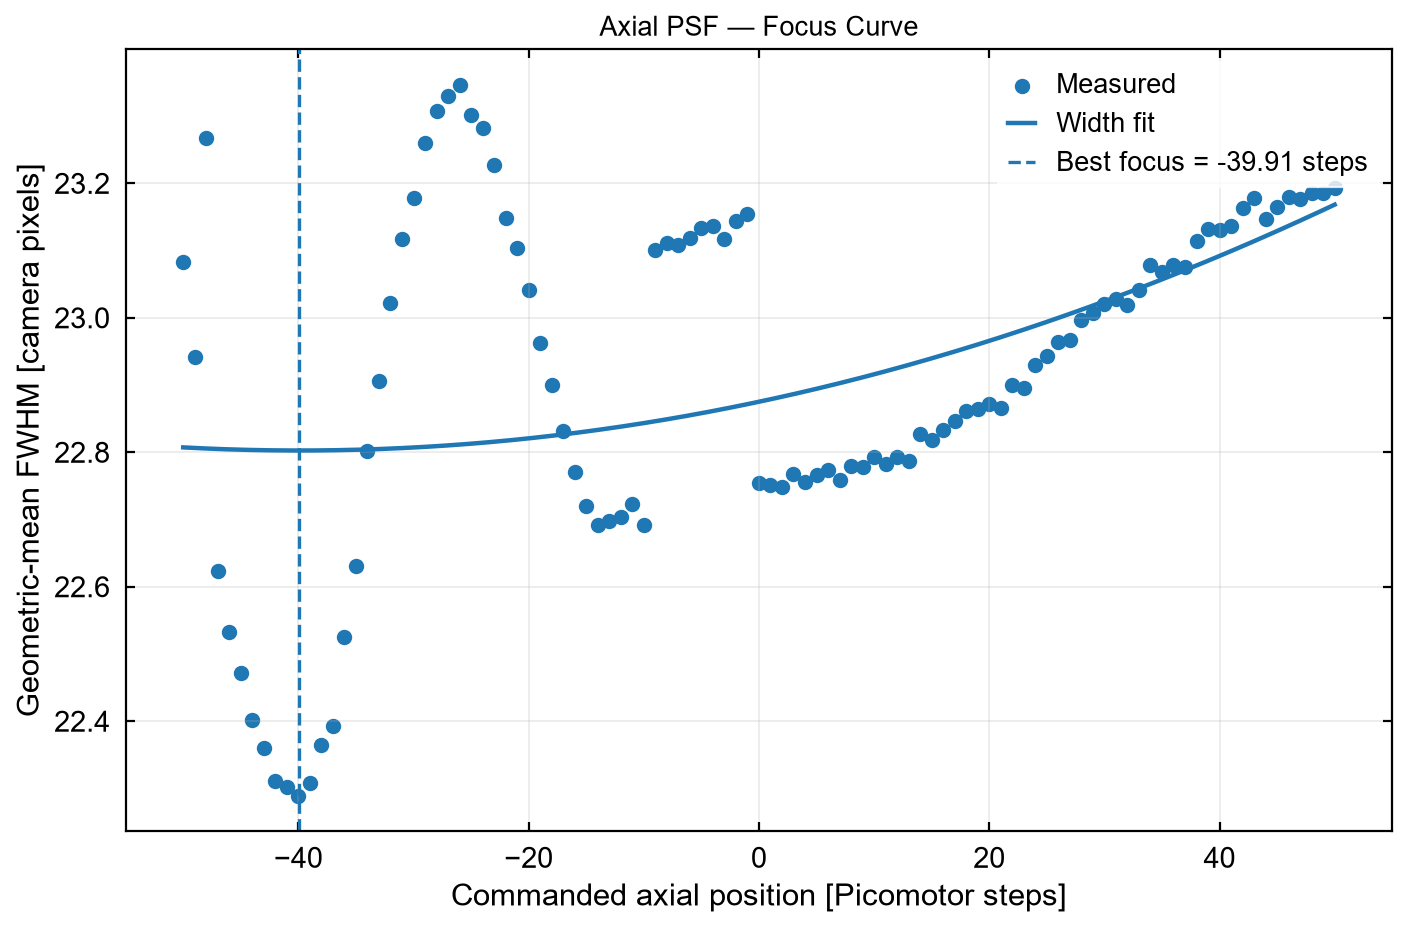

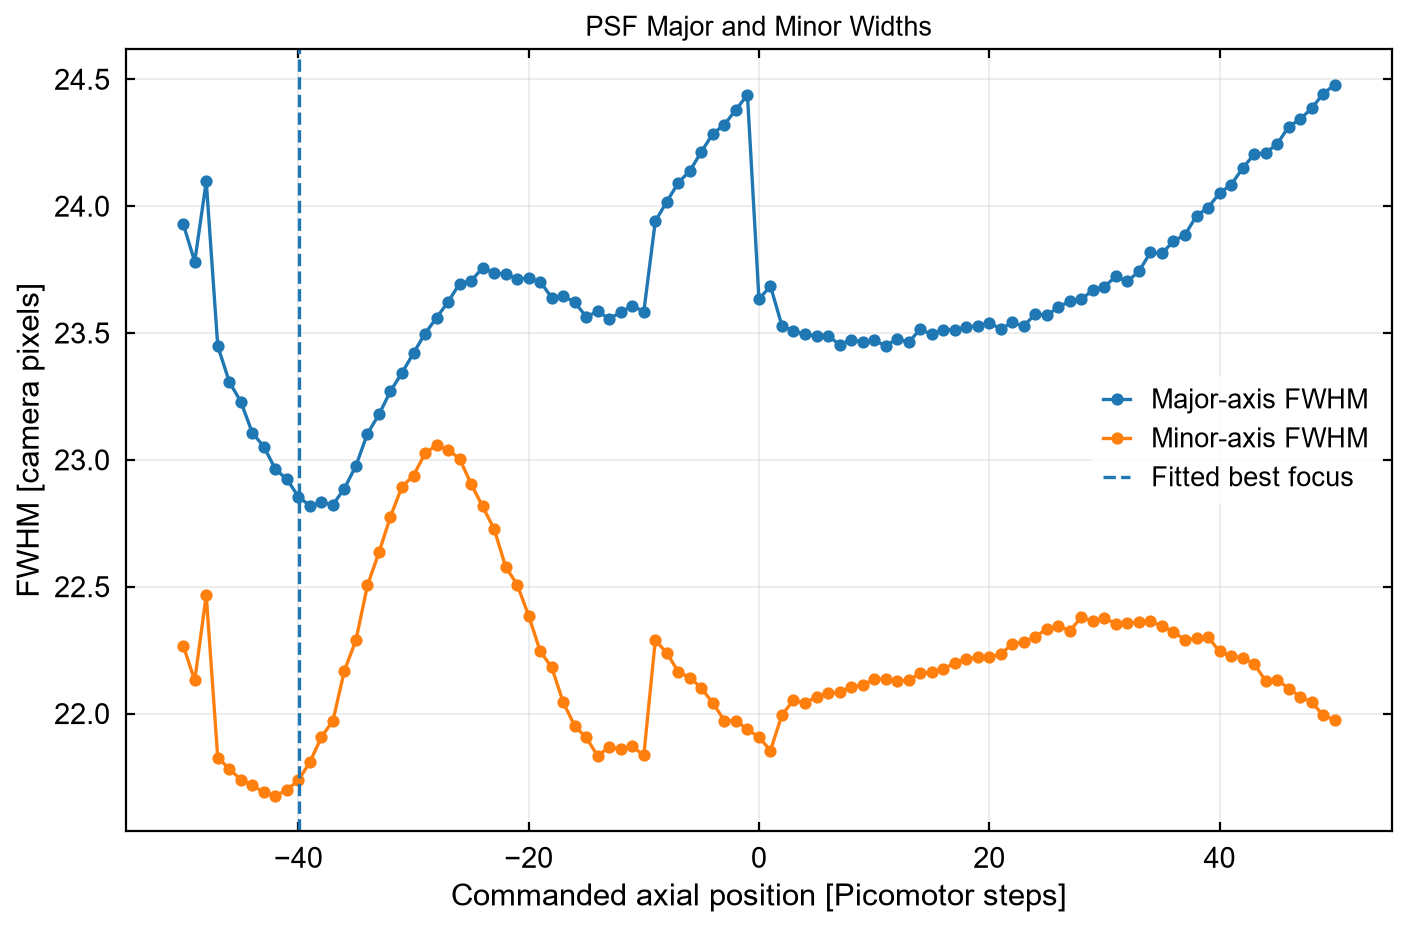

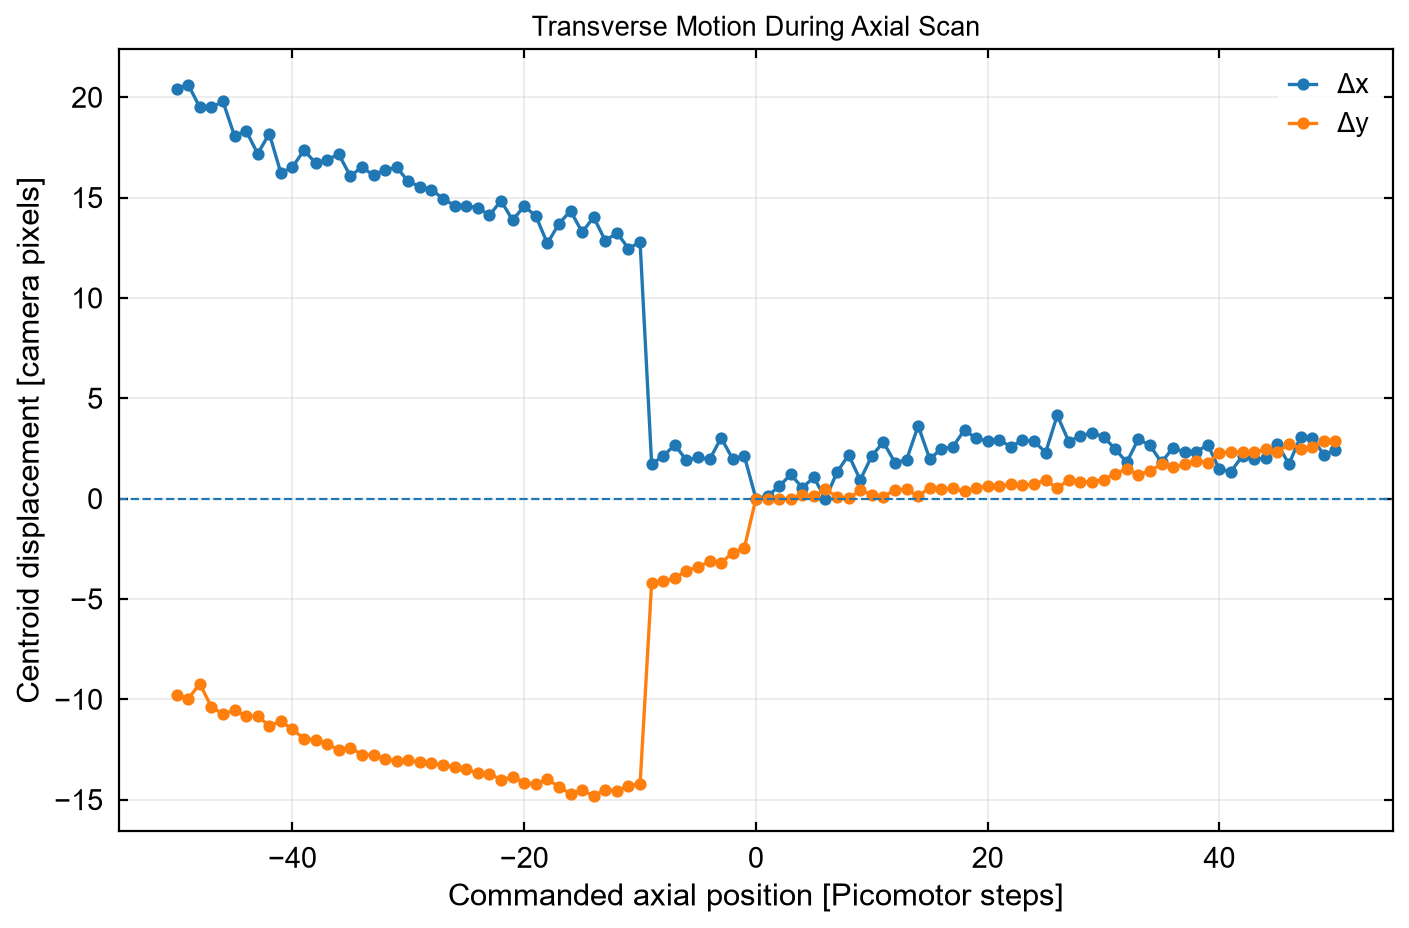

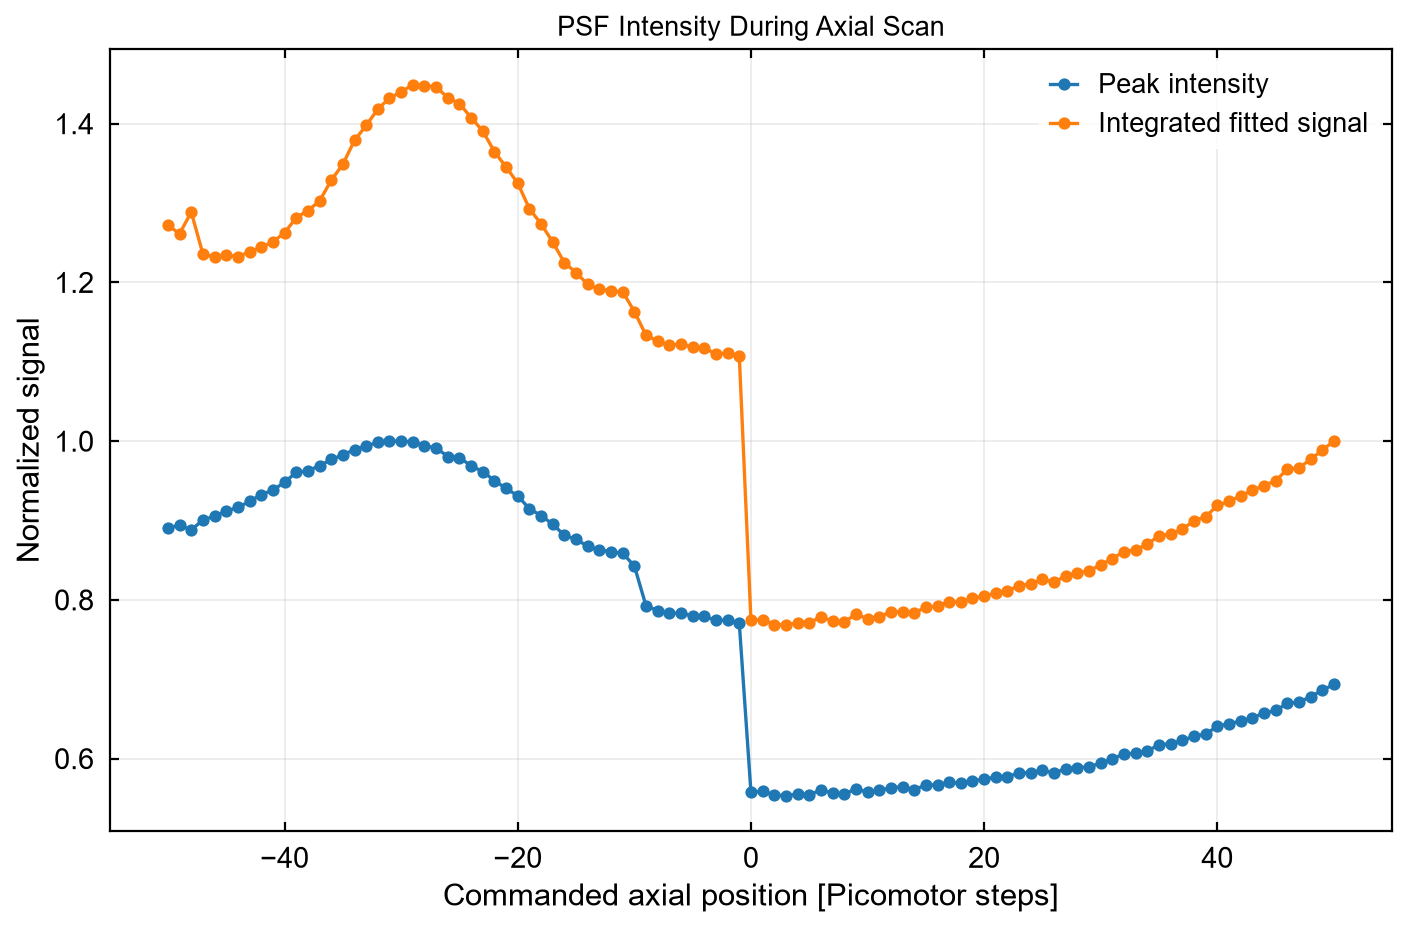

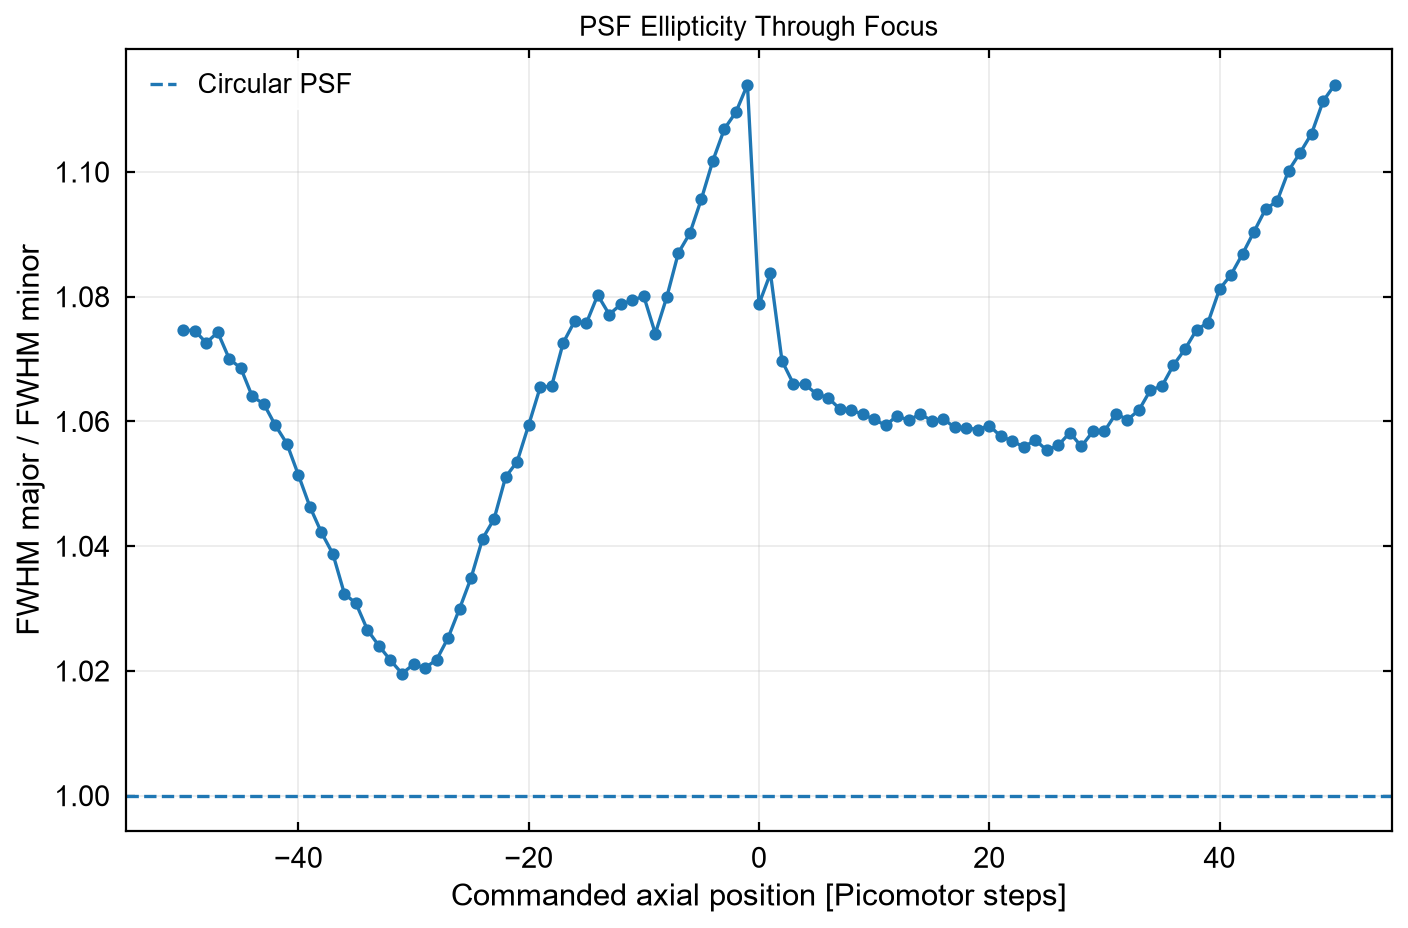

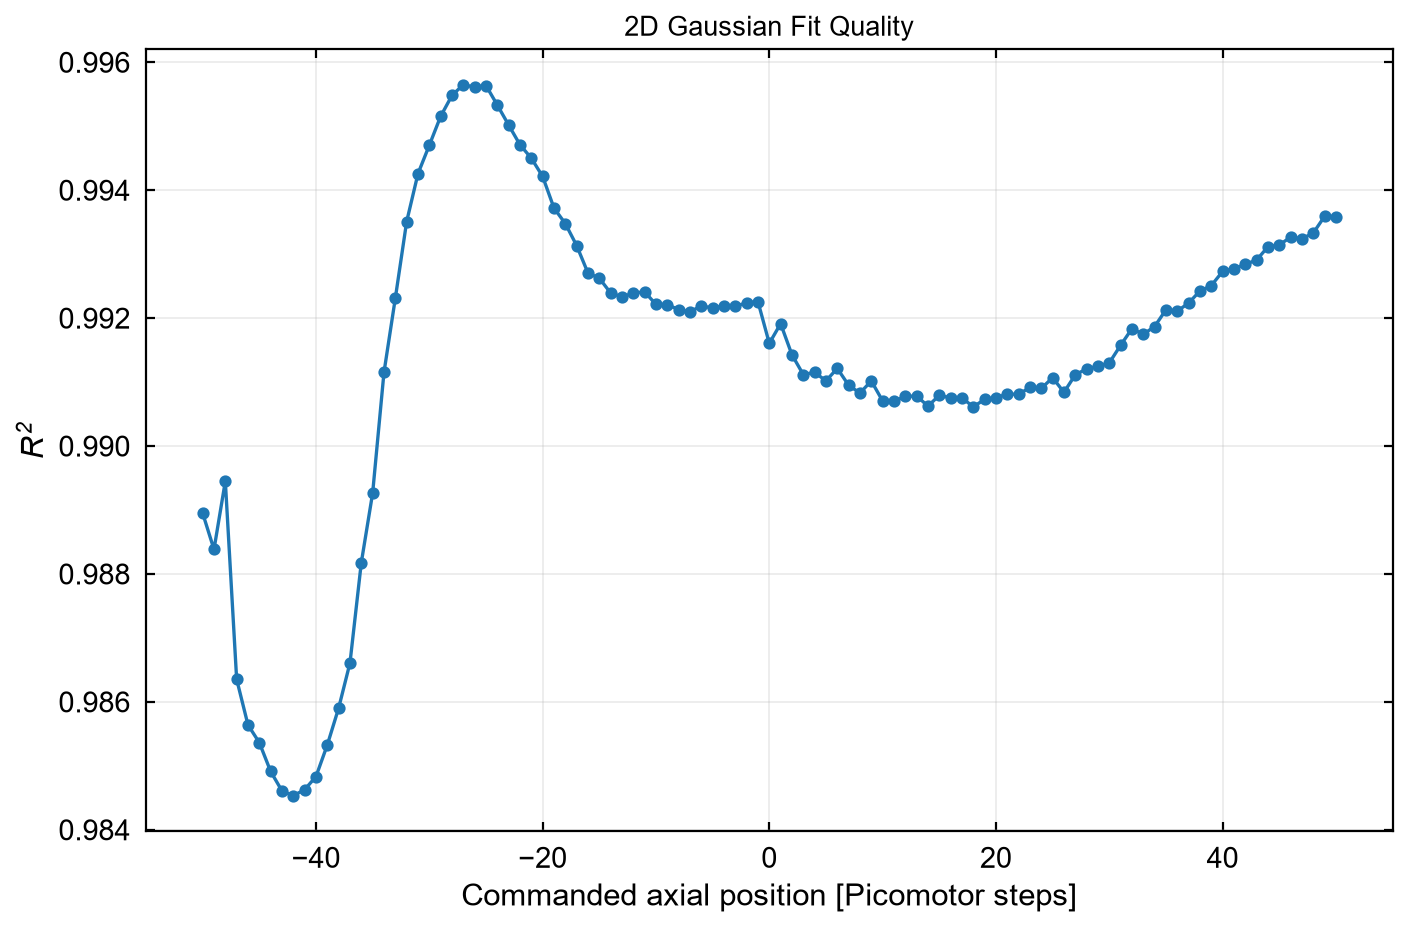

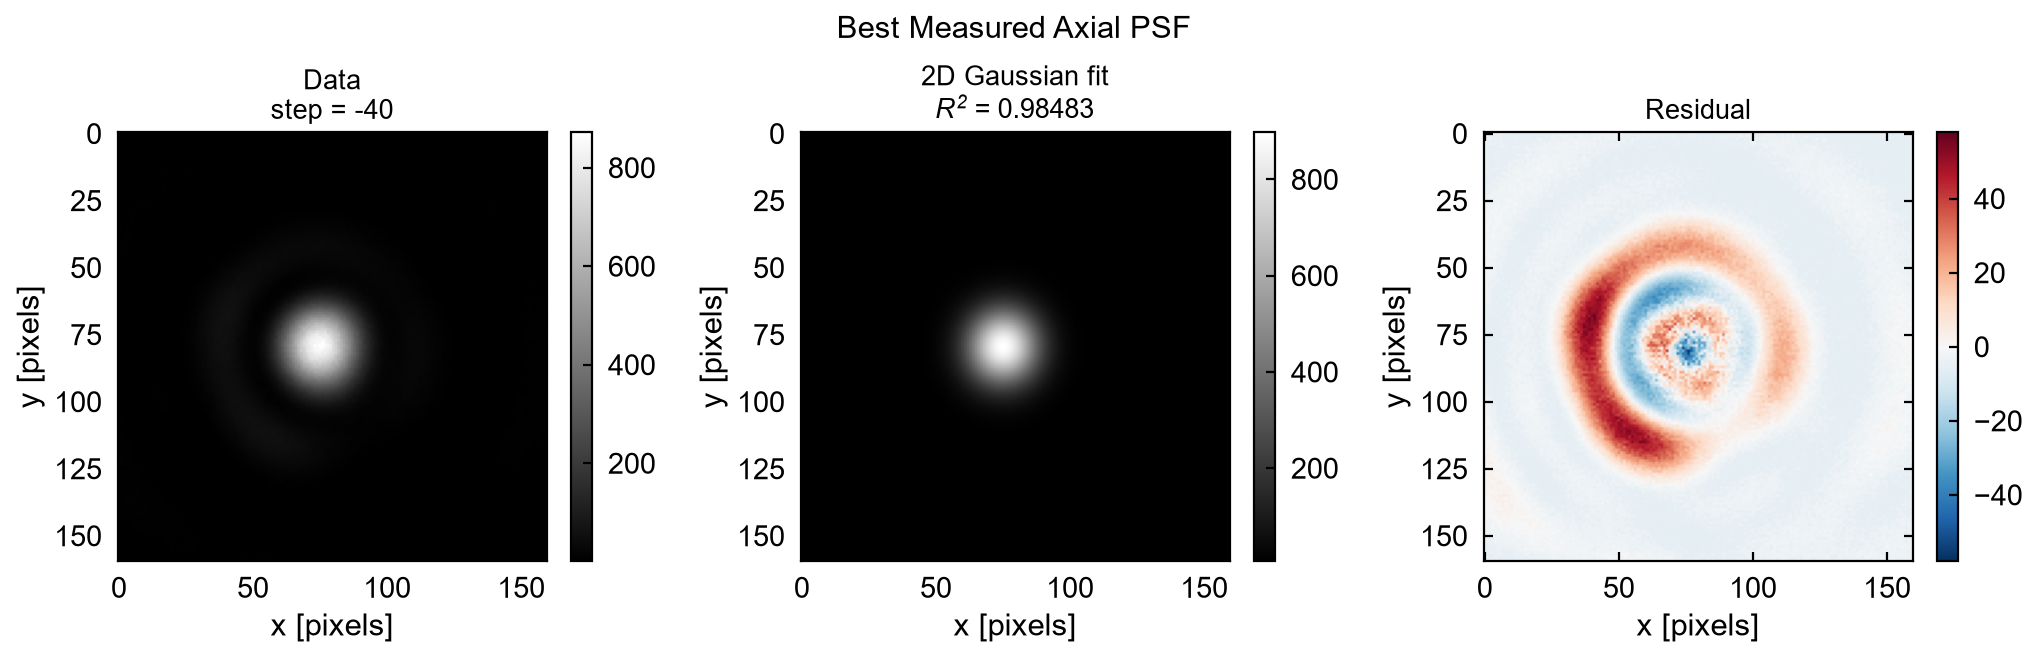

In [7]:
# ============================================================
# AXIAL PSF ANALYSIS — ZEISS OBJECTIVE TEST
#
# Expected files:
#   -50.tif, -49.tif, ..., -1.tif, 0.tif,
#    1.tif, ..., 49.tif, 50.tif
#
# Run this script from:
# C:\Users\admin\Desktop\Projects\Zeiss test\PSFs\axial scan
#
# Dependencies:
#   pip install numpy scipy matplotlib pandas tifffile
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile

from scipy.optimize import least_squares


# ============================================================
# USER SETTINGS
# ============================================================

FOLDER = Path(
    r"C:\Users\admin\Desktop\Projects\Zeiss test\PSFs\axial scan"
)

# Approximate blob center in full camera image:
X_GUESS = 550
Y_GUESS = 400

# Half-width of fitting ROI.
# ROI will therefore be 2*ROI_HALF x 2*ROI_HALF pixels.
ROI_HALF = 80

# Nominal Picomotor displacement.
# IMPORTANT: use this only as a nominal conversion.
STEP_UM_NOMINAL = 0.030       # 30 nm / commanded step

# Camera pixel size
CAMERA_PIXEL_UM = 3.45

# Set this once you have a reliable measured magnification.
# Example: MAGNIFICATION = 184.0
MAGNIFICATION = None

# Set True if you want all figures saved automatically
SAVE_FIGURES = True


# ============================================================
# 2D ELLIPTICAL GAUSSIAN MODEL
# ============================================================

def gaussian_2d(params, x, y):
    """
    Elliptical rotated Gaussian + constant background.

    params =
        [background, amplitude, x0, y0, sigma_x, sigma_y, theta]
    """

    bg, amp, x0, y0, sx, sy, theta = params

    ct = np.cos(theta)
    st = np.sin(theta)

    xp = (x - x0) * ct + (y - y0) * st
    yp = -(x - x0) * st + (y - y0) * ct

    g = bg + amp * np.exp(
        -0.5 * ((xp / sx)**2 + (yp / sy)**2)
    )

    return g


def estimate_initial_parameters(img):
    """Generate robust starting parameters for the Gaussian fit."""

    h, w = img.shape

    # Estimate background from ROI edges
    edge = np.concatenate([
        img[:5, :].ravel(),
        img[-5:, :].ravel(),
        img[:, :5].ravel(),
        img[:, -5:].ravel()
    ])

    bg = np.median(edge)

    signal = img.astype(float) - bg
    signal = np.clip(signal, 0, None)

    yy, xx = np.indices(img.shape)

    total = signal.sum()

    if total <= 0:
        return [
            bg,
            max(float(img.max() - bg), 1),
            w / 2,
            h / 2,
            10,
            10,
            0
        ]

    # Use only reasonably bright pixels for the initial moment estimate.
    threshold = 0.1 * signal.max()

    weights = np.where(signal > threshold, signal, 0)

    if weights.sum() <= 0:
        weights = signal

    norm = weights.sum()

    x0 = (weights * xx).sum() / norm
    y0 = (weights * yy).sum() / norm

    dx = xx - x0
    dy = yy - y0

    var_x = (weights * dx**2).sum() / norm
    var_y = (weights * dy**2).sum() / norm
    cov_xy = (weights * dx * dy).sum() / norm

    cov = np.array([
        [var_x, cov_xy],
        [cov_xy, var_y]
    ])

    eigvals, eigvecs = np.linalg.eigh(cov)

    eigvals = np.clip(eigvals, 1.0, None)

    # Principal-axis widths
    order = np.argsort(eigvals)[::-1]

    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]

    s_major = np.sqrt(eigvals[0])
    s_minor = np.sqrt(eigvals[1])

    # Prevent pathological initial guesses
    s_major = np.clip(s_major, 2, 30)
    s_minor = np.clip(s_minor, 2, 30)

    vx, vy = eigvecs[:, 0]
    theta = np.arctan2(vy, vx)

    amp = float(signal.max())

    return [
        bg,
        amp,
        x0,
        y0,
        s_major,
        s_minor,
        theta
    ]


def fit_gaussian_2d(img):
    """Robust 2D Gaussian fit."""

    img = img.astype(float)

    h, w = img.shape

    yy, xx = np.indices(img.shape)

    p0 = estimate_initial_parameters(img)

    # Noise scale to make robust loss behave sensibly
    p05, p95 = np.percentile(img, [5, 95])
    scale = max(p95 - p05, 1.0)

    def residuals(params):
        model = gaussian_2d(params, xx, yy)
        return ((model - img) / scale).ravel()

    lower = [
        -np.inf,        # background
        0,              # amplitude
        0,              # x0
        0,              # y0
        0.5,            # sx
        0.5,            # sy
        -np.pi
    ]

    upper = [
        np.inf,
        np.inf,
        w - 1,
        h - 1,
        ROI_HALF,
        ROI_HALF,
        np.pi
    ]

    fit = least_squares(
        residuals,
        p0,
        bounds=(lower, upper),
        loss="soft_l1",
        f_scale=1.0,
        max_nfev=3000
    )

    p = fit.x

    model = gaussian_2d(p, xx, yy)

    # Fit quality
    ss_res = np.sum((img - model)**2)
    ss_tot = np.sum((img - np.mean(img))**2)

    r_squared = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return p, model, r_squared


# ============================================================
# WIDTH-vs-Z MODEL
# ============================================================

def width_model(params, z):
    """
    Phenomenological Gaussian-beam-like width curve:

        w(z) = w0 * sqrt(1 + ((z-z0)/zR)^2)

    z is in commanded Picomotor steps.
    """

    w0, z0, zR = params

    return w0 * np.sqrt(
        1 + ((z - z0) / zR)**2
    )


def fit_width_curve(z, width):
    """Robust fit of PSF width versus commanded axial step."""

    z = np.asarray(z)
    width = np.asarray(width)

    good = np.isfinite(z) & np.isfinite(width)

    z_fit = z[good]
    w_fit = width[good]

    imin = np.argmin(w_fit)

    p0 = [
        w_fit[imin],       # minimum width
        z_fit[imin],       # approximate best focus
        20                 # characteristic axial width in steps
    ]

    def residuals(params):
        return width_model(params, z_fit) - w_fit

    result = least_squares(
        residuals,
        p0,
        bounds=(
            [0, -70, 0.5],
            [np.inf, 70, 500]
        ),
        loss="soft_l1",
        f_scale=0.5
    )

    return result.x


# ============================================================
# FIND AND SORT FILES
# ============================================================

files = []

for f in FOLDER.glob("*.tif"):
    try:
        step = int(f.stem)
        files.append((step, f))
    except ValueError:
        pass

files.sort(key=lambda item: item[0])

steps_found = [x[0] for x in files]

print(f"Found {len(files)} TIFF files.")
print(f"Step range: {min(steps_found)} to {max(steps_found)}")

expected = set(range(-50, 51))
missing = sorted(expected - set(steps_found))

if missing:
    print("WARNING: missing steps:")
    print(missing)
else:
    print("All 101 expected positions are present.")


# ============================================================
# ANALYZE EACH IMAGE
# ============================================================

results = []

FWHM_FACTOR = 2 * np.sqrt(2 * np.log(2))

for i, (step, filename) in enumerate(files):

    img = tifffile.imread(filename)

    # Handle accidental multi-channel TIFFs
    if img.ndim > 2:
        img = np.squeeze(img)

    if img.ndim != 2:
        raise RuntimeError(
            f"{filename.name} has unexpected shape {img.shape}"
        )

    # Fixed fitting ROI around approximate blob location
    x1 = max(0, X_GUESS - ROI_HALF)
    x2 = min(img.shape[1], X_GUESS + ROI_HALF)

    y1 = max(0, Y_GUESS - ROI_HALF)
    y2 = min(img.shape[0], Y_GUESS + ROI_HALF)

    roi = img[y1:y2, x1:x2]

    params, model, r2 = fit_gaussian_2d(roi)

    bg, amp, x0, y0, sx, sy, theta = params

    # Convert local centroid to full-camera coordinates
    x_global = x1 + x0
    y_global = y1 + y0

    # Sort widths into major/minor
    sigma_major = max(sx, sy)
    sigma_minor = min(sx, sy)

    fwhm_major = FWHM_FACTOR * sigma_major
    fwhm_minor = FWHM_FACTOR * sigma_minor

    # Very useful scalar focus metric
    fwhm_geo = np.sqrt(fwhm_major * fwhm_minor)

    ellipticity = fwhm_major / fwhm_minor

    # Integrated fitted Gaussian signal
    integrated_signal = (
        amp * 2 * np.pi * sx * sy
    )

    # Nominal axial coordinate
    z_nominal_um = step * STEP_UM_NOMINAL

    results.append({
        "step": step,
        "z_nominal_um": z_nominal_um,

        "x_centroid_px": x_global,
        "y_centroid_px": y_global,

        "sigma_1_px": sx,
        "sigma_2_px": sy,

        "fwhm_major_px": fwhm_major,
        "fwhm_minor_px": fwhm_minor,
        "fwhm_geo_px": fwhm_geo,

        "ellipticity": ellipticity,

        "amplitude": amp,
        "background": bg,
        "integrated_signal": integrated_signal,

        "theta_rad": theta,
        "R2": r2,

        "filename": filename.name
    })

    print(
        f"{step:+3d}   "
        f"x={x_global:8.3f}   "
        f"y={y_global:8.3f}   "
        f"FWHMgeo={fwhm_geo:7.3f} px   "
        f"ellip={ellipticity:5.3f}   "
        f"R²={r2:7.5f}"
    )


df = pd.DataFrame(results)

df.sort_values("step", inplace=True)
df.reset_index(drop=True, inplace=True)


# ============================================================
# OPTIONAL LATERAL OBJECT-PLANE CONVERSION
# ============================================================

if MAGNIFICATION is not None:

    object_pixel_um = CAMERA_PIXEL_UM / MAGNIFICATION

    df["fwhm_major_object_um"] = (
        df["fwhm_major_px"] * object_pixel_um
    )

    df["fwhm_minor_object_um"] = (
        df["fwhm_minor_px"] * object_pixel_um
    )

    df["fwhm_geo_object_um"] = (
        df["fwhm_geo_px"] * object_pixel_um
    )


# ============================================================
# FIT AXIAL WIDTH CURVE
# ============================================================

z_step = df["step"].to_numpy()
width_geo = df["fwhm_geo_px"].to_numpy()

w0_fit, z0_fit, zR_fit = fit_width_curve(
    z_step,
    width_geo
)

z_dense = np.linspace(
    z_step.min(),
    z_step.max(),
    1000
)

width_dense = width_model(
    [w0_fit, z0_fit, zR_fit],
    z_dense
)


# ============================================================
# SIMPLE EXPERIMENTAL MINIMUM
# ============================================================

idx_min = df["fwhm_geo_px"].idxmin()

best_data = df.loc[idx_min]

best_step_data = best_data["step"]
best_width_data = best_data["fwhm_geo_px"]


# ============================================================
# RESULTS
# ============================================================

print("\n")
print("=" * 65)
print("AXIAL PSF RESULTS")
print("=" * 65)

print(
    f"Narrowest measured frame : "
    f"{int(best_step_data):+d} steps"
)

print(
    f"Measured minimum FWHM_geo : "
    f"{best_width_data:.3f} pixels"
)

print()
print("Continuous width-curve fit:")

print(
    f"Best-focus position        : "
    f"{z0_fit:+.3f} steps"
)

print(
    f"Minimum fitted FWHM        : "
    f"{w0_fit:.3f} pixels"
)

print(
    f"Characteristic z_R         : "
    f"{zR_fit:.3f} steps"
)

print()
print("Using 30 nm/step NOMINALLY:")

print(
    f"Best focus relative to 0   : "
    f"{z0_fit * STEP_UM_NOMINAL:+.4f} um"
)

print(
    f"Characteristic z_R         : "
    f"{zR_fit * STEP_UM_NOMINAL:.4f} um"
)

print("=" * 65)

print(
    "\nIMPORTANT: the micron values above assume exactly "
    "30 nm per Picomotor step and therefore should be regarded "
    "as NOMINAL, not calibrated."
)


# ============================================================
# SAVE TABLE
# ============================================================

csv_name = FOLDER / "axial_scan_analysis.csv"

df.to_csv(csv_name, index=False)

print(f"\nSaved table:\n{csv_name}")


# ============================================================
# FIGURE 1 — WIDTH VS AXIAL POSITION
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    df["step"],
    df["fwhm_geo_px"],
    s=35,
    label="Measured"
)

ax.plot(
    z_dense,
    width_dense,
    linewidth=2,
    label="Width fit"
)

ax.axvline(
    z0_fit,
    linestyle="--",
    label=f"Best focus = {z0_fit:+.2f} steps"
)

ax.set_xlabel("Commanded axial position [Picomotor steps]")
ax.set_ylabel("Geometric-mean FWHM [camera pixels]")

ax.set_title("Axial PSF — Focus Curve")

ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

if SAVE_FIGURES:
    fig.savefig(
        FOLDER / "01_axial_focus_curve.png",
        dpi=200
    )


# ============================================================
# FIGURE 2 — BOTH PRINCIPAL WIDTHS
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    df["step"],
    df["fwhm_major_px"],
    "o-",
    markersize=4,
    label="Major-axis FWHM"
)

ax.plot(
    df["step"],
    df["fwhm_minor_px"],
    "o-",
    markersize=4,
    label="Minor-axis FWHM"
)

ax.axvline(
    z0_fit,
    linestyle="--",
    label="Fitted best focus"
)

ax.set_xlabel("Commanded axial position [Picomotor steps]")
ax.set_ylabel("FWHM [camera pixels]")

ax.set_title("PSF Major and Minor Widths")

ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

if SAVE_FIGURES:
    fig.savefig(
        FOLDER / "02_major_minor_widths.png",
        dpi=200
    )


# ============================================================
# FIGURE 3 — CENTROID MOTION
# ============================================================

x_ref = df.loc[df["step"] == 0, "x_centroid_px"].iloc[0]
y_ref = df.loc[df["step"] == 0, "y_centroid_px"].iloc[0]

dx = df["x_centroid_px"] - x_ref
dy = df["y_centroid_px"] - y_ref

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    df["step"],
    dx,
    "o-",
    markersize=4,
    label="Δx"
)

ax.plot(
    df["step"],
    dy,
    "o-",
    markersize=4,
    label="Δy"
)

ax.axhline(
    0,
    linewidth=1,
    linestyle="--"
)

ax.set_xlabel("Commanded axial position [Picomotor steps]")
ax.set_ylabel("Centroid displacement [camera pixels]")

ax.set_title(
    "Transverse Motion During Axial Scan"
)

ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

if SAVE_FIGURES:
    fig.savefig(
        FOLDER / "03_centroid_motion.png",
        dpi=200
    )


# ============================================================
# FIGURE 4 — PEAK AND INTEGRATED SIGNAL
# ============================================================

peak_norm = df["amplitude"] / df["amplitude"].max()

power_norm = (
    df["integrated_signal"]
    / np.median(df["integrated_signal"])
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    df["step"],
    peak_norm,
    "o-",
    markersize=4,
    label="Peak intensity"
)

ax.plot(
    df["step"],
    power_norm,
    "o-",
    markersize=4,
    label="Integrated fitted signal"
)

ax.set_xlabel("Commanded axial position [Picomotor steps]")
ax.set_ylabel("Normalized signal")

ax.set_title("PSF Intensity During Axial Scan")

ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

if SAVE_FIGURES:
    fig.savefig(
        FOLDER / "04_intensity.png",
        dpi=200
    )


# ============================================================
# FIGURE 5 — ELLIPTICITY
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    df["step"],
    df["ellipticity"],
    "o-",
    markersize=4
)

ax.axhline(
    1,
    linestyle="--",
    label="Circular PSF"
)

ax.set_xlabel("Commanded axial position [Picomotor steps]")
ax.set_ylabel("FWHM major / FWHM minor")

ax.set_title("PSF Ellipticity Through Focus")

ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

if SAVE_FIGURES:
    fig.savefig(
        FOLDER / "05_ellipticity.png",
        dpi=200
    )


# ============================================================
# FIGURE 6 — FIT QUALITY
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    df["step"],
    df["R2"],
    "o-",
    markersize=4
)

ax.set_xlabel("Commanded axial position [Picomotor steps]")
ax.set_ylabel(r"$R^2$")

ax.set_title("2D Gaussian Fit Quality")

ax.grid(alpha=0.25)

fig.tight_layout()

if SAVE_FIGURES:
    fig.savefig(
        FOLDER / "06_fit_quality.png",
        dpi=200
    )


# ============================================================
# FIGURE 7 — SHOW THE EXPERIMENTALLY NARROWEST PSF
# ============================================================

best_file = FOLDER / best_data["filename"]

best_img = tifffile.imread(best_file)

x1 = X_GUESS - ROI_HALF
x2 = X_GUESS + ROI_HALF

y1 = Y_GUESS - ROI_HALF
y2 = Y_GUESS + ROI_HALF

best_roi = best_img[y1:y2, x1:x2]

params, best_model, best_r2 = fit_gaussian_2d(best_roi)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(13, 4)
)

im0 = axes[0].imshow(
    best_roi,
    cmap="gray",
    origin="upper"
)

axes[0].set_title(
    f"Data\nstep = {int(best_step_data):+d}"
)

plt.colorbar(
    im0,
    ax=axes[0],
    fraction=0.046
)


im1 = axes[1].imshow(
    best_model,
    cmap="gray",
    origin="upper"
)

axes[1].set_title(
    f"2D Gaussian fit\n$R^2$ = {best_r2:.5f}"
)

plt.colorbar(
    im1,
    ax=axes[1],
    fraction=0.046
)


residual = best_roi.astype(float) - best_model

lim = np.max(np.abs(residual))

im2 = axes[2].imshow(
    residual,
    cmap="RdBu_r",
    origin="upper",
    vmin=-lim,
    vmax=lim
)

axes[2].set_title("Residual")

plt.colorbar(
    im2,
    ax=axes[2],
    fraction=0.046
)

for ax in axes:
    ax.set_xlabel("x [pixels]")
    ax.set_ylabel("y [pixels]")

fig.suptitle(
    "Best Measured Axial PSF",
    fontsize=14
)

fig.tight_layout()

if SAVE_FIGURES:
    fig.savefig(
        FOLDER / "07_best_PSF_fit.png",
        dpi=200
    )


plt.show()

Found 101 TIFF files.
Full available step range: -50 to 50
Analyzing only steps -50 through -25.
Number of images used: 26
-50   x= 548.962   y= 401.144   FWHMgeo= 23.084 px   ellip= 1.075   R²=0.98895
-49   x= 549.157   y= 400.940   FWHMgeo= 22.941 px   ellip= 1.075   R²=0.98838
-48   x= 548.032   y= 401.711   FWHMgeo= 23.268 px   ellip= 1.073   R²=0.98945
-47   x= 548.024   y= 400.555   FWHMgeo= 22.623 px   ellip= 1.074   R²=0.98635
-46   x= 548.320   y= 400.188   FWHMgeo= 22.532 px   ellip= 1.070   R²=0.98564
-45   x= 546.603   y= 400.384   FWHMgeo= 22.472 px   ellip= 1.069   R²=0.98536
-44   x= 546.860   y= 400.091   FWHMgeo= 22.401 px   ellip= 1.064   R²=0.98491
-43   x= 545.713   y= 400.096   FWHMgeo= 22.360 px   ellip= 1.063   R²=0.98461
-42   x= 546.715   y= 399.604   FWHMgeo= 22.311 px   ellip= 1.059   R²=0.98453
-41   x= 544.755   y= 399.829   FWHMgeo= 22.303 px   ellip= 1.056   R²=0.98463
-40   x= 545.046   y= 399.424   FWHMgeo= 22.289 px   ellip= 1.051   R²=0.98483
-39   x=

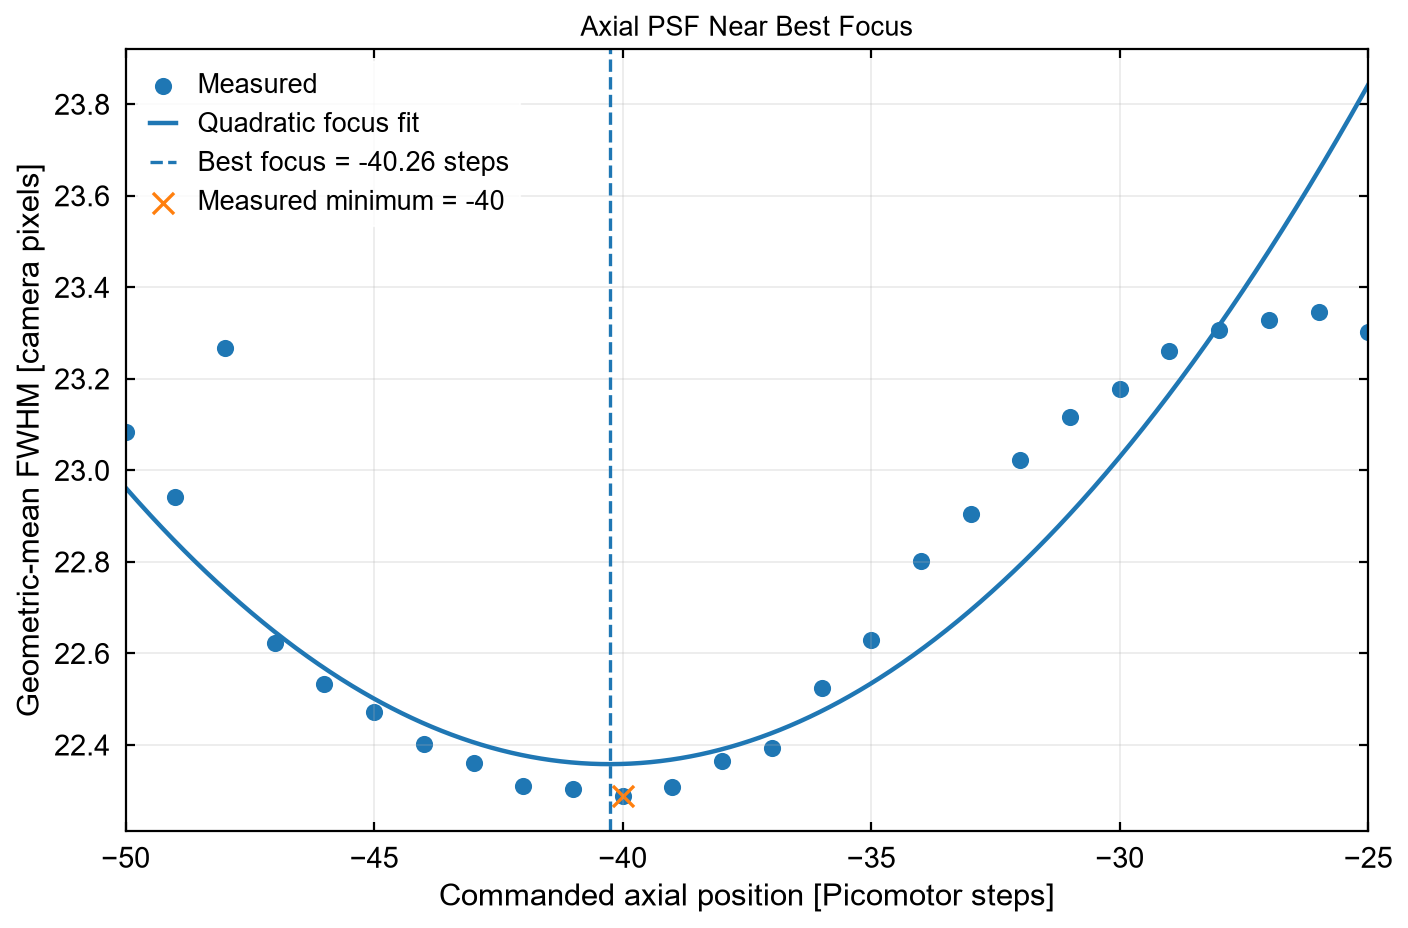

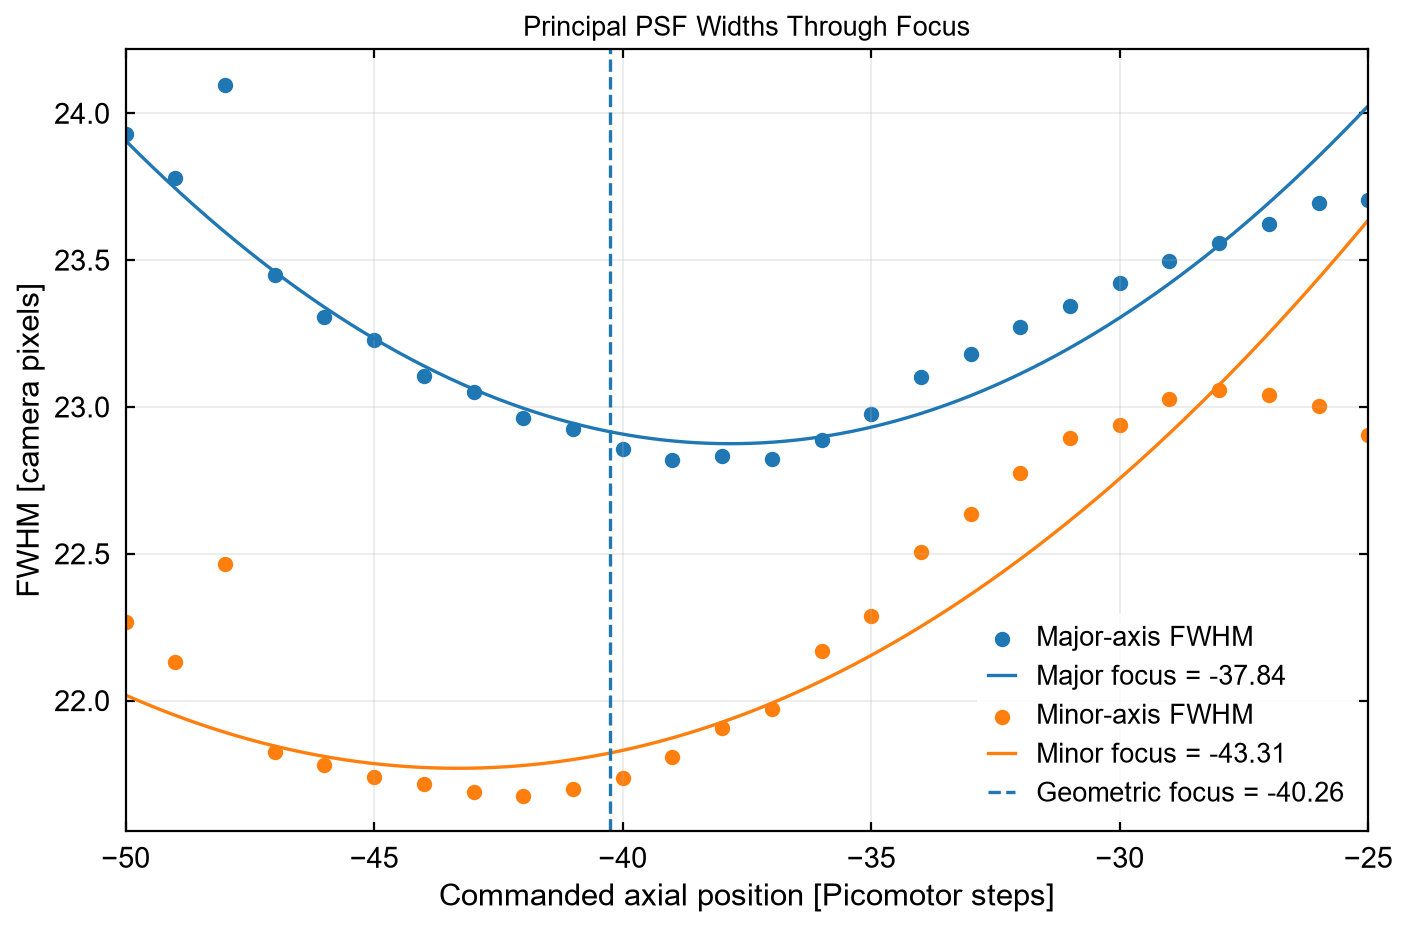

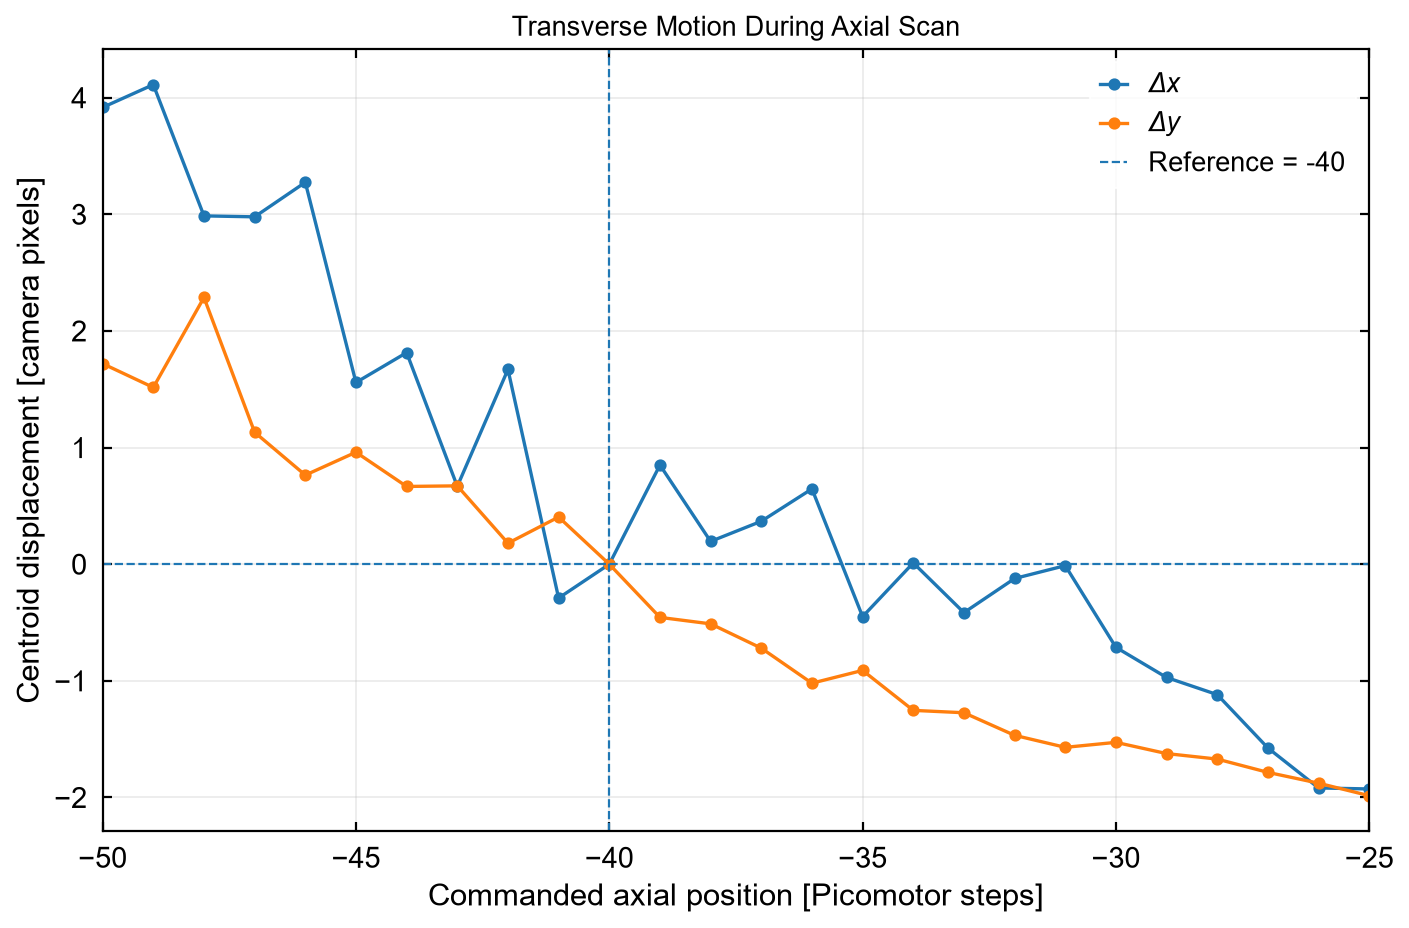

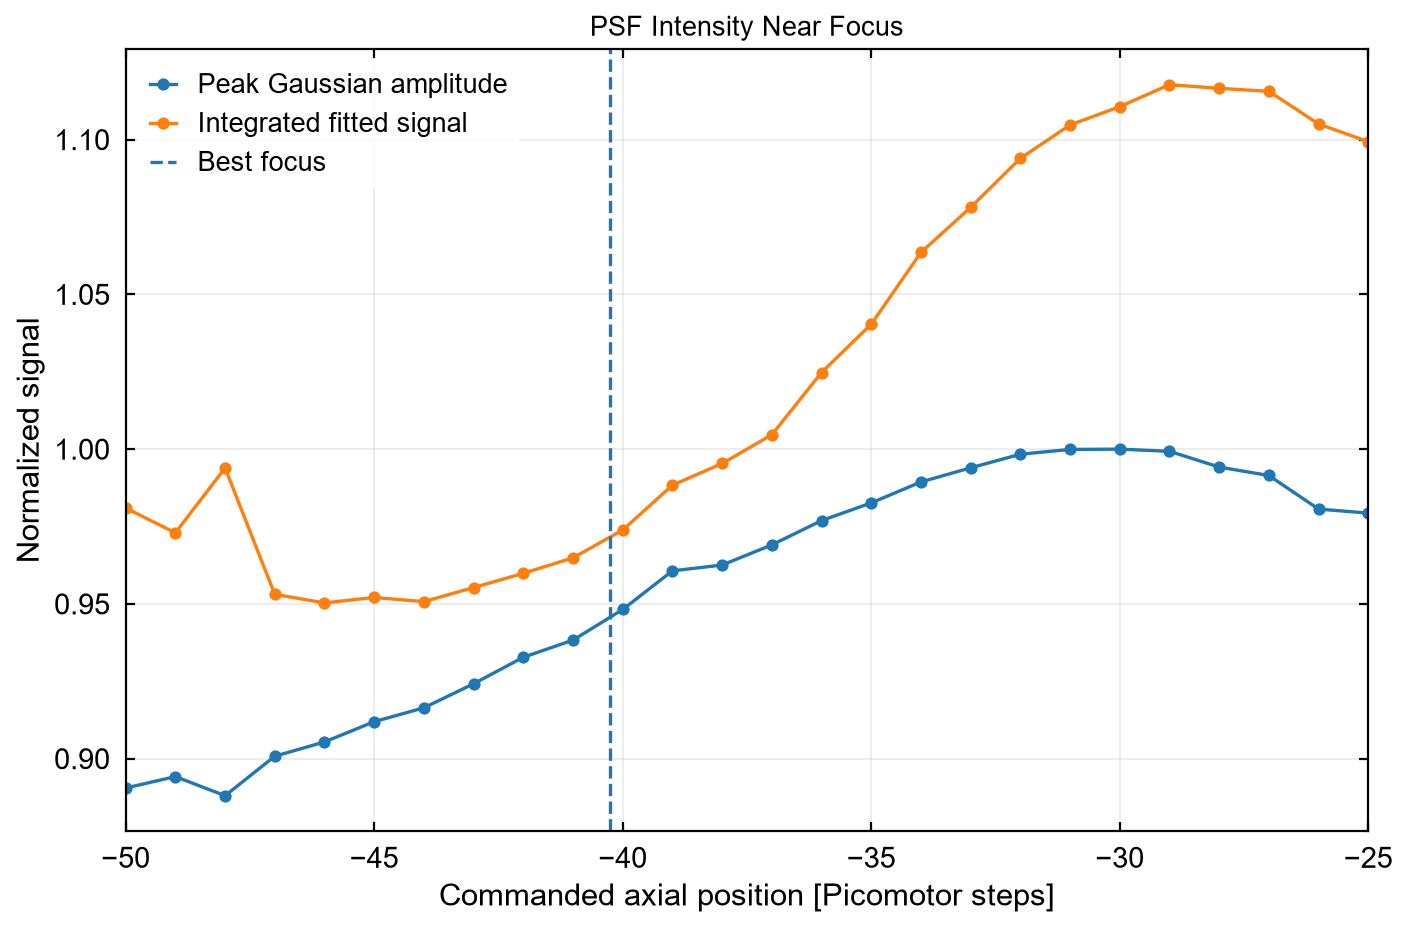

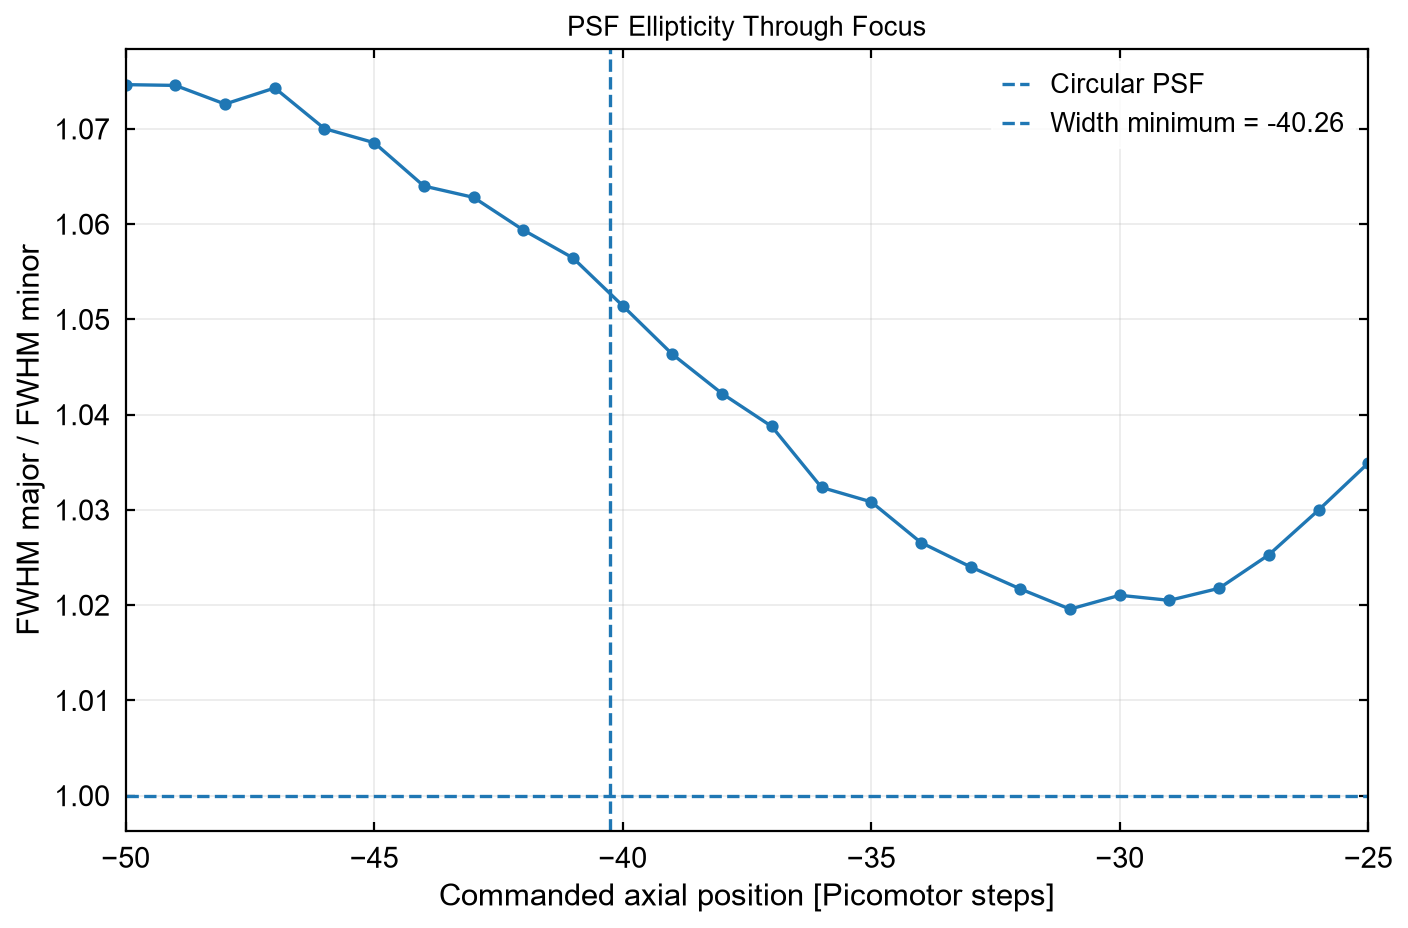

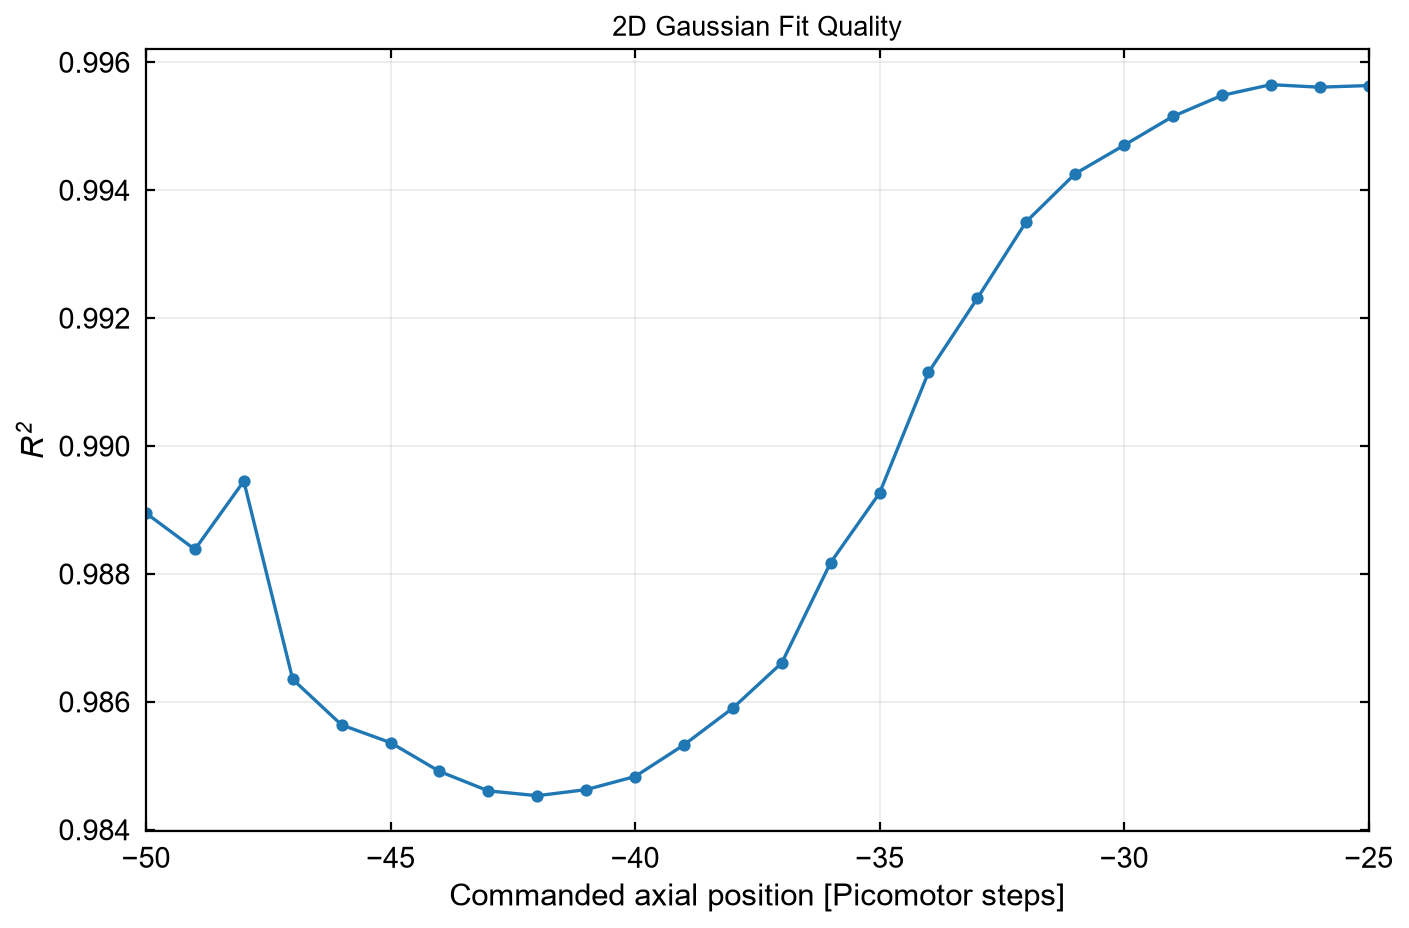

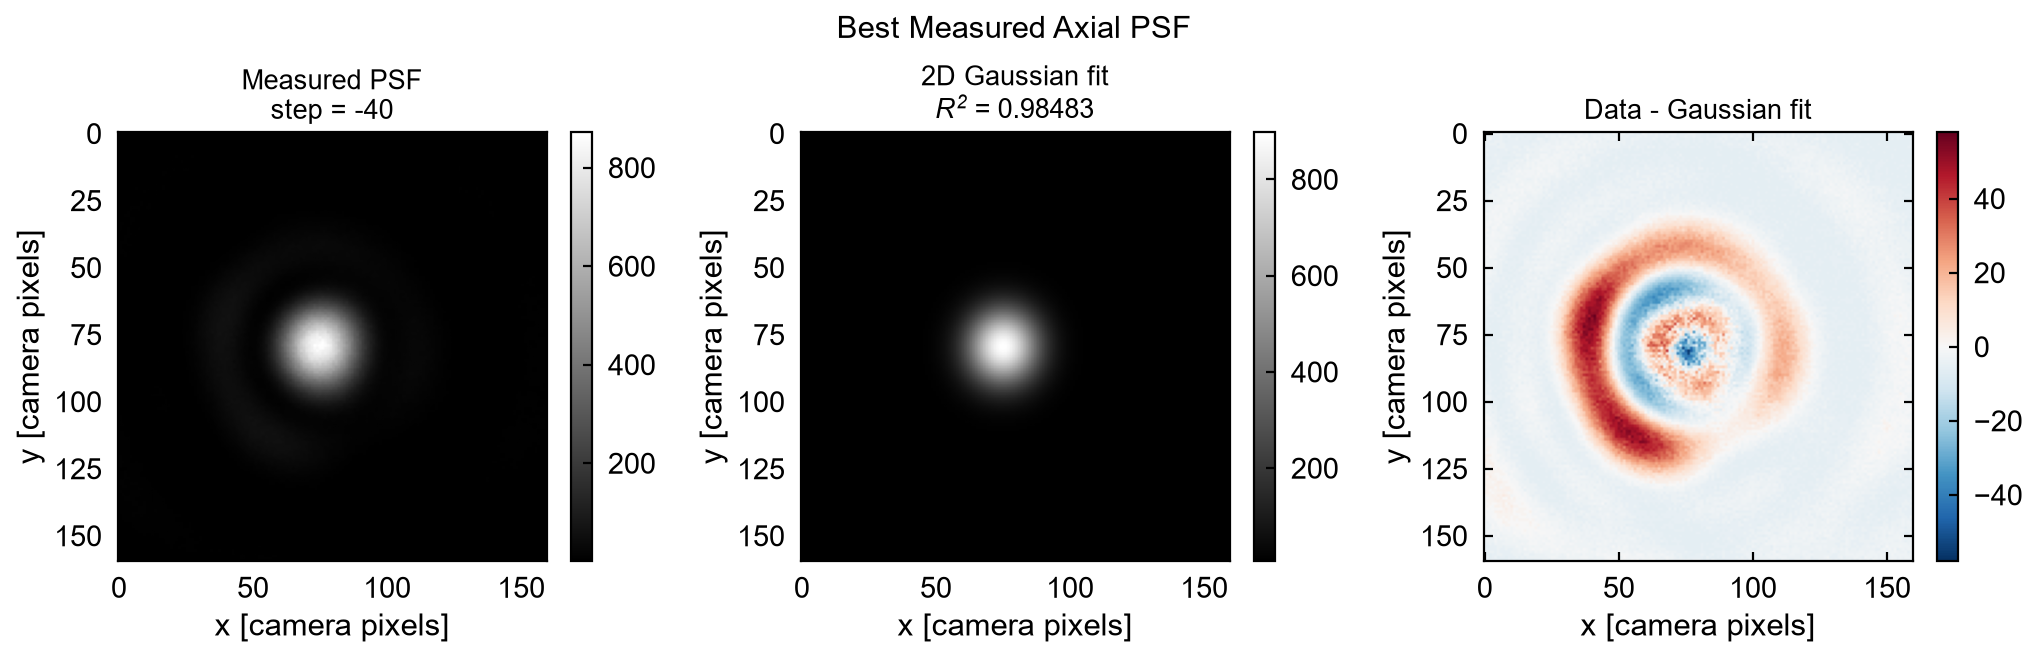

In [8]:
# ============================================================
# AXIAL PSF ANALYSIS — ZEISS OBJECTIVE TEST
#
# Focus-region analysis:
#       Picomotor steps -50 ... -25
#
# Each image is fitted with a rotated elliptical 2D Gaussian.
#
# Extracted quantities:
#   - x/y centroid
#   - major/minor FWHM
#   - geometric-mean FWHM
#   - ellipticity
#   - peak signal
#   - integrated fitted signal
#   - Gaussian-fit R^2
#
# Focus is determined locally using:
#
#       FWHM(z) = FWHM_0 + a (z-z0)^2
#
# rather than trying to extract a physical Rayleigh range from
# the uncalibrated Picomotor motion.
#
# Dependencies:
#   pip install numpy scipy matplotlib pandas tifffile
# ============================================================


from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile

from scipy.optimize import least_squares


# ============================================================
# USER SETTINGS
# ============================================================

FOLDER = Path(
    r"C:\Users\admin\Desktop\Projects\Zeiss test\PSFs\axial scan"
)

# Approximate PSF position in full camera image
X_GUESS = 550
Y_GUESS = 400

# ROI:
# total ROI size = 2*ROI_HALF x 2*ROI_HALF
ROI_HALF = 80

# ------------------------------------------------------------
# REGION THAT WE ACTUALLY WANT TO ANALYZE
# ------------------------------------------------------------

STEP_MIN = -50
STEP_MAX = -25

# ------------------------------------------------------------
# Nominal Picomotor conversion
#
# Do NOT treat this as a calibrated displacement.
# ------------------------------------------------------------

STEP_UM_NOMINAL = 0.030       # 30 nm / commanded step

# Camera pixel size
CAMERA_PIXEL_UM = 3.45

# Set this later if you want object-plane transverse widths.
# Example:
# MAGNIFICATION = 184.0
MAGNIFICATION = None

SAVE_FIGURES = True

# Print every individual Gaussian fit
PRINT_EACH_FRAME = True


# ============================================================
# 2D ROTATED ELLIPTICAL GAUSSIAN
# ============================================================

def gaussian_2d(params, x, y):

    """
    Rotated elliptical Gaussian + constant background.

    params =
        background
        amplitude
        x0
        y0
        sigma_x
        sigma_y
        theta
    """

    bg, amp, x0, y0, sx, sy, theta = params

    ct = np.cos(theta)
    st = np.sin(theta)

    xp = (x - x0) * ct + (y - y0) * st
    yp = -(x - x0) * st + (y - y0) * ct

    return bg + amp * np.exp(
        -0.5 * (
            (xp / sx)**2
            +
            (yp / sy)**2
        )
    )


# ============================================================
# INITIAL PARAMETER ESTIMATION
# ============================================================

def estimate_initial_parameters(img):

    """
    Estimate Gaussian parameters using image moments.
    """

    h, w = img.shape

    # --------------------------------------------------------
    # Estimate background from outer 5 pixels of ROI
    # --------------------------------------------------------

    edge = np.concatenate([
        img[:5, :].ravel(),
        img[-5:, :].ravel(),
        img[:, :5].ravel(),
        img[:, -5:].ravel()
    ])

    bg = np.median(edge)

    signal = img.astype(float) - bg
    signal = np.clip(signal, 0, None)

    yy, xx = np.indices(img.shape)

    total = signal.sum()

    if total <= 0:

        return [
            bg,
            max(float(img.max() - bg), 1),
            w / 2,
            h / 2,
            10,
            10,
            0
        ]

    # --------------------------------------------------------
    # Use bright pixels to get stable initial moments
    # --------------------------------------------------------

    threshold = 0.1 * signal.max()

    weights = np.where(
        signal > threshold,
        signal,
        0
    )

    if weights.sum() <= 0:
        weights = signal

    norm = weights.sum()

    x0 = (weights * xx).sum() / norm
    y0 = (weights * yy).sum() / norm

    dx = xx - x0
    dy = yy - y0

    var_x = (weights * dx**2).sum() / norm
    var_y = (weights * dy**2).sum() / norm
    cov_xy = (weights * dx * dy).sum() / norm

    covariance = np.array([
        [var_x, cov_xy],
        [cov_xy, var_y]
    ])

    eigvals, eigvecs = np.linalg.eigh(covariance)

    eigvals = np.clip(
        eigvals,
        1.0,
        None
    )

    # largest first
    order = np.argsort(eigvals)[::-1]

    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]

    sigma_major = np.sqrt(eigvals[0])
    sigma_minor = np.sqrt(eigvals[1])

    sigma_major = np.clip(
        sigma_major,
        2,
        30
    )

    sigma_minor = np.clip(
        sigma_minor,
        2,
        30
    )

    vx, vy = eigvecs[:, 0]

    theta = np.arctan2(
        vy,
        vx
    )

    amp = float(signal.max())

    return [
        bg,
        amp,
        x0,
        y0,
        sigma_major,
        sigma_minor,
        theta
    ]


# ============================================================
# ROBUST 2D GAUSSIAN FIT
# ============================================================

def fit_gaussian_2d(img):

    img = img.astype(float)

    h, w = img.shape

    yy, xx = np.indices(img.shape)

    p0 = estimate_initial_parameters(img)

    # --------------------------------------------------------
    # Robust scale for least_squares
    # --------------------------------------------------------

    p05, p95 = np.percentile(
        img,
        [5, 95]
    )

    scale = max(
        p95 - p05,
        1.0
    )

    def residuals(params):

        model = gaussian_2d(
            params,
            xx,
            yy
        )

        return (
            (model - img) / scale
        ).ravel()

    lower = [
        -np.inf,       # background
        0,             # amplitude
        0,             # x0
        0,             # y0
        0.5,           # sigma x
        0.5,           # sigma y
        -np.pi
    ]

    upper = [
        np.inf,
        np.inf,
        w - 1,
        h - 1,
        ROI_HALF,
        ROI_HALF,
        np.pi
    ]

    fit = least_squares(
        residuals,
        p0,
        bounds=(lower, upper),
        loss="soft_l1",
        f_scale=1.0,
        max_nfev=3000
    )

    params = fit.x

    model = gaussian_2d(
        params,
        xx,
        yy
    )

    # --------------------------------------------------------
    # R^2
    # --------------------------------------------------------

    ss_res = np.sum(
        (img - model)**2
    )

    ss_tot = np.sum(
        (img - np.mean(img))**2
    )

    if ss_tot > 0:

        r_squared = (
            1
            -
            ss_res / ss_tot
        )

    else:

        r_squared = np.nan

    return params, model, r_squared


# ============================================================
# LOCAL QUADRATIC FOCUS MODEL
# ============================================================

def quadratic_focus(params, z):

    """

        width(z) = width_0 + a * (z-z0)^2

    """

    width0, z0, curvature = params

    return (
        width0
        +
        curvature * (z - z0)**2
    )


def fit_quadratic_focus(z, width):

    z = np.asarray(
        z,
        dtype=float
    )

    width = np.asarray(
        width,
        dtype=float
    )

    good = (
        np.isfinite(z)
        &
        np.isfinite(width)
    )

    z = z[good]
    width = width[good]

    i_min = np.argmin(width)

    p0 = [
        width[i_min],
        z[i_min],
        0.005
    ]

    def residuals(params):

        return (
            quadratic_focus(params, z)
            -
            width
        )

    fit = least_squares(
        residuals,
        p0,
        bounds=(
            [
                0,
                STEP_MIN,
                0
            ],
            [
                np.inf,
                STEP_MAX,
                np.inf
            ]
        ),
        loss="soft_l1",
        f_scale=0.05
    )

    return fit.x


# ============================================================
# FIND ALL TIFF FILES
# ============================================================

files_all = []

for f in FOLDER.glob("*.tif"):

    try:

        step = int(f.stem)

        files_all.append(
            (step, f)
        )

    except ValueError:

        print(
            f"Skipping non-numeric TIFF: {f.name}"
        )


files_all.sort(
    key=lambda item: item[0]
)


if len(files_all) == 0:

    raise RuntimeError(
        f"No TIFF files found in:\n{FOLDER}"
    )


steps_found = [
    item[0]
    for item in files_all
]


print("=" * 70)

print(
    f"Found {len(files_all)} TIFF files."
)

print(
    f"Full available step range: "
    f"{min(steps_found)} to {max(steps_found)}"
)


# ============================================================
# SELECT ONLY -50 ... -25
# ============================================================

files = [
    (step, filename)
    for step, filename in files_all
    if STEP_MIN <= step <= STEP_MAX
]


if len(files) == 0:

    raise RuntimeError(
        "No images found inside selected focus range."
    )


print(
    f"Analyzing only steps "
    f"{STEP_MIN} through {STEP_MAX}."
)

print(
    f"Number of images used: {len(files)}"
)

print("=" * 70)


# ============================================================
# ANALYZE SELECTED IMAGES
# ============================================================

results = []

FWHM_FACTOR = (
    2 * np.sqrt(
        2 * np.log(2)
    )
)


for step, filename in files:

    img = tifffile.imread(filename)

    # --------------------------------------------------------
    # Handle accidental singleton dimensions
    # --------------------------------------------------------

    if img.ndim > 2:

        img = np.squeeze(img)

    if img.ndim != 2:

        raise RuntimeError(
            f"{filename.name} has shape {img.shape}"
        )


    # --------------------------------------------------------
    # ROI
    # --------------------------------------------------------

    x1 = max(
        0,
        X_GUESS - ROI_HALF
    )

    x2 = min(
        img.shape[1],
        X_GUESS + ROI_HALF
    )

    y1 = max(
        0,
        Y_GUESS - ROI_HALF
    )

    y2 = min(
        img.shape[0],
        Y_GUESS + ROI_HALF
    )

    roi = img[
        y1:y2,
        x1:x2
    ]


    # --------------------------------------------------------
    # Gaussian fit
    # --------------------------------------------------------

    params, model, r2 = fit_gaussian_2d(
        roi
    )

    (
        bg,
        amp,
        x0,
        y0,
        sx,
        sy,
        theta
    ) = params


    # --------------------------------------------------------
    # Global camera centroid
    # --------------------------------------------------------

    x_global = x1 + x0
    y_global = y1 + y0


    # --------------------------------------------------------
    # Principal-axis widths
    # --------------------------------------------------------

    sigma_major = max(
        sx,
        sy
    )

    sigma_minor = min(
        sx,
        sy
    )

    fwhm_major = (
        FWHM_FACTOR
        *
        sigma_major
    )

    fwhm_minor = (
        FWHM_FACTOR
        *
        sigma_minor
    )

    # --------------------------------------------------------
    # Geometric-mean width
    # --------------------------------------------------------

    fwhm_geo = np.sqrt(
        fwhm_major
        *
        fwhm_minor
    )

    ellipticity = (
        fwhm_major
        /
        fwhm_minor
    )


    # --------------------------------------------------------
    # Integrated Gaussian intensity
    # --------------------------------------------------------

    integrated_signal = (
        amp
        *
        2
        *
        np.pi
        *
        sx
        *
        sy
    )


    # --------------------------------------------------------
    # Nominal z coordinate
    # --------------------------------------------------------

    z_nominal_um = (
        step
        *
        STEP_UM_NOMINAL
    )


    results.append({

        "step":
            step,

        "z_nominal_um":
            z_nominal_um,

        "x_centroid_px":
            x_global,

        "y_centroid_px":
            y_global,

        "sigma_1_px":
            sx,

        "sigma_2_px":
            sy,

        "fwhm_major_px":
            fwhm_major,

        "fwhm_minor_px":
            fwhm_minor,

        "fwhm_geo_px":
            fwhm_geo,

        "ellipticity":
            ellipticity,

        "amplitude":
            amp,

        "background":
            bg,

        "integrated_signal":
            integrated_signal,

        "theta_rad":
            theta,

        "R2":
            r2,

        "filename":
            filename.name
    })


    if PRINT_EACH_FRAME:

        print(

            f"{step:+3d}   "

            f"x={x_global:8.3f}   "

            f"y={y_global:8.3f}   "

            f"FWHMgeo={fwhm_geo:7.3f} px   "

            f"ellip={ellipticity:6.3f}   "

            f"R²={r2:7.5f}"
        )


# ============================================================
# DATAFRAME
# ============================================================

df = pd.DataFrame(
    results
)

df.sort_values(
    "step",
    inplace=True
)

df.reset_index(
    drop=True,
    inplace=True
)


# ============================================================
# OPTIONAL OBJECT-PLANE WIDTH
# ============================================================

if MAGNIFICATION is not None:

    object_pixel_um = (
        CAMERA_PIXEL_UM
        /
        MAGNIFICATION
    )

    df["fwhm_major_object_um"] = (
        df["fwhm_major_px"]
        *
        object_pixel_um
    )

    df["fwhm_minor_object_um"] = (
        df["fwhm_minor_px"]
        *
        object_pixel_um
    )

    df["fwhm_geo_object_um"] = (
        df["fwhm_geo_px"]
        *
        object_pixel_um
    )


# ============================================================
# EXPERIMENTALLY NARROWEST FRAME
# ============================================================

idx_min = df[
    "fwhm_geo_px"
].idxmin()

best_data = df.loc[
    idx_min
]

best_step_data = int(
    best_data["step"]
)

best_width_data = (
    best_data["fwhm_geo_px"]
)


# ============================================================
# QUADRATIC FIT — GEOMETRIC-MEAN WIDTH
# ============================================================

z = df[
    "step"
].to_numpy(
    dtype=float
)

width_geo = df[
    "fwhm_geo_px"
].to_numpy(
    dtype=float
)


(
    w0_fit,
    z0_fit,
    curvature_fit
) = fit_quadratic_focus(
    z,
    width_geo
)


z_dense = np.linspace(
    STEP_MIN,
    STEP_MAX,
    1000
)

width_geo_dense = quadratic_focus(
    [
        w0_fit,
        z0_fit,
        curvature_fit
    ],
    z_dense
)


# ============================================================
# QUADRATIC FIT — MAJOR AXIS
# ============================================================

major_params = fit_quadratic_focus(
    z,
    df["fwhm_major_px"].to_numpy()
)

major_w0, major_z0, major_curvature = (
    major_params
)

major_dense = quadratic_focus(
    major_params,
    z_dense
)


# ============================================================
# QUADRATIC FIT — MINOR AXIS
# ============================================================

minor_params = fit_quadratic_focus(
    z,
    df["fwhm_minor_px"].to_numpy()
)

minor_w0, minor_z0, minor_curvature = (
    minor_params
)

minor_dense = quadratic_focus(
    minor_params,
    z_dense
)


# ============================================================
# LINEAR CENTROID DRIFT FITS
# ============================================================

px = np.polyfit(
    z,
    df["x_centroid_px"],
    1
)

py = np.polyfit(
    z,
    df["y_centroid_px"],
    1
)

x_slope = px[0]
y_slope = py[0]


# ============================================================
# PRINT FINAL RESULTS
# ============================================================

print("\n")
print("=" * 70)
print("LOCAL AXIAL PSF RESULTS")
print("=" * 70)

print(
    f"Analyzed range                 : "
    f"{STEP_MIN} to {STEP_MAX} steps"
)

print(
    f"Narrowest measured frame      : "
    f"{best_step_data:+d} steps"
)

print(
    f"Measured minimum FWHM_geo      : "
    f"{best_width_data:.4f} px"
)

print()

print(
    f"Quadratic best-focus position  : "
    f"{z0_fit:+.3f} steps"
)

print(
    f"Quadratic minimum FWHM_geo     : "
    f"{w0_fit:.4f} px"
)

print(
    f"Quadratic curvature            : "
    f"{curvature_fit:.6e} px/step²"
)

print()

print(
    f"Major-axis focus               : "
    f"{major_z0:+.3f} steps"
)

print(
    f"Minor-axis focus               : "
    f"{minor_z0:+.3f} steps"
)

print(
    f"Major/minor focus separation   : "
    f"{abs(major_z0 - minor_z0):.3f} steps"
)

print()

print(
    f"x centroid slope               : "
    f"{x_slope:+.4f} px/step"
)

print(
    f"y centroid slope               : "
    f"{y_slope:+.4f} px/step"
)

print()

print(
    f"Nominal best-focus coordinate  : "
    f"{z0_fit * STEP_UM_NOMINAL:+.4f} um"
)

print(
    f"Nominal focus shift from -40   : "
    f"{(z0_fit + 40) * STEP_UM_NOMINAL:+.4f} um"
)

print("=" * 70)

print(
    "\nIMPORTANT: micron values assume 30 nm/commanded step. "
    "This is NOT a calibrated physical z axis."
)


# ============================================================
# SAVE RESULTS
# ============================================================

csv_name = (
    FOLDER
    /
    "axial_scan_focus_-50_to_-25.csv"
)

df.to_csv(
    csv_name,
    index=False
)

print(
    f"\nSaved:\n{csv_name}"
)


# ============================================================
# FIGURE 1
# GEOMETRIC-MEAN FWHM THROUGH FOCUS
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.scatter(
    df["step"],
    df["fwhm_geo_px"],
    s=45,
    label="Measured"
)

ax.plot(
    z_dense,
    width_geo_dense,
    linewidth=2,
    label="Quadratic focus fit"
)

ax.axvline(
    z0_fit,
    linestyle="--",
    label=(
        f"Best focus = "
        f"{z0_fit:+.2f} steps"
    )
)

ax.scatter(
    [best_step_data],
    [best_width_data],
    s=90,
    marker="x",
    label=(
        f"Measured minimum = "
        f"{best_step_data:+d}"
    )
)

ax.set_xlim(
    STEP_MIN,
    STEP_MAX
)

ax.set_xlabel(
    "Commanded axial position [Picomotor steps]"
)

ax.set_ylabel(
    "Geometric-mean FWHM [camera pixels]"
)

ax.set_title(
    "Axial PSF Near Best Focus"
)

ax.grid(
    alpha=0.25
)

ax.legend()

fig.tight_layout()

if SAVE_FIGURES:

    fig.savefig(
        FOLDER
        /
        "01_focus_FWHM_-50_to_-25.png",
        dpi=200
    )


# ============================================================
# FIGURE 2
# MAJOR AND MINOR AXIS WIDTHS
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.scatter(
    df["step"],
    df["fwhm_major_px"],
    s=35,
    label="Major-axis FWHM"
)

ax.plot(
    z_dense,
    major_dense,
    linewidth=1.5,
    label=(
        f"Major focus = "
        f"{major_z0:+.2f}"
    )
)

ax.scatter(
    df["step"],
    df["fwhm_minor_px"],
    s=35,
    label="Minor-axis FWHM"
)

ax.plot(
    z_dense,
    minor_dense,
    linewidth=1.5,
    label=(
        f"Minor focus = "
        f"{minor_z0:+.2f}"
    )
)

ax.axvline(
    z0_fit,
    linestyle="--",
    label=(
        f"Geometric focus = "
        f"{z0_fit:+.2f}"
    )
)

ax.set_xlim(
    STEP_MIN,
    STEP_MAX
)

ax.set_xlabel(
    "Commanded axial position [Picomotor steps]"
)

ax.set_ylabel(
    "FWHM [camera pixels]"
)

ax.set_title(
    "Principal PSF Widths Through Focus"
)

ax.grid(
    alpha=0.25
)

ax.legend()

fig.tight_layout()

if SAVE_FIGURES:

    fig.savefig(
        FOLDER
        /
        "02_major_minor_FWHM_-50_to_-25.png",
        dpi=200
    )


# ============================================================
# FIGURE 3
# CENTROID MOTION
# ============================================================

# Reference everything to experimentally narrowest frame

x_ref = best_data[
    "x_centroid_px"
]

y_ref = best_data[
    "y_centroid_px"
]

dx = (
    df["x_centroid_px"]
    -
    x_ref
)

dy = (
    df["y_centroid_px"]
    -
    y_ref
)


fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.plot(
    df["step"],
    dx,
    "o-",
    markersize=4,
    label=r"$\Delta x$"
)

ax.plot(
    df["step"],
    dy,
    "o-",
    markersize=4,
    label=r"$\Delta y$"
)

ax.axhline(
    0,
    linewidth=1,
    linestyle="--"
)

ax.axvline(
    best_step_data,
    linewidth=1,
    linestyle="--",
    label=(
        f"Reference = "
        f"{best_step_data:+d}"
    )
)

ax.set_xlim(
    STEP_MIN,
    STEP_MAX
)

ax.set_xlabel(
    "Commanded axial position [Picomotor steps]"
)

ax.set_ylabel(
    "Centroid displacement [camera pixels]"
)

ax.set_title(
    "Transverse Motion During Axial Scan"
)

ax.grid(
    alpha=0.25
)

ax.legend()

fig.tight_layout()

if SAVE_FIGURES:

    fig.savefig(
        FOLDER
        /
        "03_centroid_motion_-50_to_-25.png",
        dpi=200
    )


# ============================================================
# FIGURE 4
# PEAK + INTEGRATED SIGNAL
# ============================================================

peak_norm = (
    df["amplitude"]
    /
    df["amplitude"].max()
)

integrated_norm = (
    df["integrated_signal"]
    /
    np.median(
        df["integrated_signal"]
    )
)


fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.plot(
    df["step"],
    peak_norm,
    "o-",
    markersize=4,
    label="Peak Gaussian amplitude"
)

ax.plot(
    df["step"],
    integrated_norm,
    "o-",
    markersize=4,
    label="Integrated fitted signal"
)

ax.axvline(
    z0_fit,
    linestyle="--",
    label="Best focus"
)

ax.set_xlim(
    STEP_MIN,
    STEP_MAX
)

ax.set_xlabel(
    "Commanded axial position [Picomotor steps]"
)

ax.set_ylabel(
    "Normalized signal"
)

ax.set_title(
    "PSF Intensity Near Focus"
)

ax.grid(
    alpha=0.25
)

ax.legend()

fig.tight_layout()

if SAVE_FIGURES:

    fig.savefig(
        FOLDER
        /
        "04_intensity_-50_to_-25.png",
        dpi=200
    )


# ============================================================
# FIGURE 5
# ELLIPTICITY
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.plot(
    df["step"],
    df["ellipticity"],
    "o-",
    markersize=4
)

ax.axhline(
    1,
    linestyle="--",
    label="Circular PSF"
)

ax.axvline(
    z0_fit,
    linestyle="--",
    label=(
        f"Width minimum = "
        f"{z0_fit:+.2f}"
    )
)

ax.set_xlim(
    STEP_MIN,
    STEP_MAX
)

ax.set_xlabel(
    "Commanded axial position [Picomotor steps]"
)

ax.set_ylabel(
    "FWHM major / FWHM minor"
)

ax.set_title(
    "PSF Ellipticity Through Focus"
)

ax.grid(
    alpha=0.25
)

ax.legend()

fig.tight_layout()

if SAVE_FIGURES:

    fig.savefig(
        FOLDER
        /
        "05_ellipticity_-50_to_-25.png",
        dpi=200
    )


# ============================================================
# FIGURE 6
# GAUSSIAN FIT QUALITY
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.plot(
    df["step"],
    df["R2"],
    "o-",
    markersize=4
)

ax.set_xlim(
    STEP_MIN,
    STEP_MAX
)

ax.set_xlabel(
    "Commanded axial position [Picomotor steps]"
)

ax.set_ylabel(
    r"$R^2$"
)

ax.set_title(
    "2D Gaussian Fit Quality"
)

ax.grid(
    alpha=0.25
)

fig.tight_layout()

if SAVE_FIGURES:

    fig.savefig(
        FOLDER
        /
        "06_fit_quality_-50_to_-25.png",
        dpi=200
    )


# ============================================================
# FIGURE 7
# EXPERIMENTALLY NARROWEST PSF + FIT + RESIDUAL
# ============================================================

best_file = (
    FOLDER
    /
    best_data["filename"]
)

best_img = tifffile.imread(
    best_file
)

if best_img.ndim > 2:

    best_img = np.squeeze(
        best_img
    )


x1 = max(
    0,
    X_GUESS - ROI_HALF
)

x2 = min(
    best_img.shape[1],
    X_GUESS + ROI_HALF
)

y1 = max(
    0,
    Y_GUESS - ROI_HALF
)

y2 = min(
    best_img.shape[0],
    Y_GUESS + ROI_HALF
)


best_roi = best_img[
    y1:y2,
    x1:x2
]


best_params, best_model, best_r2 = fit_gaussian_2d(
    best_roi
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(13, 4)
)


# ------------------------------------------------------------
# DATA
# ------------------------------------------------------------

im0 = axes[0].imshow(
    best_roi,
    cmap="gray",
    origin="upper"
)

axes[0].set_title(
    f"Measured PSF\n"
    f"step = {best_step_data:+d}"
)

plt.colorbar(
    im0,
    ax=axes[0],
    fraction=0.046
)


# ------------------------------------------------------------
# FIT
# ------------------------------------------------------------

im1 = axes[1].imshow(
    best_model,
    cmap="gray",
    origin="upper"
)

axes[1].set_title(
    f"2D Gaussian fit\n"
    f"$R^2$ = {best_r2:.5f}"
)

plt.colorbar(
    im1,
    ax=axes[1],
    fraction=0.046
)


# ------------------------------------------------------------
# RESIDUAL
# ------------------------------------------------------------

residual = (
    best_roi.astype(float)
    -
    best_model
)

lim = np.max(
    np.abs(residual)
)

im2 = axes[2].imshow(
    residual,
    cmap="RdBu_r",
    origin="upper",
    vmin=-lim,
    vmax=lim
)

axes[2].set_title(
    "Data - Gaussian fit"
)

plt.colorbar(
    im2,
    ax=axes[2],
    fraction=0.046
)


for ax in axes:

    ax.set_xlabel(
        "x [camera pixels]"
    )

    ax.set_ylabel(
        "y [camera pixels]"
    )


fig.suptitle(
    "Best Measured Axial PSF",
    fontsize=14
)

fig.tight_layout()

if SAVE_FIGURES:

    fig.savefig(
        FOLDER
        /
        "07_best_PSF_fit_-50_to_-25.png",
        dpi=200
    )


# ============================================================
# SHOW EVERYTHING
# ============================================================

plt.show()

Object-plane scale = 18.92 nm/pixel

Major FWHM = 0.4325 um
Minor FWHM = 0.4114 um
Geometric-mean FWHM = 0.4218 um
R^2 = 0.984833


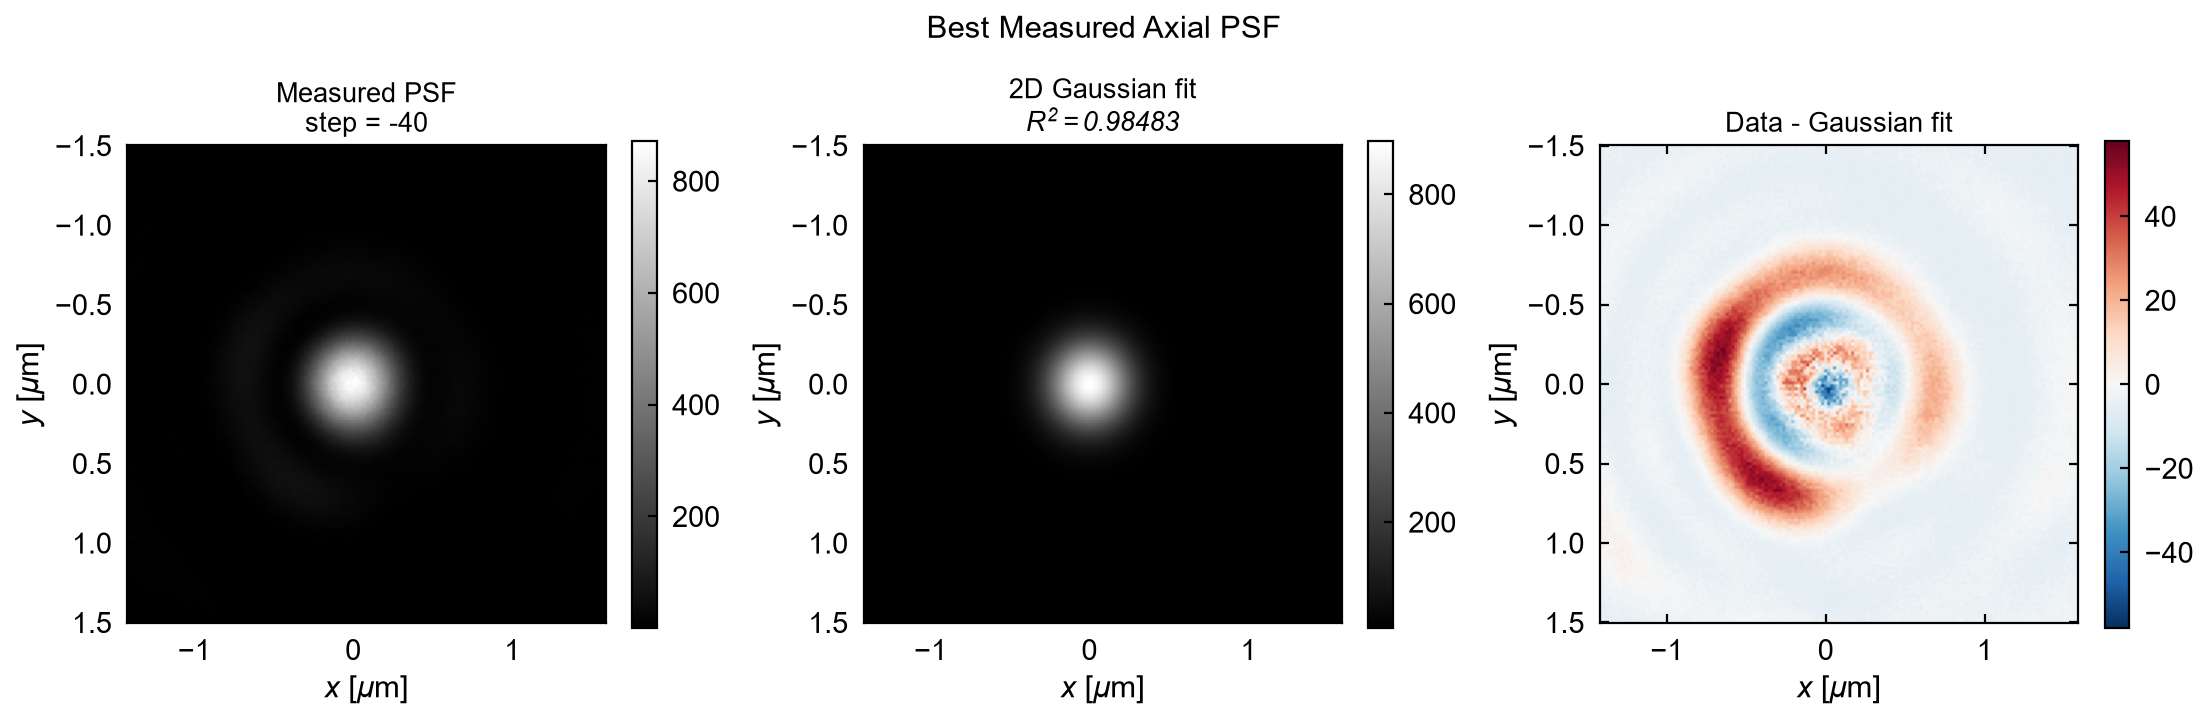

In [9]:
# ============================================================
# BEST MEASURED PSF ONLY
#
# Loads:
#       -40.tif
#
# Converts camera pixels -> object-plane um using:
#
#       pixel size = 3.45 um
#       magnification = 182.3
#
# ============================================================

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tifffile

from scipy.optimize import least_squares


# ============================================================
# SETTINGS
# ============================================================

FOLDER = Path(
    r"C:\Users\admin\Desktop\Projects\Zeiss test\PSFs\axial scan"
)

STEP = -40

FILE = FOLDER / f"{STEP}.tif"


MAGNIFICATION = 182.3

CAMERA_PIXEL_UM = 3.45

OBJECT_PIXEL_UM = (
    CAMERA_PIXEL_UM
    /
    MAGNIFICATION
)


X_GUESS = 550
Y_GUESS = 400

ROI_HALF = 80


FWHM_FACTOR = (
    2
    *
    np.sqrt(
        2 * np.log(2)
    )
)


print(
    f"Object-plane scale = "
    f"{OBJECT_PIXEL_UM*1000:.2f} nm/pixel"
)


# ============================================================
# GAUSSIAN MODEL
# ============================================================

def gaussian_2d(params, x, y):

    bg, amp, x0, y0, sx, sy, theta = params

    ct = np.cos(theta)
    st = np.sin(theta)

    xp = (
        (x-x0)*ct
        +
        (y-y0)*st
    )

    yp = (
        -(x-x0)*st
        +
        (y-y0)*ct
    )

    return (
        bg
        +
        amp
        *
        np.exp(
            -0.5
            *
            (
                (xp/sx)**2
                +
                (yp/sy)**2
            )
        )
    )


# ============================================================
# INITIAL GUESS
# ============================================================

def initial_guess(img):

    h, w = img.shape

    edge = np.concatenate([
        img[:5, :].ravel(),
        img[-5:, :].ravel(),
        img[:, :5].ravel(),
        img[:, -5:].ravel()
    ])

    bg = np.median(edge)

    signal = (
        img.astype(float)
        -
        bg
    )

    signal = np.clip(
        signal,
        0,
        None
    )

    yy, xx = np.indices(
        img.shape
    )

    threshold = (
        0.1 * signal.max()
    )

    weights = np.where(
        signal > threshold,
        signal,
        0
    )

    if weights.sum() == 0:

        weights = signal


    norm = weights.sum()

    x0 = (
        weights * xx
    ).sum() / norm

    y0 = (
        weights * yy
    ).sum() / norm


    dx = xx-x0
    dy = yy-y0


    var_x = (
        weights * dx**2
    ).sum() / norm

    var_y = (
        weights * dy**2
    ).sum() / norm

    cov_xy = (
        weights * dx*dy
    ).sum() / norm


    covariance = np.array([
        [var_x, cov_xy],
        [cov_xy, var_y]
    ])


    eigvals, eigvecs = np.linalg.eigh(
        covariance
    )


    eigvals = np.clip(
        eigvals,
        1,
        None
    )


    order = np.argsort(
        eigvals
    )[::-1]


    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]


    sx = np.sqrt(
        eigvals[0]
    )

    sy = np.sqrt(
        eigvals[1]
    )


    vx, vy = eigvecs[:, 0]

    theta = np.arctan2(
        vy,
        vx
    )


    amp = signal.max()


    return [
        bg,
        amp,
        x0,
        y0,
        sx,
        sy,
        theta
    ]


# ============================================================
# FIT
# ============================================================

def fit_gaussian(img):

    img = img.astype(float)

    h, w = img.shape

    yy, xx = np.indices(
        img.shape
    )

    p0 = initial_guess(
        img
    )


    p05, p95 = np.percentile(
        img,
        [5, 95]
    )

    scale = max(
        p95-p05,
        1
    )


    def residuals(params):

        model = gaussian_2d(
            params,
            xx,
            yy
        )

        return (
            (model-img)
            /
            scale
        ).ravel()


    lower = [
        -np.inf,
        0,
        0,
        0,
        0.5,
        0.5,
        -np.pi
    ]

    upper = [
        np.inf,
        np.inf,
        w-1,
        h-1,
        ROI_HALF,
        ROI_HALF,
        np.pi
    ]


    fit = least_squares(
        residuals,
        p0,
        bounds=(
            lower,
            upper
        ),
        loss="soft_l1",
        max_nfev=3000
    )


    params = fit.x

    model = gaussian_2d(
        params,
        xx,
        yy
    )


    ss_res = np.sum(
        (img-model)**2
    )

    ss_tot = np.sum(
        (img-np.mean(img))**2
    )

    r2 = (
        1
        -
        ss_res/ss_tot
    )


    return (
        params,
        model,
        r2
    )


# ============================================================
# LOAD IMAGE
# ============================================================

img = tifffile.imread(
    FILE
)

img = np.squeeze(
    img
)


# ============================================================
# CROP ROI
# ============================================================

x1 = X_GUESS - ROI_HALF
x2 = X_GUESS + ROI_HALF

y1 = Y_GUESS - ROI_HALF
y2 = Y_GUESS + ROI_HALF


roi = img[
    y1:y2,
    x1:x2
]


# ============================================================
# FIT
# ============================================================

params, model, r2 = fit_gaussian(
    roi
)


(
    bg,
    amp,
    x0,
    y0,
    sx,
    sy,
    theta
) = params


# ============================================================
# PHYSICAL WIDTHS
# ============================================================

sigma_major = max(
    sx,
    sy
)

sigma_minor = min(
    sx,
    sy
)


fwhm_major_px = (
    FWHM_FACTOR
    *
    sigma_major
)

fwhm_minor_px = (
    FWHM_FACTOR
    *
    sigma_minor
)


fwhm_major_um = (
    fwhm_major_px
    *
    OBJECT_PIXEL_UM
)

fwhm_minor_um = (
    fwhm_minor_px
    *
    OBJECT_PIXEL_UM
)


fwhm_geo_um = np.sqrt(
    fwhm_major_um
    *
    fwhm_minor_um
)


print()
print("=" * 60)

print(
    f"Major FWHM = "
    f"{fwhm_major_um:.4f} um"
)

print(
    f"Minor FWHM = "
    f"{fwhm_minor_um:.4f} um"
)

print(
    f"Geometric-mean FWHM = "
    f"{fwhm_geo_um:.4f} um"
)

print(
    f"R^2 = {r2:.6f}"
)

print("=" * 60)


# ============================================================
# OBJECT-PLANE AXES
#
# Center coordinates on fitted PSF centroid
# ============================================================

ny, nx = roi.shape


x_um = (
    np.arange(nx)
    -
    x0
) * OBJECT_PIXEL_UM


y_um = (
    np.arange(ny)
    -
    y0
) * OBJECT_PIXEL_UM


extent = [
    x_um[0],
    x_um[-1],
    y_um[-1],
    y_um[0]
]


# ============================================================
# RESIDUAL
# ============================================================

residual = (
    roi.astype(float)
    -
    model
)


res_lim = np.max(
    np.abs(residual)
)


# ============================================================
# PLOT
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 4.5)
)


# ------------------------------------------------------------
# MEASURED
# ------------------------------------------------------------

im0 = axes[0].imshow(
    roi,
    cmap="gray",
    extent=extent,
    aspect="equal"
)

axes[0].set_title(
    f"Measured PSF\nstep = {STEP}"
)

axes[0].set_xlabel(
    r"$x$ [$\mu$m]"
)

axes[0].set_ylabel(
    r"$y$ [$\mu$m]"
)

plt.colorbar(
    im0,
    ax=axes[0],
    fraction=0.046
)


# ------------------------------------------------------------
# FIT
# ------------------------------------------------------------

im1 = axes[1].imshow(
    model,
    cmap="gray",
    extent=extent,
    aspect="equal"
)

axes[1].set_title(
    "2D Gaussian fit\n"
    rf"$R^2 = {r2:.5f}$"
)

axes[1].set_xlabel(
    r"$x$ [$\mu$m]"
)

axes[1].set_ylabel(
    r"$y$ [$\mu$m]"
)

plt.colorbar(
    im1,
    ax=axes[1],
    fraction=0.046
)


# ------------------------------------------------------------
# RESIDUAL
# ------------------------------------------------------------

im2 = axes[2].imshow(
    residual,
    cmap="RdBu_r",
    extent=extent,
    aspect="equal",
    vmin=-res_lim,
    vmax=res_lim
)

axes[2].set_title(
    "Data - Gaussian fit"
)

axes[2].set_xlabel(
    r"$x$ [$\mu$m]"
)

axes[2].set_ylabel(
    r"$y$ [$\mu$m]"
)

plt.colorbar(
    im2,
    ax=axes[2],
    fraction=0.046
)


fig.suptitle(
    "Best Measured Axial PSF",
    fontsize=14
)

fig.tight_layout()

plt.show()


STREHL RATIO ANALYSIS — STEP -40
Object-plane sampling       : 18.925 nm/pixel
Ideal Airy FWHM             : 0.4335 um
Background                   : 3.000 counts
Normalization radius         : 1.300 um

Strehl from RAW peak         : 0.855
Strehl from Gaussian peak    : 0.878

Common Marechal criterion:
    Strehl >= 0.80  -> usually called diffraction limited


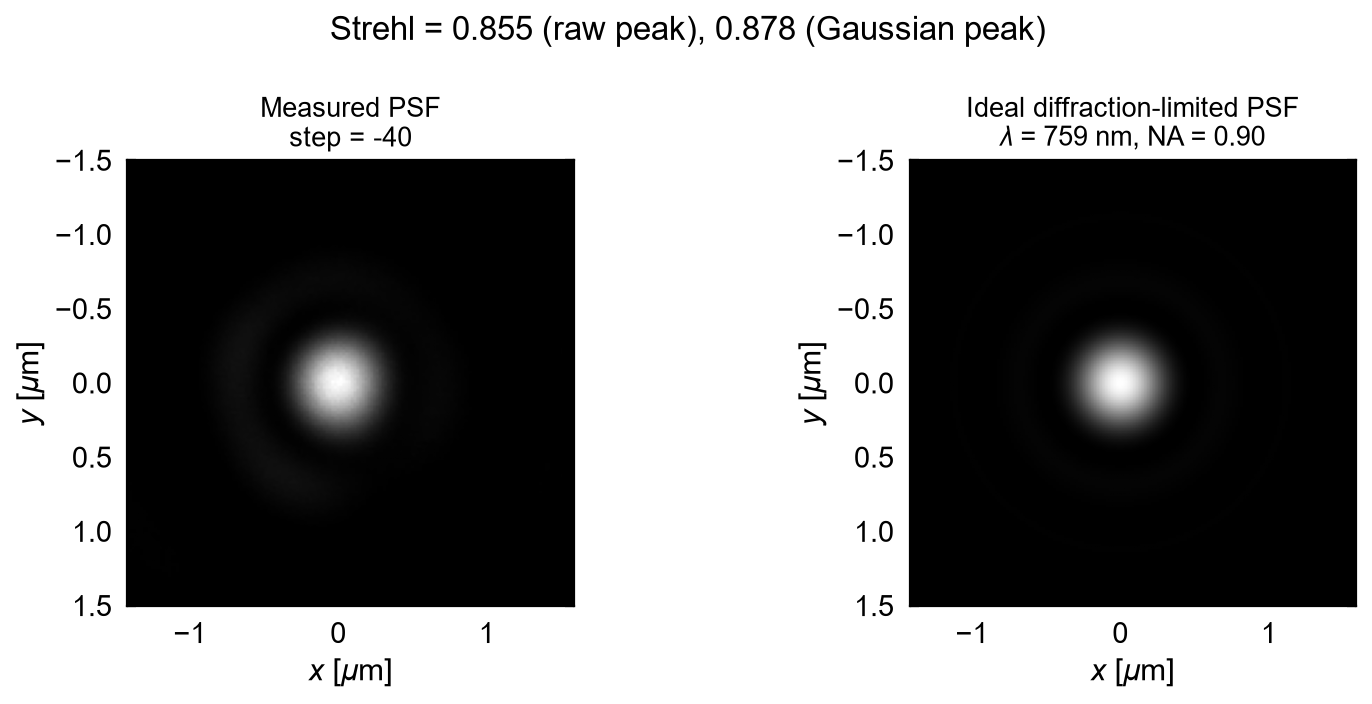

In [10]:
# ============================================================
# STREHL RATIO — COMPARE TO IDEAL AIRY PSF
# ============================================================

from scipy.special import j1


# ============================================================
# OPTICAL PARAMETERS
# ============================================================

WAVELENGTH_UM = 0.759       # 759 nm
NA = 0.90

MAGNIFICATION = 182.3
CAMERA_PIXEL_UM = 3.45

OBJECT_PIXEL_UM = (
    CAMERA_PIXEL_UM
    /
    MAGNIFICATION
)


# ============================================================
# BACKGROUND-SUBTRACT MEASURED PSF
# ============================================================

measured = roi.astype(float)


# Use border of ROI for background estimate
border_width = 10

border_pixels = np.concatenate([

    measured[:border_width, :].ravel(),

    measured[-border_width:, :].ravel(),

    measured[:, :border_width].ravel(),

    measured[:, -border_width:].ravel()

])


background = np.median(
    border_pixels
)


measured_bgsub = (
    measured
    -
    background
)


# Do not allow negative intensity after background subtraction
measured_bgsub = np.clip(
    measured_bgsub,
    0,
    None
)


# ============================================================
# OBJECT-PLANE COORDINATES
#
# Center ideal Airy pattern at fitted PSF centroid
# ============================================================

ny, nx = measured.shape

yy, xx = np.indices(
    measured.shape
)


x_object_um = (
    xx - x0
) * OBJECT_PIXEL_UM

y_object_um = (
    yy - y0
) * OBJECT_PIXEL_UM


r_um = np.sqrt(
    x_object_um**2
    +
    y_object_um**2
)


# ============================================================
# IDEAL DIFFRACTION-LIMITED AIRY PSF
#
# I(r) = [2 J1(u) / u]^2
#
# u = 2 pi NA r / lambda
# ============================================================

u = (
    2
    *
    np.pi
    *
    NA
    *
    r_um
    /
    WAVELENGTH_UM
)


ideal = np.ones_like(
    u
)


nonzero = (
    np.abs(u) > 1e-12
)


ideal[nonzero] = (

    2
    *
    j1(u[nonzero])
    /
    u[nonzero]

)**2


# ============================================================
# USE SAME PHYSICAL REGION FOR BOTH PSFs
#
# This avoids normalization differences due to finite ROI.
# ============================================================

# Maximum circle that comfortably fits inside ROI
R_NORM_UM = 1.30

mask = (
    r_um <= R_NORM_UM
)


# ============================================================
# TOTAL SIGNAL INSIDE SAME APERTURE
# ============================================================

measured_power = np.sum(
    measured_bgsub[mask]
)

ideal_power = np.sum(
    ideal[mask]
)


# ============================================================
# PEAKS
# ============================================================

# Raw measured maximum after background subtraction
measured_peak_raw = np.max(
    measured_bgsub
)


# Gaussian-fit peak above background
#
# params =
# [background, amplitude, x0, y0, sx, sy, theta]
#
gaussian_peak = params[1]


ideal_peak = np.max(
    ideal
)


# ============================================================
# NORMALIZED PEAKS
# ============================================================

measured_peak_normalized_raw = (
    measured_peak_raw
    /
    measured_power
)


measured_peak_normalized_fit = (
    gaussian_peak
    /
    measured_power
)


ideal_peak_normalized = (
    ideal_peak
    /
    ideal_power
)


# ============================================================
# STREHL RATIOS
# ============================================================

strehl_raw = (

    measured_peak_normalized_raw
    /
    ideal_peak_normalized

)


strehl_gaussian = (

    measured_peak_normalized_fit
    /
    ideal_peak_normalized

)


# ============================================================
# DIFFRACTION-LIMITED FWHM
# ============================================================

airy_fwhm_um = (
    0.514
    *
    WAVELENGTH_UM
    /
    NA
)


# ============================================================
# PRINT RESULTS
# ============================================================

print()
print("=" * 65)

print("STREHL RATIO ANALYSIS — STEP -40")

print("=" * 65)

print(
    f"Object-plane sampling       : "
    f"{OBJECT_PIXEL_UM*1000:.3f} nm/pixel"
)

print(
    f"Ideal Airy FWHM             : "
    f"{airy_fwhm_um:.4f} um"
)

print(
    f"Background                   : "
    f"{background:.3f} counts"
)

print(
    f"Normalization radius         : "
    f"{R_NORM_UM:.3f} um"
)

print()

print(
    f"Strehl from RAW peak         : "
    f"{strehl_raw:.3f}"
)

print(
    f"Strehl from Gaussian peak    : "
    f"{strehl_gaussian:.3f}"
)

print()

print(
    "Common Marechal criterion:"
)

print(
    "    Strehl >= 0.80  -> usually called diffraction limited"
)

print("=" * 65)


# ============================================================
# PLOT MEASURED AND IDEAL PSFs
# ============================================================

# Normalize each to same total signal inside normalization mask

measured_norm = (
    measured_bgsub
    /
    measured_power
)

ideal_norm = (
    ideal
    /
    ideal_power
)


x_axis_um = (
    np.arange(nx)
    -
    x0
) * OBJECT_PIXEL_UM

y_axis_um = (
    np.arange(ny)
    -
    y0
) * OBJECT_PIXEL_UM


extent = [

    x_axis_um[0],
    x_axis_um[-1],

    y_axis_um[-1],
    y_axis_um[0]

]


fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4.5)
)


# ------------------------------------------------------------
# MEASURED
# ------------------------------------------------------------

im0 = axes[0].imshow(

    measured_norm,

    cmap="gray",

    extent=extent,

    aspect="equal"
)


axes[0].set_title(

    f"Measured PSF\n"
    f"step = -40"

)

axes[0].set_xlabel(
    r"$x$ [$\mu$m]"
)

axes[0].set_ylabel(
    r"$y$ [$\mu$m]"
)


# ------------------------------------------------------------
# IDEAL
# ------------------------------------------------------------

im1 = axes[1].imshow(

    ideal_norm,

    cmap="gray",

    extent=extent,

    aspect="equal"
)


axes[1].set_title(

    "Ideal diffraction-limited PSF\n"
    rf"$\lambda$ = {WAVELENGTH_UM*1000:.0f} nm, "
    rf"NA = {NA:.2f}"

)

axes[1].set_xlabel(
    r"$x$ [$\mu$m]"
)

axes[1].set_ylabel(
    r"$y$ [$\mu$m]"
)


fig.suptitle(

    f"Strehl = {strehl_raw:.3f} "
    f"(raw peak), "
    f"{strehl_gaussian:.3f} "
    f"(Gaussian peak)"

)


fig.tight_layout()

plt.show()

Object-plane sampling : 18.925 nm/pixel
First Airy zero       : 0.5143 um
Second Airy zero      : 0.9416 um
Ideal Airy FWHM       : 0.4335 um

RESULTS AT STEP -40
Geometric FWHM : 0.4218 um
Strehl, ROI <= first zero  : 0.9512
Strehl, ROI <= second zero : 0.8717


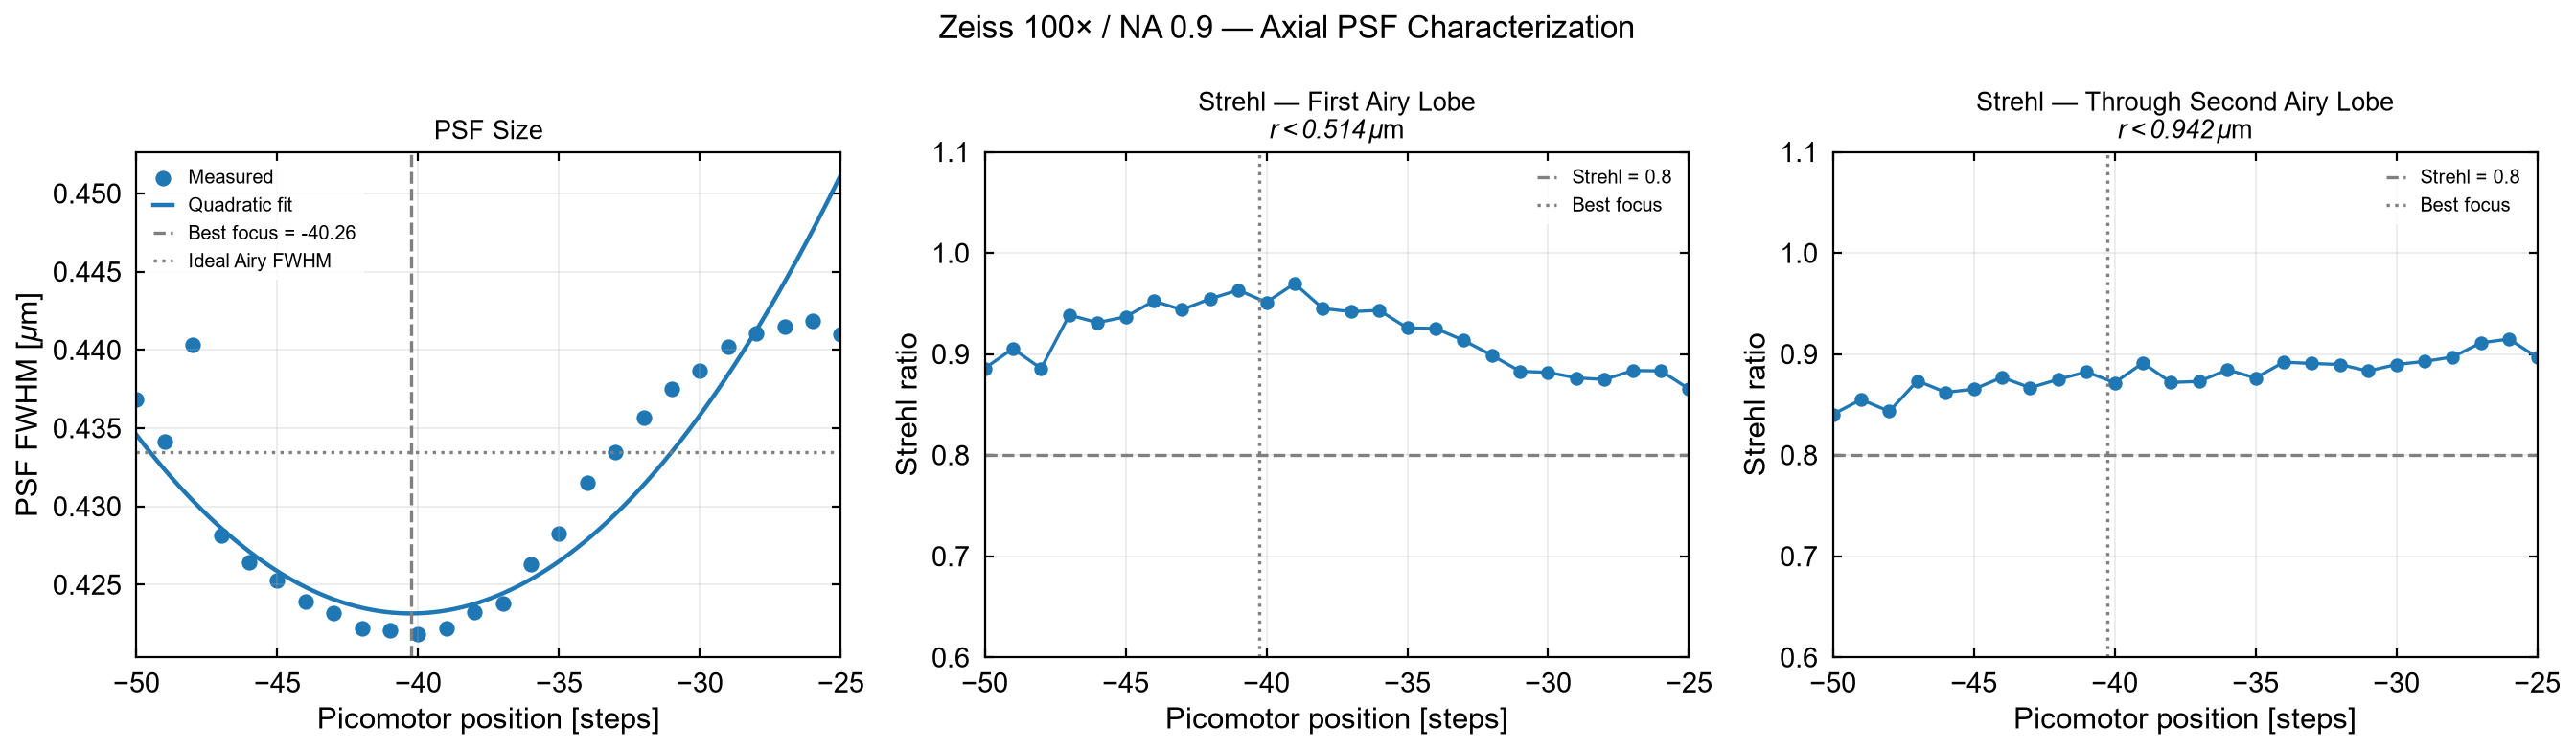

In [11]:
# ============================================================
# THREE-PANEL AXIAL PSF / STREHL ANALYSIS
#
# Panel 1:
#   Object-plane FWHM vs Picomotor position
#
# Panel 2:
#   Strehl ratio using ROI out to first Airy zero
#
# Panel 3:
#   Strehl ratio using ROI out to second Airy zero
#
# Camera:
#   Thorlabs CS165MU1/M
#   pixel size = 3.45 um
#
# Measured magnification:
#   M = 182.3
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile

from scipy.special import j1
from scipy.optimize import least_squares


# ============================================================
# SETTINGS
# ============================================================

FOLDER = Path(
    r"C:\Users\admin\Desktop\Projects\Zeiss test\PSFs\axial scan"
)

CSV_FILE = (
    FOLDER
    /
    "axial_scan_focus_-50_to_-25.csv"
)

STEP_MIN = -50
STEP_MAX = -25

MAGNIFICATION = 182.3

CAMERA_PIXEL_UM = 3.45

OBJECT_PIXEL_UM = (
    CAMERA_PIXEL_UM
    /
    MAGNIFICATION
)

WAVELENGTH_UM = 0.759

NA = 0.90


# ============================================================
# AIRY ZERO RADII
#
# Zeros of J1:
#
# first  = 3.831706
# second = 7.015587
#
# u = 2*pi*NA*r/lambda
# ============================================================

J1_ZERO_1 = 3.831706
J1_ZERO_2 = 7.015587


R_FIRST_UM = (
    J1_ZERO_1
    *
    WAVELENGTH_UM
    /
    (2 * np.pi * NA)
)

R_SECOND_UM = (
    J1_ZERO_2
    *
    WAVELENGTH_UM
    /
    (2 * np.pi * NA)
)


print("=" * 65)

print(
    f"Object-plane sampling : "
    f"{OBJECT_PIXEL_UM*1000:.3f} nm/pixel"
)

print(
    f"First Airy zero       : "
    f"{R_FIRST_UM:.4f} um"
)

print(
    f"Second Airy zero      : "
    f"{R_SECOND_UM:.4f} um"
)

print(
    f"Ideal Airy FWHM       : "
    f"{0.514*WAVELENGTH_UM/NA:.4f} um"
)

print("=" * 65)


# ============================================================
# LOAD PREVIOUS FIT RESULTS
# ============================================================

df = pd.read_csv(
    CSV_FILE
)


df = df[
    (df["step"] >= STEP_MIN)
    &
    (df["step"] <= STEP_MAX)
].copy()


df.sort_values(
    "step",
    inplace=True
)

df.reset_index(
    drop=True,
    inplace=True
)


# ============================================================
# CONVERT MEASURED FWHM TO OBJECT PLANE
# ============================================================

df["fwhm_geo_um"] = (
    df["fwhm_geo_px"]
    *
    OBJECT_PIXEL_UM
)

df["fwhm_major_um"] = (
    df["fwhm_major_px"]
    *
    OBJECT_PIXEL_UM
)

df["fwhm_minor_um"] = (
    df["fwhm_minor_px"]
    *
    OBJECT_PIXEL_UM
)


# ============================================================
# LOCAL QUADRATIC FOCUS FIT
# ============================================================

def quadratic_focus(params, z):

    w0, z0, a = params

    return (
        w0
        +
        a * (z-z0)**2
    )


z = df["step"].to_numpy(
    dtype=float
)

width = df["fwhm_geo_um"].to_numpy(
    dtype=float
)


i_min = np.argmin(
    width
)


p0 = [
    width[i_min],
    z[i_min],
    1e-4
]


def focus_residuals(params):

    return (
        quadratic_focus(params, z)
        -
        width
    )


fit = least_squares(

    focus_residuals,

    p0,

    bounds=(

        [
            0,
            STEP_MIN,
            0
        ],

        [
            np.inf,
            STEP_MAX,
            np.inf
        ]
    ),

    loss="soft_l1",

    f_scale=0.001
)


w0_fit, z0_fit, curvature = fit.x


z_dense = np.linspace(
    STEP_MIN,
    STEP_MAX,
    1000
)


width_dense = quadratic_focus(
    fit.x,
    z_dense
)


# ============================================================
# STREHL FUNCTION
# ============================================================

def calculate_strehl(
    image,
    x_center_px,
    y_center_px,
    background,
    radius_um
):

    """
    Calculate ROI-dependent Strehl ratio.

    Both measured and ideal PSFs are normalized to the
    integrated energy inside exactly the same circular ROI.

    Parameters
    ----------
    image : 2D numpy array
        Full camera image.

    x_center_px, y_center_px : float
        Fitted PSF centroid in full-camera pixels.

    background : float
        Background level from previous Gaussian fit.

    radius_um : float
        Circular normalization radius in object-plane microns.

    Returns
    -------
    strehl : float
    """

    image = image.astype(float)


    # --------------------------------------------------------
    # Coordinates relative to fitted centroid
    # --------------------------------------------------------

    yy, xx = np.indices(
        image.shape
    )


    dx_um = (
        xx
        -
        x_center_px
    ) * OBJECT_PIXEL_UM


    dy_um = (
        yy
        -
        y_center_px
    ) * OBJECT_PIXEL_UM


    r_um = np.sqrt(
        dx_um**2
        +
        dy_um**2
    )


    # --------------------------------------------------------
    # Circular ROI
    # --------------------------------------------------------

    mask = (
        r_um <= radius_um
    )


    # --------------------------------------------------------
    # Background-subtracted measured PSF
    # --------------------------------------------------------

    measured = (
        image
        -
        background
    )


    # --------------------------------------------------------
    # Ideal Airy PSF sampled on SAME camera grid
    # and centered at SAME subpixel position
    # --------------------------------------------------------

    u = (
        2
        *
        np.pi
        *
        NA
        *
        r_um
        /
        WAVELENGTH_UM
    )


    ideal = np.ones_like(
        u,
        dtype=float
    )


    nz = (
        np.abs(u) > 1e-12
    )


    ideal[nz] = (

        2
        *
        j1(u[nz])
        /
        u[nz]

    )**2


    # --------------------------------------------------------
    # Integrated energy inside selected ROI
    # --------------------------------------------------------

    measured_energy = np.sum(
        measured[mask]
    )

    ideal_energy = np.sum(
        ideal[mask]
    )


    # --------------------------------------------------------
    # Experimental peak
    #
    # Use local maximum near fitted centroid.
    #
    # Searching only a small central patch avoids selecting
    # some unrelated hot pixel elsewhere in the image.
    # --------------------------------------------------------

    xc = int(
        round(x_center_px)
    )

    yc = int(
        round(y_center_px)
    )


    PEAK_HALF_WIDTH = 3


    local_peak_region = measured[

        yc-PEAK_HALF_WIDTH:
        yc+PEAK_HALF_WIDTH+1,

        xc-PEAK_HALF_WIDTH:
        xc+PEAK_HALF_WIDTH+1

    ]


    measured_peak = np.max(
        local_peak_region
    )


    # Ideal sampled peak
    ideal_peak = np.max(
        ideal
    )


    # --------------------------------------------------------
    # Strehl
    #
    # S =
    #
    # (Ipeak_measured / E_measured)
    # --------------------------------
    # (Ipeak_ideal    / E_ideal)
    #
    # --------------------------------------------------------

    measured_norm_peak = (
        measured_peak
        /
        measured_energy
    )


    ideal_norm_peak = (
        ideal_peak
        /
        ideal_energy
    )


    strehl = (
        measured_norm_peak
        /
        ideal_norm_peak
    )


    return strehl


# ============================================================
# CALCULATE STREHL FOR EVERY AXIAL POSITION
# ============================================================

strehl_first = []

strehl_second = []


for _, row in df.iterrows():

    step = int(
        row["step"]
    )


    filename = (
        FOLDER
        /
        f"{step}.tif"
    )


    image = tifffile.imread(
        filename
    )


    image = np.squeeze(
        image
    )


    # Fitted centroid from previous analysis
    xc = row[
        "x_centroid_px"
    ]

    yc = row[
        "y_centroid_px"
    ]


    # Fitted background from previous analysis
    background = row[
        "background"
    ]


    # --------------------------------------------------------
    # First Airy lobe ROI
    # --------------------------------------------------------

    S1 = calculate_strehl(

        image,

        xc,

        yc,

        background,

        R_FIRST_UM

    )


    # --------------------------------------------------------
    # First + second Airy lobe ROI
    # --------------------------------------------------------

    S2 = calculate_strehl(

        image,

        xc,

        yc,

        background,

        R_SECOND_UM

    )


    strehl_first.append(
        S1
    )

    strehl_second.append(
        S2
    )


df["strehl_first_lobe"] = (
    strehl_first
)

df["strehl_second_lobe"] = (
    strehl_second
)


# ============================================================
# PRINT BEST-FOCUS VALUES
# ============================================================

best_idx = (
    np.abs(
        df["step"] + 40
    )
).idxmin()


print()
print("=" * 65)

print("RESULTS AT STEP -40")

print("=" * 65)


print(
    f"Geometric FWHM : "
    f"{df.loc[best_idx, 'fwhm_geo_um']:.4f} um"
)


print(
    f"Strehl, ROI <= first zero  : "
    f"{df.loc[best_idx, 'strehl_first_lobe']:.4f}"
)


print(
    f"Strehl, ROI <= second zero : "
    f"{df.loc[best_idx, 'strehl_second_lobe']:.4f}"
)


print("=" * 65)


# ============================================================
# THREE-PANEL FIGURE
# ============================================================

fig, axes = plt.subplots(

    1,
    3,

    figsize=(17, 5)

)


# ============================================================
# PANEL 1
#
# OBJECT-PLANE FWHM
# ============================================================

ax = axes[0]


ax.scatter(

    df["step"],

    df["fwhm_geo_um"],

    s=40,

    label="Measured"

)


ax.plot(

    z_dense,

    width_dense,

    linewidth=2,

    label="Quadratic fit"

)


ax.axvline(

    z0_fit,

    linestyle="--",
    color="gray",
    label=(
        f"Best focus = "
        f"{z0_fit:.2f}"
    )

)


ax.axhline(

    0.514
    *
    WAVELENGTH_UM
    /
    NA,

    linestyle=":",
    color="gray",
    label="Ideal Airy FWHM"

)


ax.set_xlim(
    STEP_MIN,
    STEP_MAX
)


ax.set_xlabel(
    "Picomotor position [steps]"
)


ax.set_ylabel(
    r"PSF FWHM [$\mu$m]"
)


ax.set_title(
    "PSF Size"
)


ax.grid(
    alpha=0.25
)


ax.legend(
    fontsize=9
)


# ============================================================
# PANEL 2
#
# STREHL — FIRST AIRY LOBE
# ============================================================

ax = axes[1]


ax.plot(

    df["step"],

    df["strehl_first_lobe"],

    "o-",

    markersize=5

)


ax.axhline(

    0.8,

    linestyle="--",
    color="gray",
    label="Strehl = 0.8"

)


ax.axvline(

    z0_fit,

    linestyle=":",
    color="gray",
    label="Best focus"

)


ax.set_xlim(
    STEP_MIN,
    STEP_MAX
)


ax.set_ylim(
    0.6,
    1.1
)


ax.set_xlabel(
    "Picomotor position [steps]"
)


ax.set_ylabel(
    "Strehl ratio"
)


ax.set_title(

    "Strehl — First Airy Lobe\n"
    rf"$r < {R_FIRST_UM:.3f}\,\mu$m"

)


ax.grid(
    alpha=0.25
)


ax.legend(
    fontsize=9
)


# ============================================================
# PANEL 3
#
# STREHL — FIRST + SECOND AIRY LOBES
# ============================================================

ax = axes[2]


ax.plot(

    df["step"],

    df["strehl_second_lobe"],

    "o-",

    markersize=5

)


ax.axhline(

    0.8,

    linestyle="--",
    color="gray",
    label="Strehl = 0.8"

)


ax.axvline(

    z0_fit,

    linestyle=":",
    color="gray",
    label="Best focus"

)


ax.set_xlim(
    STEP_MIN,
    STEP_MAX
)


ax.set_ylim(
    0.6,
    1.1
)


ax.set_xlabel(
    "Picomotor position [steps]"
)


ax.set_ylabel(
    "Strehl ratio"
)


ax.set_title(

    "Strehl — Through Second Airy Lobe\n"
    rf"$r < {R_SECOND_UM:.3f}\,\mu$m"

)


ax.grid(
    alpha=0.25
)


ax.legend(
    fontsize=9
)


# ============================================================
# FINAL FORMATTING
# ============================================================

fig.suptitle(

    "Zeiss 100× / NA 0.9 — Axial PSF Characterization",

    fontsize=15

)


fig.tight_layout()


plt.show()


# ============================================================
# OPTIONAL SAVE
# ============================================================

fig.savefig(

    FOLDER
    /
    "axial_PSF_FWHM_and_Strehl.png",

    dpi=250,

    bbox_inches="tight"

)


# ============================================================
# SAVE STREHL DATA AS WELL
# ============================================================

df.to_csv(

    FOLDER
    /
    "axial_scan_with_strehl.csv",

    index=False

)

## FOV-y scan

Object-plane sampling   : 0.018925 um/pixel
                        = 18.92 nm/pixel
Ideal Airy FWHM         : 0.4335 um
First Airy zero radius  : 0.5143 um
Second Airy zero radius : 0.9416 um

Found 37 TIFF images.
Commanded range: -700 to 700 steps
 -700   x= 1273.43   y=  329.39   FWHM= 0.4982 um   ellip= 1.141   S1=  0.716   S2=  0.716   R²=0.98423
 -600   x= 1200.79   y=  332.79   FWHM= 0.4916 um   ellip= 1.186   S1=  0.735   S2=  0.714   R²=0.99200
 -500   x= 1122.11   y=  334.90   FWHM= 0.4382 um   ellip= 1.166   S1=  0.906   S2=  0.900   R²=0.99092
  -28   x=  574.60   y=  372.15   FWHM= 0.4300 um   ellip= 1.052   S1=  0.943   S2=  0.876   R²=0.98546
  -26   x=  571.44   y=  373.22   FWHM= 0.4286 um   ellip= 1.047   S1=  0.948   S2=  0.883   R²=0.98563
  -24   x=  566.99   y=  374.58   FWHM= 0.4262 um   ellip= 1.042   S1=  0.957   S2=  0.894   R²=0.98604
  -22   x=  563.64   y=  375.69   FWHM= 0.4245 um   ellip= 1.039   S1=  0.964   S2=  0.903   R²=0.98660
  -20   x=  560.94   

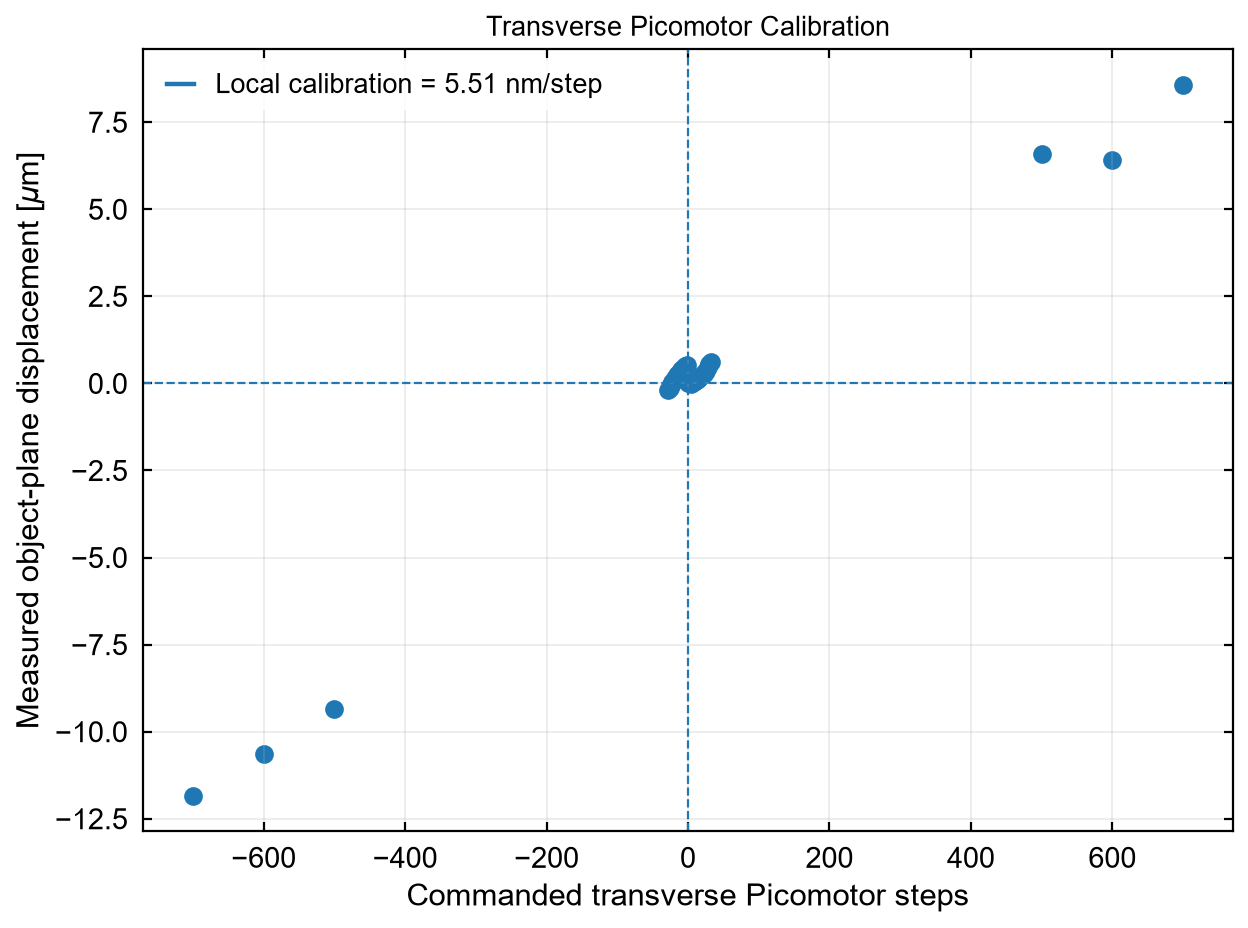

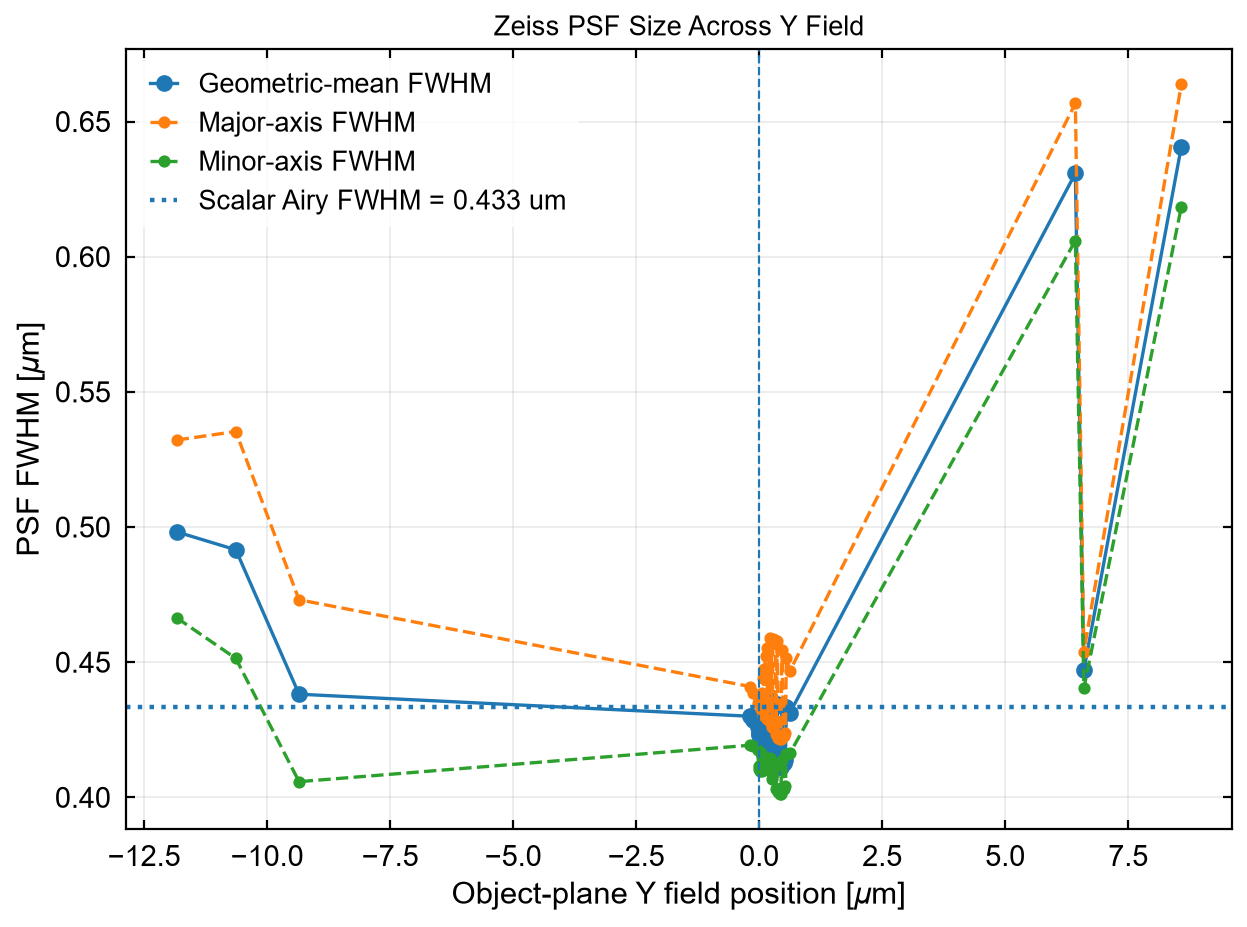

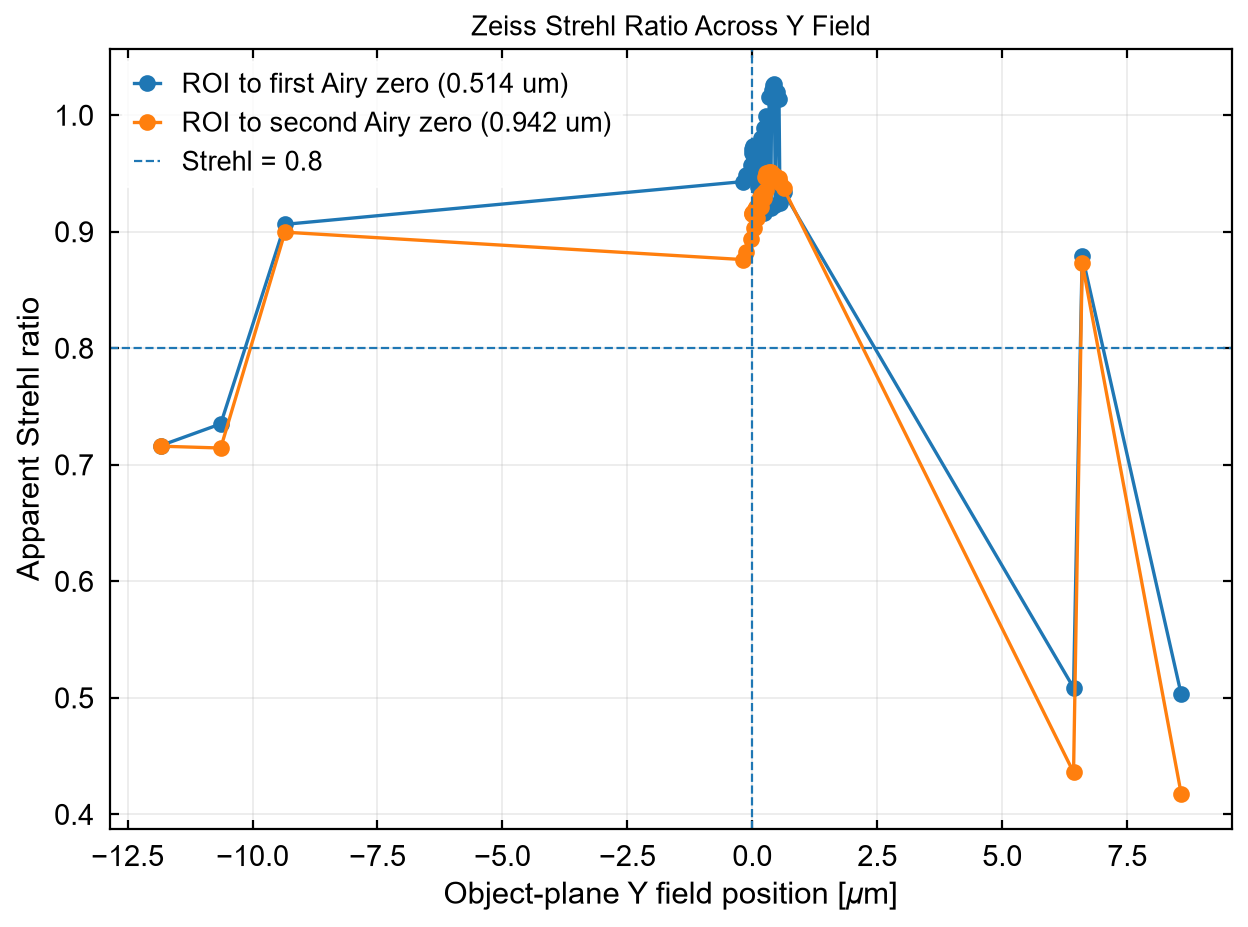

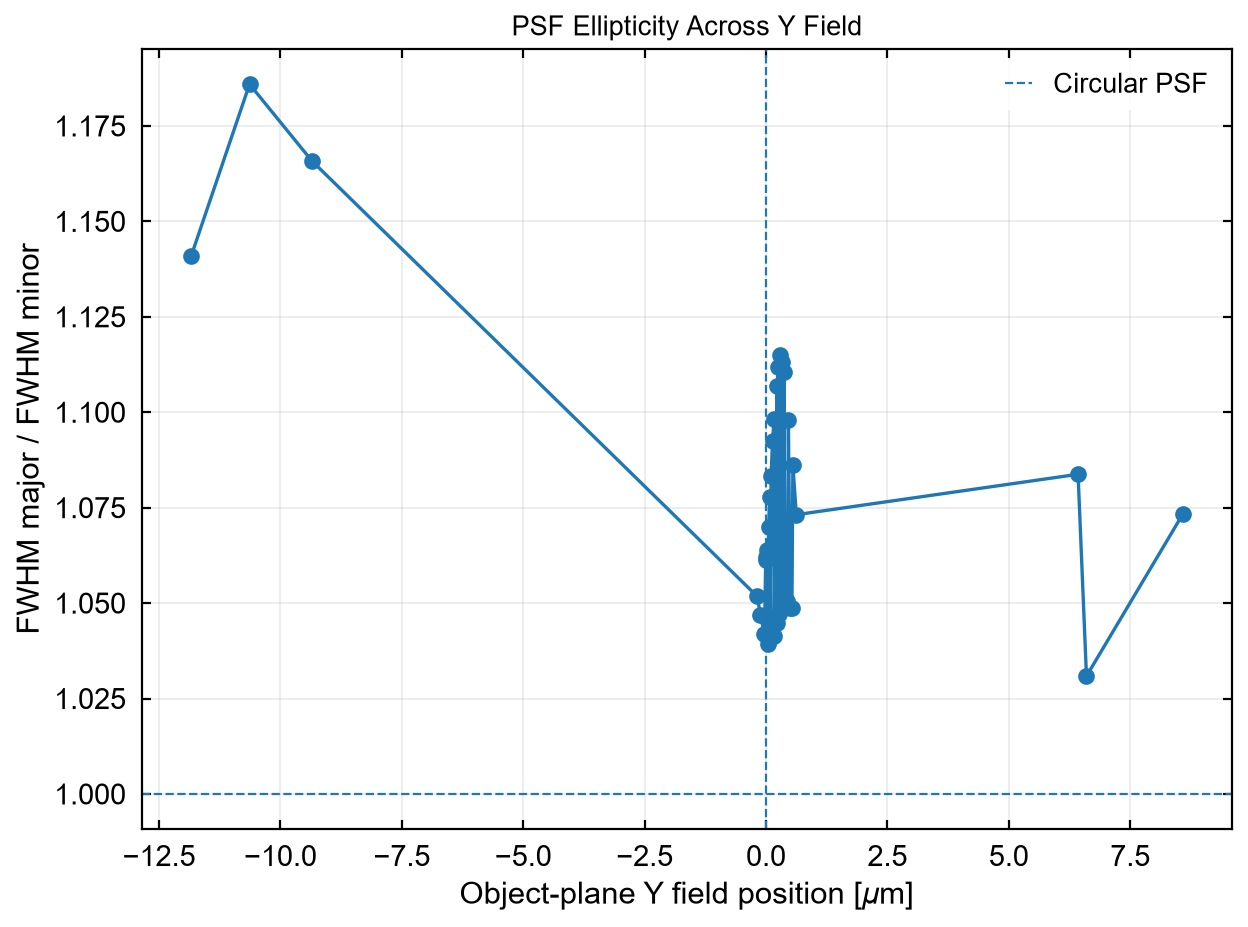

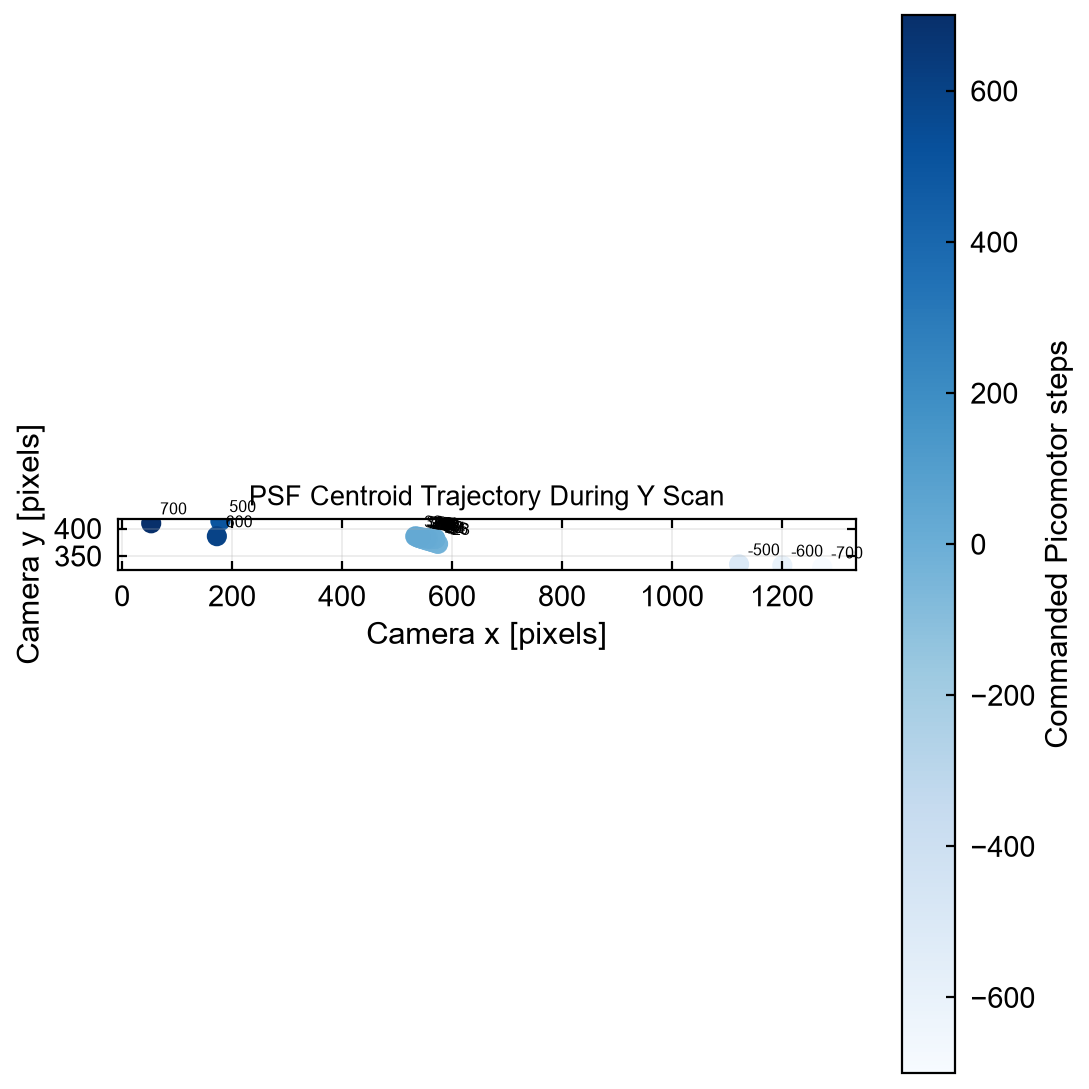

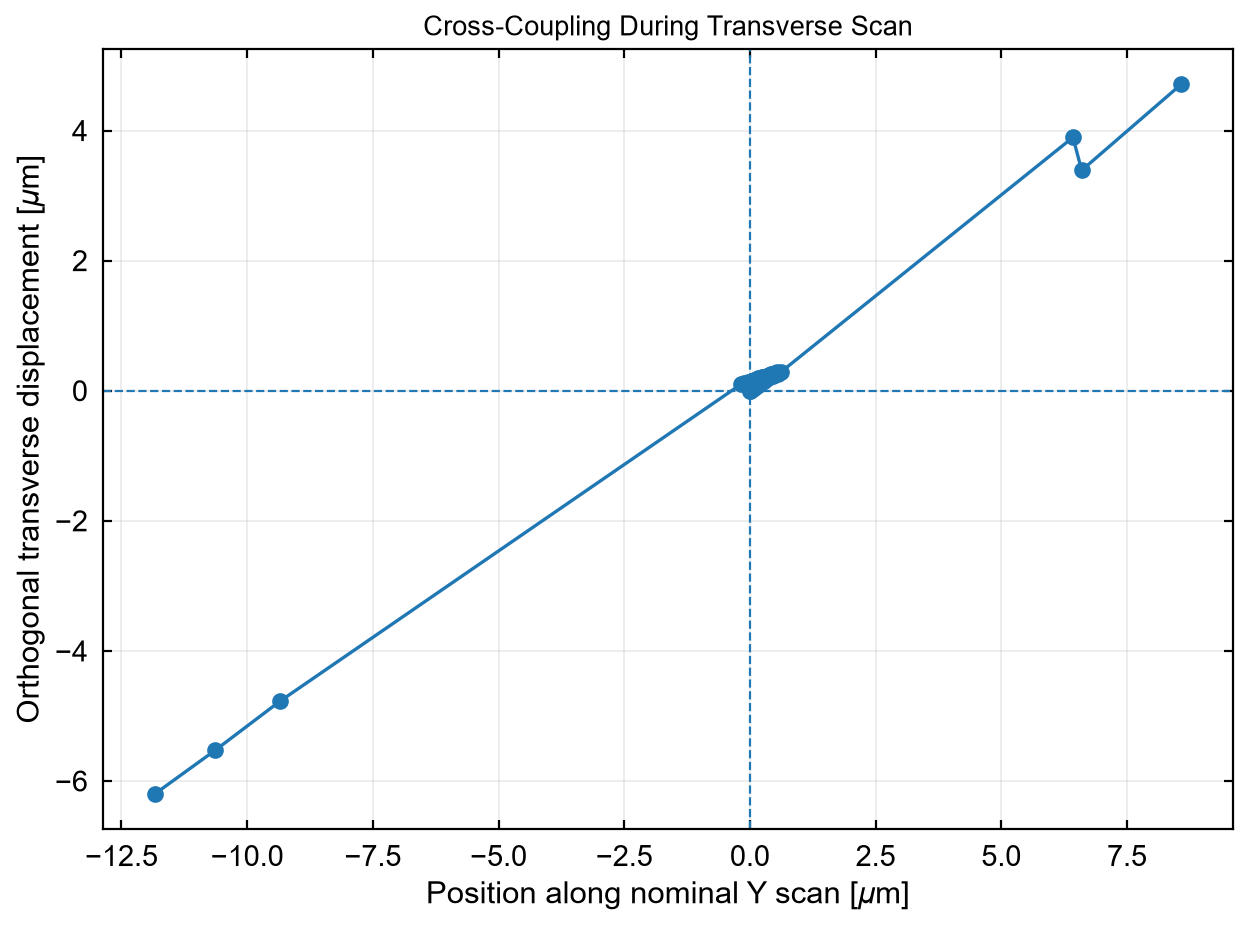

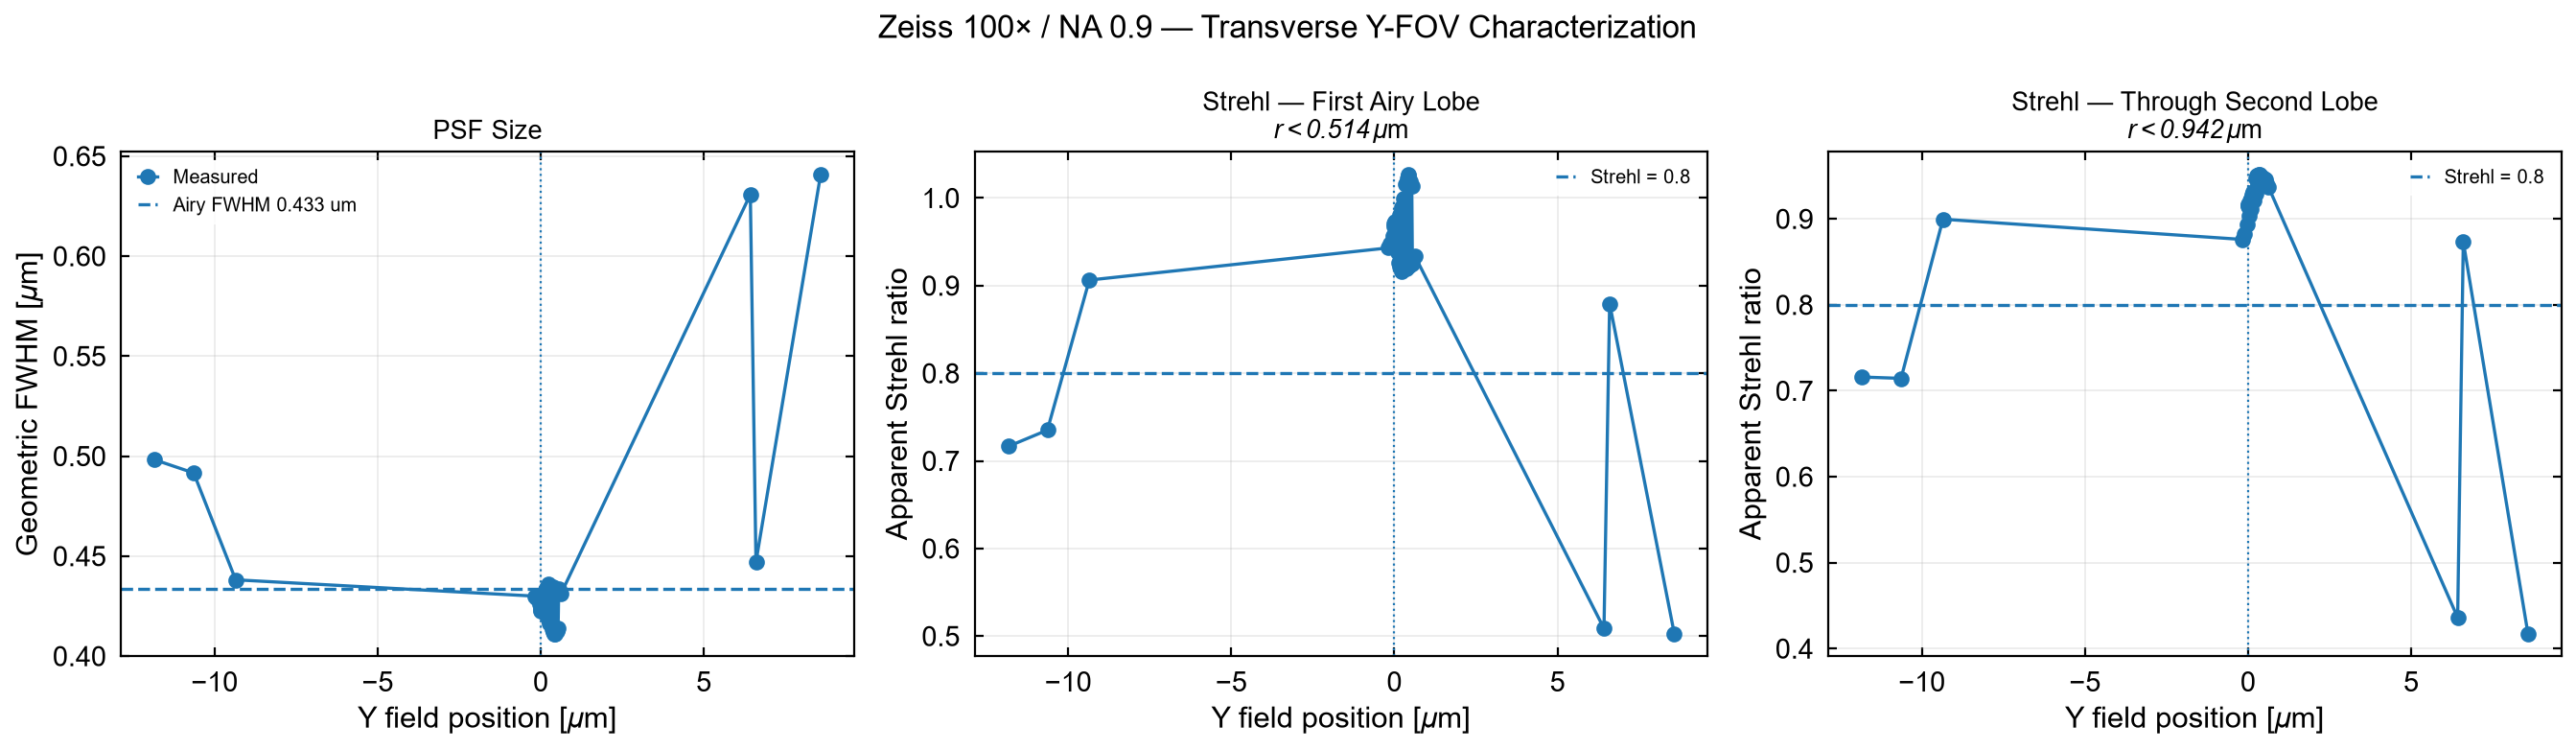


Y-FOV SCAN SUMMARY
Central FWHM_geo         : 0.4239 um
Central ellipticity      : 1.0613
Central Strehl — 1st ROI : 0.9672
Central Strehl — 2nd ROI : 0.9151

Measured minimum field   : -11.838 um
Measured maximum field   : +8.580 um
Total measured Y span    : 20.418 um

Local transverse calibration: 5.513 nm/step
Positive scan calibration   : 19.942 nm/step
Negative scan calibration   : 27.581 nm/step


In [12]:
# ============================================================
# ZEISS OBJECTIVE — TRANSVERSE Y-FOV SCAN
# ============================================================
#
# Dataset:
#   C:\Users\admin\Desktop\Projects\Zeiss test\PSFs\y_fov scan
#
# Axial position:
#   fixed at the previously determined best focus (~ -40 steps)
#
# Filename convention:
#   -700.tif ... -2.tif, 0.tif, 2.tif ... 700.tif
#
# The filename is the commanded transverse Picomotor position.
#
# Analysis:
#
#   1. Automatically find the PSF anywhere on the camera
#   2. Fit a rotated elliptical 2D Gaussian
#   3. Extract centroid, FWHM, ellipticity, R²
#   4. Determine actual transverse scan direction on camera
#   5. Convert camera displacement -> object-plane displacement
#   6. Calibrate nm / commanded step
#   7. Calculate apparent Strehl ratio
#        - first Airy lobe ROI
#        - through second Airy lobe ROI
#   8. Plot FWHM, Strehl, ellipticity and cross-coupling
#
#
# Camera:
#   Thorlabs CS165MU1/M
#   pixel size = 3.45 um
#
# Measured magnification:
#   M = 182.3
#
# Light:
#   lambda = 759 nm
#
# Objective:
#   Zeiss NA = 0.90
#
# ============================================================


from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile

from scipy.optimize import least_squares
from scipy.ndimage import gaussian_filter
from scipy.special import j1


# ============================================================
# USER SETTINGS
# ============================================================

FOLDER = Path(
    r"C:\Users\admin\Desktop\Projects\Zeiss test\PSFs\y_fov scan"
)

MAGNIFICATION = 182.3

CAMERA_PIXEL_UM = 3.45

OBJECT_PIXEL_UM = (
    CAMERA_PIXEL_UM
    /
    MAGNIFICATION
)


WAVELENGTH_UM = 0.759

NA = 0.90


# ------------------------------------------------------------
# Gaussian fitting ROI
#
# 70 camera pixels corresponds to:
#
# 70 * 3.45/182.3 ≈ 1.33 um object-plane radius
#
# enough to contain second Airy zero (~0.94 um)
# ------------------------------------------------------------

ROI_HALF = 70


# ------------------------------------------------------------
# Use only the near points for determining local
# Picomotor calibration / scan direction.
#
# We have ±2, ±4, ... ±32.
# ------------------------------------------------------------

CALIBRATION_MAX_STEP = 32


SAVE_RESULTS = True

PRINT_EACH_IMAGE = True


# ============================================================
# DIFFRACTION-LIMITED REFERENCE VALUES
# ============================================================

# First two zeros of J1
J1_ZERO_1 = 3.831705970
J1_ZERO_2 = 7.015586670


# radius of first Airy zero
R_AIRY_1_UM = (
    J1_ZERO_1
    *
    WAVELENGTH_UM
    /
    (
        2
        *
        np.pi
        *
        NA
    )
)


# radius of second Airy zero
R_AIRY_2_UM = (
    J1_ZERO_2
    *
    WAVELENGTH_UM
    /
    (
        2
        *
        np.pi
        *
        NA
    )
)


# Scalar Airy FWHM
AIRY_FWHM_UM = (
    0.514
    *
    WAVELENGTH_UM
    /
    NA
)


print("=" * 70)

print(
    f"Object-plane sampling   : "
    f"{OBJECT_PIXEL_UM:.6f} um/pixel"
)

print(
    f"                        = "
    f"{OBJECT_PIXEL_UM*1000:.2f} nm/pixel"
)

print(
    f"Ideal Airy FWHM         : "
    f"{AIRY_FWHM_UM:.4f} um"
)

print(
    f"First Airy zero radius  : "
    f"{R_AIRY_1_UM:.4f} um"
)

print(
    f"Second Airy zero radius : "
    f"{R_AIRY_2_UM:.4f} um"
)

print("=" * 70)


# ============================================================
# ROTATED ELLIPTICAL 2D GAUSSIAN
# ============================================================

def gaussian_2d(params, x, y):

    """
    Rotated elliptical Gaussian + constant background.

    params:
        background
        amplitude
        x0
        y0
        sigma_x
        sigma_y
        theta
    """

    bg, amp, x0, y0, sx, sy, theta = params

    ct = np.cos(theta)
    st = np.sin(theta)

    xp = (
        (x - x0) * ct
        +
        (y - y0) * st
    )

    yp = (
        -(x - x0) * st
        +
        (y - y0) * ct
    )

    return (
        bg
        +
        amp
        *
        np.exp(
            -0.5
            *
            (
                (xp / sx)**2
                +
                (yp / sy)**2
            )
        )
    )


# ============================================================
# AUTOMATIC PSF LOCALIZATION
# ============================================================

def find_psf_center(image):

    """
    Locate the approximate PSF center over the full image.

    Gaussian smoothing prevents a hot pixel from being selected
    instead of the PSF.
    """

    img = image.astype(float)

    background = np.median(img)

    img_sub = (
        img
        -
        background
    )

    smooth = gaussian_filter(
        img_sub,
        sigma=5
    )

    iy, ix = np.unravel_index(
        np.argmax(smooth),
        smooth.shape
    )

    return (
        float(ix),
        float(iy)
    )


# ============================================================
# INITIAL GAUSSIAN PARAMETERS
# ============================================================

def initial_guess(img):

    h, w = img.shape

    # --------------------------------------------------------
    # Background from ROI edges
    # --------------------------------------------------------

    edge = np.concatenate([
        img[:5, :].ravel(),
        img[-5:, :].ravel(),
        img[:, :5].ravel(),
        img[:, -5:].ravel()
    ])

    bg = np.median(edge)

    signal = (
        img.astype(float)
        -
        bg
    )

    signal = np.clip(
        signal,
        0,
        None
    )

    yy, xx = np.indices(
        img.shape
    )


    if signal.max() <= 0:

        return [
            bg,
            1,
            w / 2,
            h / 2,
            10,
            10,
            0
        ]


    # --------------------------------------------------------
    # Moment estimate
    # --------------------------------------------------------

    threshold = (
        0.1
        *
        signal.max()
    )

    weights = np.where(
        signal > threshold,
        signal,
        0
    )

    if weights.sum() <= 0:

        weights = signal


    norm = weights.sum()


    if norm <= 0:

        return [
            bg,
            max(signal.max(), 1),
            w / 2,
            h / 2,
            10,
            10,
            0
        ]


    x0 = (
        weights * xx
    ).sum() / norm

    y0 = (
        weights * yy
    ).sum() / norm


    dx = xx - x0
    dy = yy - y0


    var_x = (
        weights * dx**2
    ).sum() / norm

    var_y = (
        weights * dy**2
    ).sum() / norm

    cov_xy = (
        weights * dx * dy
    ).sum() / norm


    covariance = np.array([
        [var_x, cov_xy],
        [cov_xy, var_y]
    ])


    eigvals, eigvecs = np.linalg.eigh(
        covariance
    )


    eigvals = np.clip(
        eigvals,
        1.0,
        None
    )


    order = np.argsort(
        eigvals
    )[::-1]


    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]


    sx = np.sqrt(
        eigvals[0]
    )

    sy = np.sqrt(
        eigvals[1]
    )


    sx = np.clip(
        sx,
        2,
        30
    )

    sy = np.clip(
        sy,
        2,
        30
    )


    vx, vy = eigvecs[:, 0]


    theta = np.arctan2(
        vy,
        vx
    )


    amplitude = signal.max()


    return [
        bg,
        amplitude,
        x0,
        y0,
        sx,
        sy,
        theta
    ]


# ============================================================
# ROBUST GAUSSIAN FIT
# ============================================================

def fit_gaussian(img):

    img = img.astype(float)

    h, w = img.shape


    yy, xx = np.indices(
        img.shape
    )


    p0 = initial_guess(
        img
    )


    p05, p95 = np.percentile(
        img,
        [5, 95]
    )


    scale = max(
        p95 - p05,
        1
    )


    def residuals(params):

        model = gaussian_2d(
            params,
            xx,
            yy
        )

        return (
            (model - img)
            /
            scale
        ).ravel()


    lower = [
        -np.inf,
        0,
        0,
        0,
        0.5,
        0.5,
        -np.pi
    ]


    upper = [
        np.inf,
        np.inf,
        w - 1,
        h - 1,
        ROI_HALF,
        ROI_HALF,
        np.pi
    ]


    fit = least_squares(
        residuals,
        p0,
        bounds=(
            lower,
            upper
        ),
        loss="soft_l1",
        f_scale=1.0,
        max_nfev=3000
    )


    params = fit.x


    model = gaussian_2d(
        params,
        xx,
        yy
    )


    # --------------------------------------------------------
    # R²
    # --------------------------------------------------------

    ss_res = np.sum(
        (img - model)**2
    )

    ss_tot = np.sum(
        (img - np.mean(img))**2
    )


    if ss_tot > 0:

        r2 = (
            1
            -
            ss_res / ss_tot
        )

    else:

        r2 = np.nan


    return (
        params,
        model,
        r2
    )


# ============================================================
# APPARENT STREHL RATIO
# ============================================================

def calculate_strehl(
    roi,
    x0,
    y0,
    background,
    radius_um,
    gaussian_peak
):

    """
    ROI-dependent apparent Strehl ratio.

    Experimental peak:
        Gaussian fit amplitude

    Experimental energy:
        background-subtracted signal integrated inside
        circular physical ROI

    Ideal reference:
        scalar Airy PSF sampled on the exact same pixel grid

    Both PSFs are normalized using the same physical ROI.
    """

    roi = roi.astype(float)


    yy, xx = np.indices(
        roi.shape
    )


    # --------------------------------------------------------
    # Object-plane coordinates relative to fitted center
    # --------------------------------------------------------

    dx_um = (
        xx - x0
    ) * OBJECT_PIXEL_UM

    dy_um = (
        yy - y0
    ) * OBJECT_PIXEL_UM


    r_um = np.sqrt(
        dx_um**2
        +
        dy_um**2
    )


    mask = (
        r_um <= radius_um
    )


    if np.sum(mask) < 5:

        return np.nan


    # --------------------------------------------------------
    # Ensure ROI actually contains requested circular aperture
    # --------------------------------------------------------

    max_available_radius = min(

        x0,
        roi.shape[1] - 1 - x0,
        y0,
        roi.shape[0] - 1 - y0

    ) * OBJECT_PIXEL_UM


    if max_available_radius < radius_um:

        # PSF is too close to detector / crop boundary
        return np.nan


    # --------------------------------------------------------
    # Experimental image
    # --------------------------------------------------------

    measured = (
        roi
        -
        background
    )


    measured_energy = np.sum(
        measured[mask]
    )


    if measured_energy <= 0:

        return np.nan


    # --------------------------------------------------------
    # Ideal scalar Airy PSF
    #
    # I(r) = [2 J1(u) / u]^2
    #
    # u = 2 pi NA r / lambda
    # --------------------------------------------------------

    u = (
        2
        *
        np.pi
        *
        NA
        *
        r_um
        /
        WAVELENGTH_UM
    )


    ideal = np.ones_like(
        r_um,
        dtype=float
    )


    nz = (
        np.abs(u) > 1e-12
    )


    ideal[nz] = (
        2
        *
        j1(u[nz])
        /
        u[nz]
    )**2


    ideal_energy = np.sum(
        ideal[mask]
    )


    ideal_peak = np.max(
        ideal
    )


    # --------------------------------------------------------
    # Normalized peaks
    # --------------------------------------------------------

    measured_normalized_peak = (
        gaussian_peak
        /
        measured_energy
    )


    ideal_normalized_peak = (
        ideal_peak
        /
        ideal_energy
    )


    strehl = (
        measured_normalized_peak
        /
        ideal_normalized_peak
    )


    return strehl


# ============================================================
# FIND TIFF FILES
# ============================================================

files = []


for f in FOLDER.glob("*.tif"):

    try:

        command_step = int(
            f.stem
        )


        files.append(
            (
                command_step,
                f
            )
        )


    except ValueError:

        print(
            f"Skipping non-numeric file: {f.name}"
        )


files.sort(
    key=lambda x: x[0]
)


if len(files) == 0:

    raise RuntimeError(
        f"No TIFF files found in:\n{FOLDER}"
    )


print()
print("=" * 70)

print(
    f"Found {len(files)} TIFF images."
)

print(
    f"Commanded range: "
    f"{files[0][0]} to {files[-1][0]} steps"
)

print("=" * 70)


# ============================================================
# ANALYZE ALL IMAGES
# ============================================================

FWHM_FACTOR = (
    2
    *
    np.sqrt(
        2 * np.log(2)
    )
)


results = []


for command_step, filename in files:


    image = tifffile.imread(
        filename
    )


    image = np.squeeze(
        image
    )


    if image.ndim != 2:

        print(
            f"Skipping {filename.name}: "
            f"unexpected shape {image.shape}"
        )

        continue


    # --------------------------------------------------------
    # Locate PSF in full image
    # --------------------------------------------------------

    x_guess, y_guess = find_psf_center(
        image
    )


    xc_int = int(
        round(x_guess)
    )

    yc_int = int(
        round(y_guess)
    )


    # --------------------------------------------------------
    # Crop adaptive ROI
    # --------------------------------------------------------

    x1 = max(
        0,
        xc_int - ROI_HALF
    )

    x2 = min(
        image.shape[1],
        xc_int + ROI_HALF + 1
    )

    y1 = max(
        0,
        yc_int - ROI_HALF
    )

    y2 = min(
        image.shape[0],
        yc_int + ROI_HALF + 1
    )


    roi = image[
        y1:y2,
        x1:x2
    ]


    # --------------------------------------------------------
    # Require a reasonable ROI
    # --------------------------------------------------------

    if (
        roi.shape[0] < 30
        or
        roi.shape[1] < 30
    ):

        print(
            f"WARNING: {filename.name}: "
            f"PSF too close to sensor edge. "
            f"ROI shape = {roi.shape}"
        )

        continue


    # --------------------------------------------------------
    # Fit Gaussian
    # --------------------------------------------------------

    try:

        params, model, r2 = fit_gaussian(
            roi
        )

    except Exception as exc:

        print(
            f"Fit failed for {filename.name}: {exc}"
        )

        continue


    (
        background,
        amplitude,
        x0,
        y0,
        sx,
        sy,
        theta
    ) = params


    # --------------------------------------------------------
    # Full-camera fitted centroid
    # --------------------------------------------------------

    x_global = (
        x1
        +
        x0
    )

    y_global = (
        y1
        +
        y0
    )


    # --------------------------------------------------------
    # Widths
    # --------------------------------------------------------

    sigma_major = max(
        sx,
        sy
    )

    sigma_minor = min(
        sx,
        sy
    )


    fwhm_major_px = (
        FWHM_FACTOR
        *
        sigma_major
    )

    fwhm_minor_px = (
        FWHM_FACTOR
        *
        sigma_minor
    )


    fwhm_geo_px = np.sqrt(
        fwhm_major_px
        *
        fwhm_minor_px
    )


    # Object plane
    fwhm_major_um = (
        fwhm_major_px
        *
        OBJECT_PIXEL_UM
    )

    fwhm_minor_um = (
        fwhm_minor_px
        *
        OBJECT_PIXEL_UM
    )

    fwhm_geo_um = (
        fwhm_geo_px
        *
        OBJECT_PIXEL_UM
    )


    ellipticity = (
        fwhm_major_px
        /
        fwhm_minor_px
    )


    # --------------------------------------------------------
    # Strehl ratios
    # --------------------------------------------------------

    strehl_first = calculate_strehl(

        roi=roi,

        x0=x0,

        y0=y0,

        background=background,

        radius_um=R_AIRY_1_UM,

        gaussian_peak=amplitude

    )


    strehl_second = calculate_strehl(

        roi=roi,

        x0=x0,

        y0=y0,

        background=background,

        radius_um=R_AIRY_2_UM,

        gaussian_peak=amplitude

    )


    # --------------------------------------------------------
    # Save row
    # --------------------------------------------------------

    results.append({

        "command_step":
            command_step,

        "x_centroid_px":
            x_global,

        "y_centroid_px":
            y_global,

        "fwhm_major_px":
            fwhm_major_px,

        "fwhm_minor_px":
            fwhm_minor_px,

        "fwhm_geo_px":
            fwhm_geo_px,

        "fwhm_major_um":
            fwhm_major_um,

        "fwhm_minor_um":
            fwhm_minor_um,

        "fwhm_geo_um":
            fwhm_geo_um,

        "ellipticity":
            ellipticity,

        "strehl_first_lobe":
            strehl_first,

        "strehl_second_lobe":
            strehl_second,

        "background":
            background,

        "amplitude":
            amplitude,

        "theta_rad":
            theta,

        "R2":
            r2,

        "filename":
            filename.name

    })


    if PRINT_EACH_IMAGE:

        print(

            f"{command_step:+5d}   "

            f"x={x_global:8.2f}   "

            f"y={y_global:8.2f}   "

            f"FWHM={fwhm_geo_um:7.4f} um   "

            f"ellip={ellipticity:6.3f}   "

            f"S1={strehl_first:7.3f}   "

            f"S2={strehl_second:7.3f}   "

            f"R²={r2:7.5f}"

        )


# ============================================================
# BUILD DATAFRAME
# ============================================================

df = pd.DataFrame(
    results
)


if len(df) == 0:

    raise RuntimeError(
        "No images were successfully analyzed."
    )


df.sort_values(
    "command_step",
    inplace=True
)


df.reset_index(
    drop=True,
    inplace=True
)


# ============================================================
# REFERENCE = 0.tif
# ============================================================

row0 = df.loc[
    df["command_step"] == 0
]


if len(row0) != 1:

    raise RuntimeError(
        "Could not uniquely identify 0.tif."
    )


x_ref = float(
    row0.iloc[0][
        "x_centroid_px"
    ]
)


y_ref = float(
    row0.iloc[0][
        "y_centroid_px"
    ]
)


df["dx_camera_px"] = (
    df["x_centroid_px"]
    -
    x_ref
)


df["dy_camera_px"] = (
    df["y_centroid_px"]
    -
    y_ref
)


# ============================================================
# DETERMINE TRANSVERSE SCAN DIRECTION
#
# IMPORTANT:
#
# Do NOT assume physical y corresponds to camera y.
#
# Use near-field data to determine the actual displacement
# direction in camera coordinates.
# ============================================================

cal_initial = df[
    np.abs(
        df["command_step"]
    )
    <=
    CALIBRATION_MAX_STEP
].copy()


if len(cal_initial) < 3:

    raise RuntimeError(
        "Not enough near-field calibration points."
    )


# Fit camera x vs command
fit_x = np.polyfit(

    cal_initial["command_step"],

    cal_initial["x_centroid_px"],

    1

)


# Fit camera y vs command
fit_y = np.polyfit(

    cal_initial["command_step"],

    cal_initial["y_centroid_px"],

    1

)


scan_vector_px_per_step = np.array([

    fit_x[0],

    fit_y[0]

])


scan_slope_px_per_step = np.linalg.norm(
    scan_vector_px_per_step
)


if scan_slope_px_per_step <= 0:

    raise RuntimeError(
        "Could not determine scan direction."
    )


scan_unit = (
    scan_vector_px_per_step
    /
    scan_slope_px_per_step
)


# Orthogonal transverse direction
perp_unit = np.array([

    -scan_unit[1],

    scan_unit[0]

])


print()
print("=" * 70)
print("TRANSVERSE SCAN DIRECTION")
print("=" * 70)

print(
    f"Camera scan unit vector = "
    f"({scan_unit[0]:+.5f}, "
    f"{scan_unit[1]:+.5f})"
)

print(
    f"Initial fitted motion    = "
    f"{scan_slope_px_per_step:.5f} "
    f"camera px / command step"
)

print(
    f"Initial object motion    = "
    f"{scan_slope_px_per_step * OBJECT_PIXEL_UM * 1000:.3f} "
    f"nm / command step"
)

print("=" * 70)


# ============================================================
# PROJECT EVERY CENTROID DISPLACEMENT ONTO SCAN AXIS
# ============================================================

displacement_vectors = np.column_stack([

    df["dx_camera_px"].to_numpy(),

    df["dy_camera_px"].to_numpy()

])


signed_displacement_px = (
    displacement_vectors
    @
    scan_unit
)


perpendicular_displacement_px = (
    displacement_vectors
    @
    perp_unit
)


# ------------------------------------------------------------
# NOW CREATE field_position_um
# ------------------------------------------------------------

df["field_position_um"] = (

    signed_displacement_px
    *
    OBJECT_PIXEL_UM

)


df["perpendicular_position_um"] = (

    perpendicular_displacement_px
    *
    OBJECT_PIXEL_UM

)


# ============================================================
# IMPORTANT FIX:
#
# REBUILD calibration dataframe AFTER field_position_um exists.
# ============================================================

cal = df[
    np.abs(
        df["command_step"]
    )
    <=
    CALIBRATION_MAX_STEP
].copy()


positive = cal[
    cal["command_step"] > 0
].copy()


negative = cal[
    cal["command_step"] < 0
].copy()


# ============================================================
# POSITIVE-DIRECTION CALIBRATION
# ============================================================

pos_fit = None


if len(positive) >= 2:

    pos_fit = np.polyfit(

        positive["command_step"],

        positive["field_position_um"],

        1

    )


# ============================================================
# NEGATIVE-DIRECTION CALIBRATION
# ============================================================

neg_fit = None


if len(negative) >= 2:

    neg_fit = np.polyfit(

        negative["command_step"],

        negative["field_position_um"],

        1

    )


# ============================================================
# COMBINED LOCAL CALIBRATION
# ============================================================

combined_fit = np.polyfit(

    cal["command_step"],

    cal["field_position_um"],

    1

)


print()
print("=" * 70)

print("TRANSVERSE PICOMOTOR CALIBRATION")

print("=" * 70)


print(
    f"Combined local slope : "
    f"{combined_fit[0]*1000:.3f} nm/step"
)


if pos_fit is not None:

    print(
        f"Positive direction   : "
        f"{pos_fit[0]*1000:.3f} nm/step"
    )


if neg_fit is not None:

    print(
        f"Negative direction   : "
        f"{neg_fit[0]*1000:.3f} nm/step"
    )


if (
    pos_fit is not None
    and
    neg_fit is not None
):

    difference = (

        abs(
            abs(pos_fit[0])
            -
            abs(neg_fit[0])
        )
        *
        1000

    )

    print(
        f"|positive|-|negative|: "
        f"{difference:.3f} nm/step"
    )


print("=" * 70)


# ============================================================
# PRINT MEASURED FAR-FIELD POSITIONS
# ============================================================

print()
print("=" * 70)

print("MEASURED FAR-FIELD POSITIONS")

print("=" * 70)


far_commands = [
    -700,
    -600,
    -500,
    500,
    600,
    700
]


for command in far_commands:

    row = df.loc[
        df["command_step"] == command
    ]


    if len(row) == 1:

        position = float(
            row.iloc[0][
                "field_position_um"
            ]
        )

        print(
            f"{command:+5d} steps -> "
            f"{position:+8.3f} um"
        )


print("=" * 70)


# ============================================================
# SAVE NUMERIC RESULTS
# ============================================================

CSV_OUT = (
    FOLDER
    /
    "y_fov_analysis.csv"
)


df.to_csv(
    CSV_OUT,
    index=False
)


print(
    f"\nSaved numerical results to:\n{CSV_OUT}"
)


# ============================================================
# CREATE FIELD-SORTED DATAFRAME FOR PLOTTING
# ============================================================

df_field = df.sort_values(
    "field_position_um"
).copy()


# ============================================================
# FIGURE 1
#
# COMMANDED STEPS VS ACTUAL OBJECT-PLANE POSITION
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


ax.scatter(

    df["command_step"],

    df["field_position_um"],

    s=55

)


# Local calibration line
command_dense = np.linspace(

    -CALIBRATION_MAX_STEP,

    CALIBRATION_MAX_STEP,

    500

)


field_dense = np.polyval(

    combined_fit,

    command_dense

)


ax.plot(

    command_dense,

    field_dense,

    linewidth=2,

    label=(
        f"Local calibration = "
        f"{combined_fit[0]*1000:.2f} nm/step"
    )

)


ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)


ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)


ax.set_xlabel(
    "Commanded transverse Picomotor steps"
)


ax.set_ylabel(
    r"Measured object-plane displacement [$\mu$m]"
)


ax.set_title(
    "Transverse Picomotor Calibration"
)


ax.grid(
    alpha=0.25
)


ax.legend()


fig.tight_layout()


if SAVE_RESULTS:

    fig.savefig(

        FOLDER
        /
        "01_transverse_calibration.png",

        dpi=250,

        bbox_inches="tight"

    )


plt.show()


# ============================================================
# FIGURE 2
#
# PSF FWHM VS ACTUAL FIELD POSITION
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


ax.plot(

    df_field["field_position_um"],

    df_field["fwhm_geo_um"],

    "o-",

    label="Geometric-mean FWHM"

)


ax.plot(

    df_field["field_position_um"],

    df_field["fwhm_major_um"],

    "o--",

    markersize=4,

    label="Major-axis FWHM"

)


ax.plot(

    df_field["field_position_um"],

    df_field["fwhm_minor_um"],

    "o--",

    markersize=4,

    label="Minor-axis FWHM"

)


ax.axhline(

    AIRY_FWHM_UM,

    linestyle=":",

    linewidth=2,

    label=(
        f"Scalar Airy FWHM = "
        f"{AIRY_FWHM_UM:.3f} um"
    )

)


ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)


ax.set_xlabel(
    r"Object-plane Y field position [$\mu$m]"
)


ax.set_ylabel(
    r"PSF FWHM [$\mu$m]"
)


ax.set_title(
    "Zeiss PSF Size Across Y Field"
)


ax.grid(
    alpha=0.25
)


ax.legend()


fig.tight_layout()


if SAVE_RESULTS:

    fig.savefig(

        FOLDER
        /
        "02_FWHM_vs_y_field.png",

        dpi=250,

        bbox_inches="tight"

    )


plt.show()


# ============================================================
# FIGURE 3
#
# STREHL VS ACTUAL FIELD POSITION
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


ax.plot(

    df_field["field_position_um"],

    df_field["strehl_first_lobe"],

    "o-",

    label=(
        f"ROI to first Airy zero "
        f"({R_AIRY_1_UM:.3f} um)"
    )

)


ax.plot(

    df_field["field_position_um"],

    df_field["strehl_second_lobe"],

    "o-",

    label=(
        f"ROI to second Airy zero "
        f"({R_AIRY_2_UM:.3f} um)"
    )

)


ax.axhline(

    0.8,

    linestyle="--",

    linewidth=1,

    label="Strehl = 0.8"

)


ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)


ax.set_xlabel(
    r"Object-plane Y field position [$\mu$m]"
)


ax.set_ylabel(
    "Apparent Strehl ratio"
)


ax.set_title(
    "Zeiss Strehl Ratio Across Y Field"
)


ax.grid(
    alpha=0.25
)


ax.legend()


fig.tight_layout()


if SAVE_RESULTS:

    fig.savefig(

        FOLDER
        /
        "03_strehl_vs_y_field.png",

        dpi=250,

        bbox_inches="tight"

    )


plt.show()


# ============================================================
# FIGURE 4
#
# ELLIPTICITY VS FIELD POSITION
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


ax.plot(

    df_field["field_position_um"],

    df_field["ellipticity"],

    "o-"

)


ax.axhline(

    1,

    linestyle="--",

    linewidth=1,

    label="Circular PSF"

)


ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)


ax.set_xlabel(
    r"Object-plane Y field position [$\mu$m]"
)


ax.set_ylabel(
    "FWHM major / FWHM minor"
)


ax.set_title(
    "PSF Ellipticity Across Y Field"
)


ax.grid(
    alpha=0.25
)


ax.legend()


fig.tight_layout()


if SAVE_RESULTS:

    fig.savefig(

        FOLDER
        /
        "04_ellipticity_vs_y_field.png",

        dpi=250,

        bbox_inches="tight"

    )


plt.show()


# ============================================================
# FIGURE 5
#
# FULL CAMERA CENTROID TRAJECTORY
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 7)
)


scatter = ax.scatter(

    df["x_centroid_px"],

    df["y_centroid_px"],

    c=df["command_step"],

    s=65

)


for _, row in df.iterrows():

    ax.annotate(

        f"{int(row['command_step'])}",

        (
            row["x_centroid_px"],
            row["y_centroid_px"]
        ),

        xytext=(4, 4),

        textcoords="offset points",

        fontsize=7

    )


plt.colorbar(

    scatter,

    ax=ax,

    label="Commanded Picomotor steps"

)


ax.set_xlabel(
    "Camera x [pixels]"
)


ax.set_ylabel(
    "Camera y [pixels]"
)


ax.set_title(
    "PSF Centroid Trajectory During Y Scan"
)


ax.grid(
    alpha=0.25
)


ax.set_aspect(
    "equal",
    adjustable="box"
)


fig.tight_layout()


if SAVE_RESULTS:

    fig.savefig(

        FOLDER
        /
        "05_centroid_trajectory.png",

        dpi=250,

        bbox_inches="tight"

    )


plt.show()


# ============================================================
# FIGURE 6
#
# ORTHOGONAL CROSS-COUPLING
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


ax.plot(

    df_field["field_position_um"],

    df_field["perpendicular_position_um"],

    "o-"

)


ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)


ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)


ax.set_xlabel(
    r"Position along nominal Y scan [$\mu$m]"
)


ax.set_ylabel(
    r"Orthogonal transverse displacement [$\mu$m]"
)


ax.set_title(
    "Cross-Coupling During Transverse Scan"
)


ax.grid(
    alpha=0.25
)


fig.tight_layout()


if SAVE_RESULTS:

    fig.savefig(

        FOLDER
        /
        "06_transverse_cross_coupling.png",

        dpi=250,

        bbox_inches="tight"

    )


plt.show()


# ============================================================
# FIGURE 7
#
# THREE-PANEL SUMMARY
# ============================================================

fig, axes = plt.subplots(

    1,
    3,

    figsize=(17, 5)

)


# ------------------------------------------------------------
# PANEL A — FWHM
# ------------------------------------------------------------

ax = axes[0]


ax.plot(

    df_field["field_position_um"],

    df_field["fwhm_geo_um"],

    "o-",

    label="Measured"

)


ax.axhline(

    AIRY_FWHM_UM,

    linestyle="--",

    label=(
        f"Airy FWHM "
        f"{AIRY_FWHM_UM:.3f} um"
    )

)


ax.axvline(
    0,
    linestyle=":",
    linewidth=1
)


ax.set_xlabel(
    r"Y field position [$\mu$m]"
)


ax.set_ylabel(
    r"Geometric FWHM [$\mu$m]"
)


ax.set_title(
    "PSF Size"
)


ax.grid(
    alpha=0.25
)


ax.legend(
    fontsize=9
)


# ------------------------------------------------------------
# PANEL B — STREHL FIRST LOBE
# ------------------------------------------------------------

ax = axes[1]


ax.plot(

    df_field["field_position_um"],

    df_field["strehl_first_lobe"],

    "o-"

)


ax.axhline(

    0.8,

    linestyle="--",

    label="Strehl = 0.8"

)


ax.axvline(
    0,
    linestyle=":",
    linewidth=1
)


ax.set_xlabel(
    r"Y field position [$\mu$m]"
)


ax.set_ylabel(
    "Apparent Strehl ratio"
)


ax.set_title(

    "Strehl — First Airy Lobe\n"
    rf"$r < {R_AIRY_1_UM:.3f}\,\mu$m"

)


ax.grid(
    alpha=0.25
)


ax.legend(
    fontsize=9
)


# ------------------------------------------------------------
# PANEL C — STREHL SECOND LOBE
# ------------------------------------------------------------

ax = axes[2]


ax.plot(

    df_field["field_position_um"],

    df_field["strehl_second_lobe"],

    "o-"

)


ax.axhline(

    0.8,

    linestyle="--",

    label="Strehl = 0.8"

)


ax.axvline(
    0,
    linestyle=":",
    linewidth=1
)


ax.set_xlabel(
    r"Y field position [$\mu$m]"
)


ax.set_ylabel(
    "Apparent Strehl ratio"
)


ax.set_title(

    "Strehl — Through Second Lobe\n"
    rf"$r < {R_AIRY_2_UM:.3f}\,\mu$m"

)


ax.grid(
    alpha=0.25
)


ax.legend(
    fontsize=9
)


fig.suptitle(

    "Zeiss 100× / NA 0.9 — Transverse Y-FOV Characterization",

    fontsize=15

)


fig.tight_layout()


if SAVE_RESULTS:

    fig.savefig(

        FOLDER
        /
        "07_y_FOV_summary.png",

        dpi=250,

        bbox_inches="tight"

    )


plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

central = df.loc[
    df["command_step"] == 0
].iloc[0]


print()
print("=" * 70)

print("Y-FOV SCAN SUMMARY")

print("=" * 70)


print(
    f"Central FWHM_geo         : "
    f"{central['fwhm_geo_um']:.4f} um"
)


print(
    f"Central ellipticity      : "
    f"{central['ellipticity']:.4f}"
)


print(
    f"Central Strehl — 1st ROI : "
    f"{central['strehl_first_lobe']:.4f}"
)


print(
    f"Central Strehl — 2nd ROI : "
    f"{central['strehl_second_lobe']:.4f}"
)


print()


print(
    f"Measured minimum field   : "
    f"{df['field_position_um'].min():+.3f} um"
)


print(
    f"Measured maximum field   : "
    f"{df['field_position_um'].max():+.3f} um"
)


print(
    f"Total measured Y span    : "
    f"{df['field_position_um'].max() - df['field_position_um'].min():.3f} um"
)


print()


print(
    f"Local transverse calibration: "
    f"{combined_fit[0]*1000:.3f} nm/step"
)


if pos_fit is not None:

    print(
        f"Positive scan calibration   : "
        f"{pos_fit[0]*1000:.3f} nm/step"
    )


if neg_fit is not None:

    print(
        f"Negative scan calibration   : "
        f"{neg_fit[0]*1000:.3f} nm/step"
    )


print("=" * 70)

x-FOV scan

Object-plane sampling   : 0.018925 um/pixel
                        = 18.92 nm/pixel
Ideal Airy FWHM         : 0.4335 um
First Airy zero radius  : 0.5143 um
Second Airy zero radius : 0.9416 um

Found 34 TIFF images.
Commanded range: -500 to 250 steps
 -500   x=  788.33   y=  772.73   FWHM= 0.4586 um   ellip= 1.017   S1=  0.825   S2=  0.601   R²=0.88936
 -250   x=  811.33   y=  415.25   FWHM= 0.4191 um   ellip= 1.007   S1=  0.994   S2=  0.971   R²=0.99086
  -40   x=  519.69   y=  420.99   FWHM= 0.4297 um   ellip= 1.096   S1=  0.948   S2=  0.932   R²=0.99057
  -38   x=  513.32   y=  422.36   FWHM= 0.4433 um   ellip= 1.099   S1=  0.890   S2=  0.916   R²=0.99528
  -36   x=  513.72   y=  420.27   FWHM= 0.4390 um   ellip= 1.109   S1=  0.907   S2=  0.922   R²=0.99412
  -34   x=  513.77   y=  418.47   FWHM= 0.4445 um   ellip= 1.105   S1=  0.886   S2=  0.913   R²=0.99523
  -32   x=  513.36   y=  416.89   FWHM= 0.4468 um   ellip= 1.099   S1=  0.877   S2=  0.901   R²=0.99509
  -30   x=  514.80   

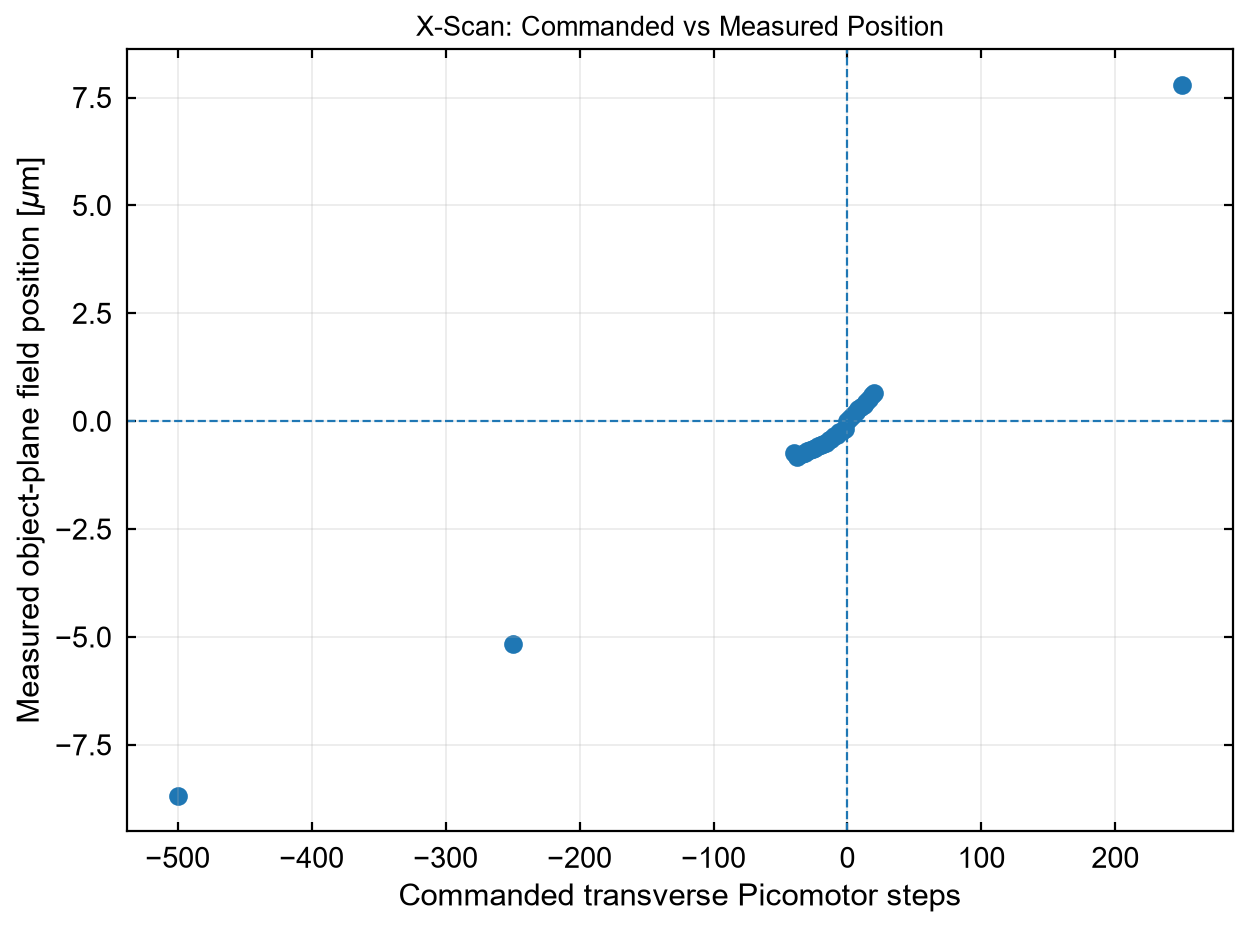

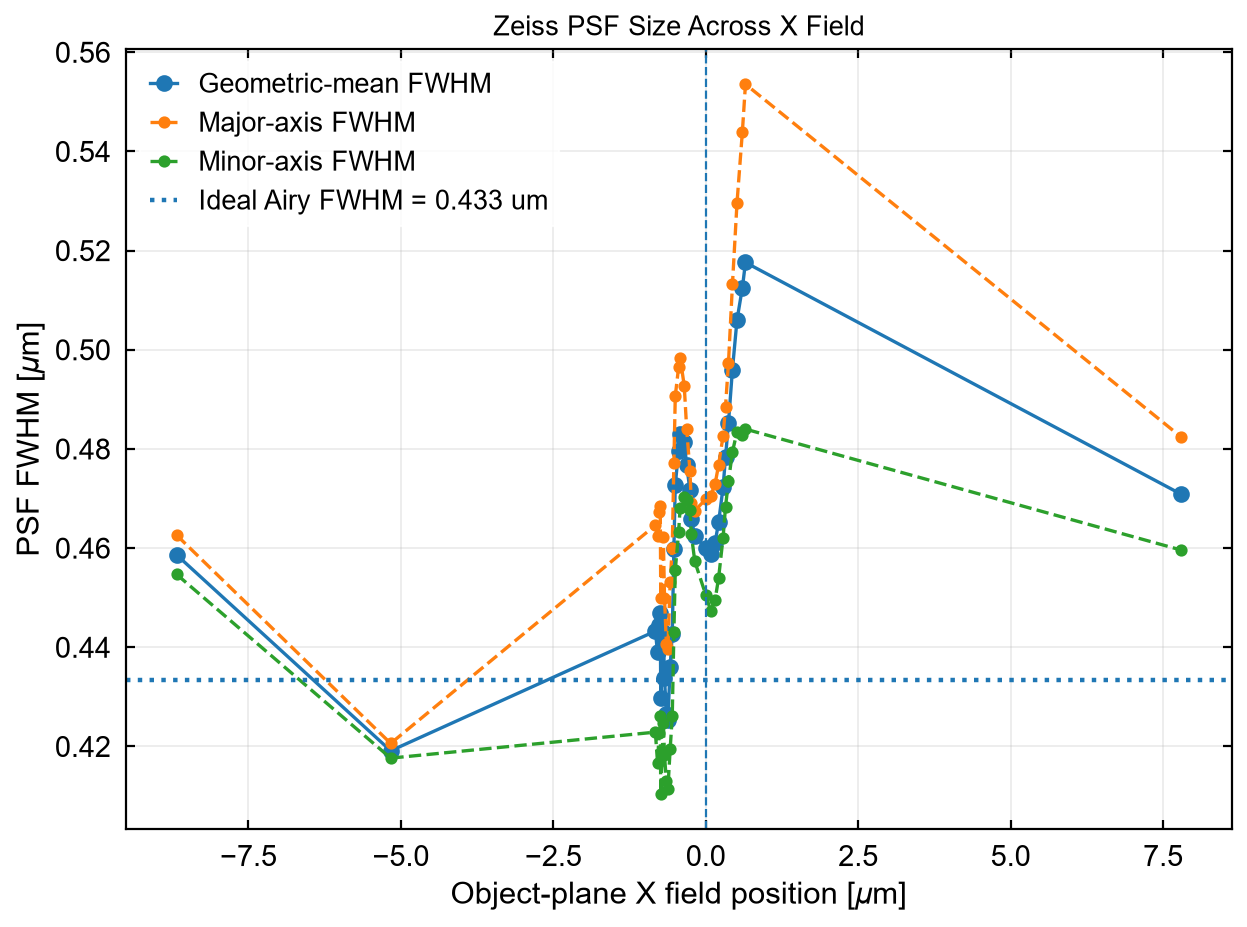

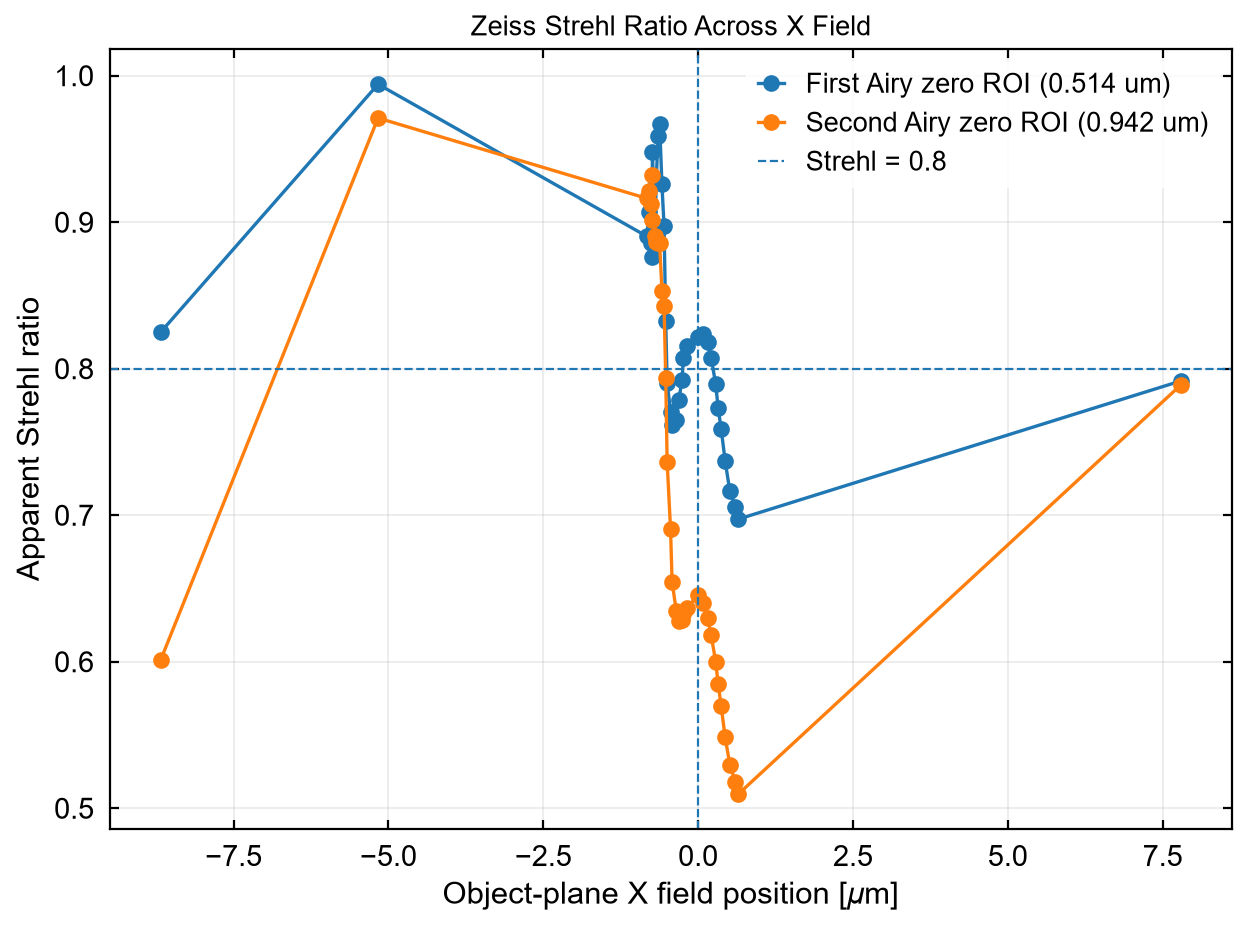

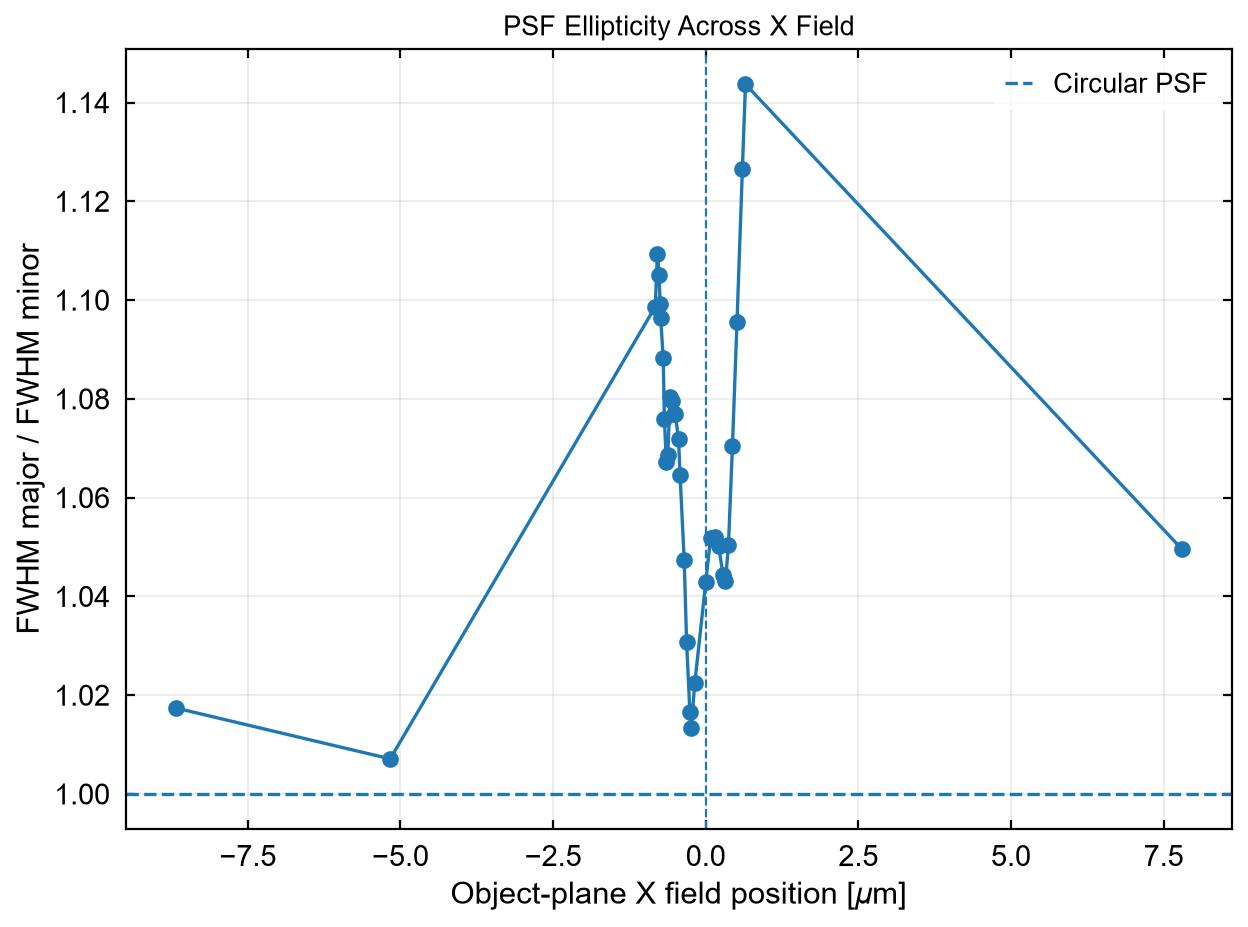

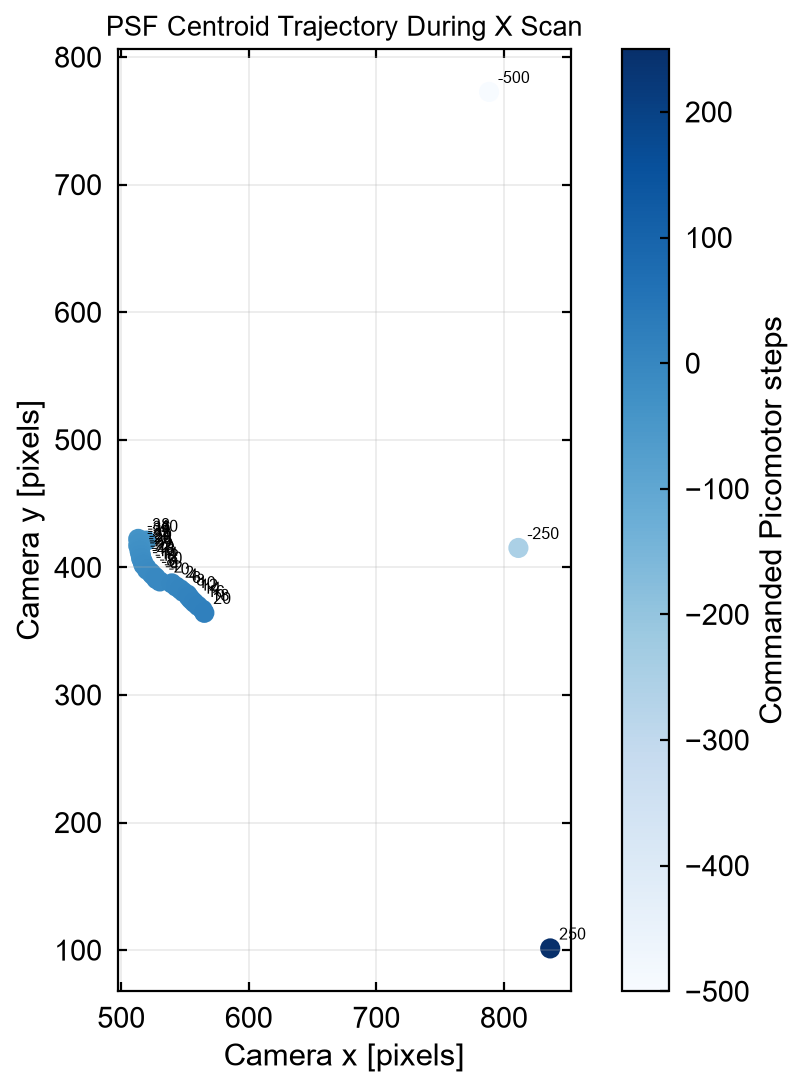

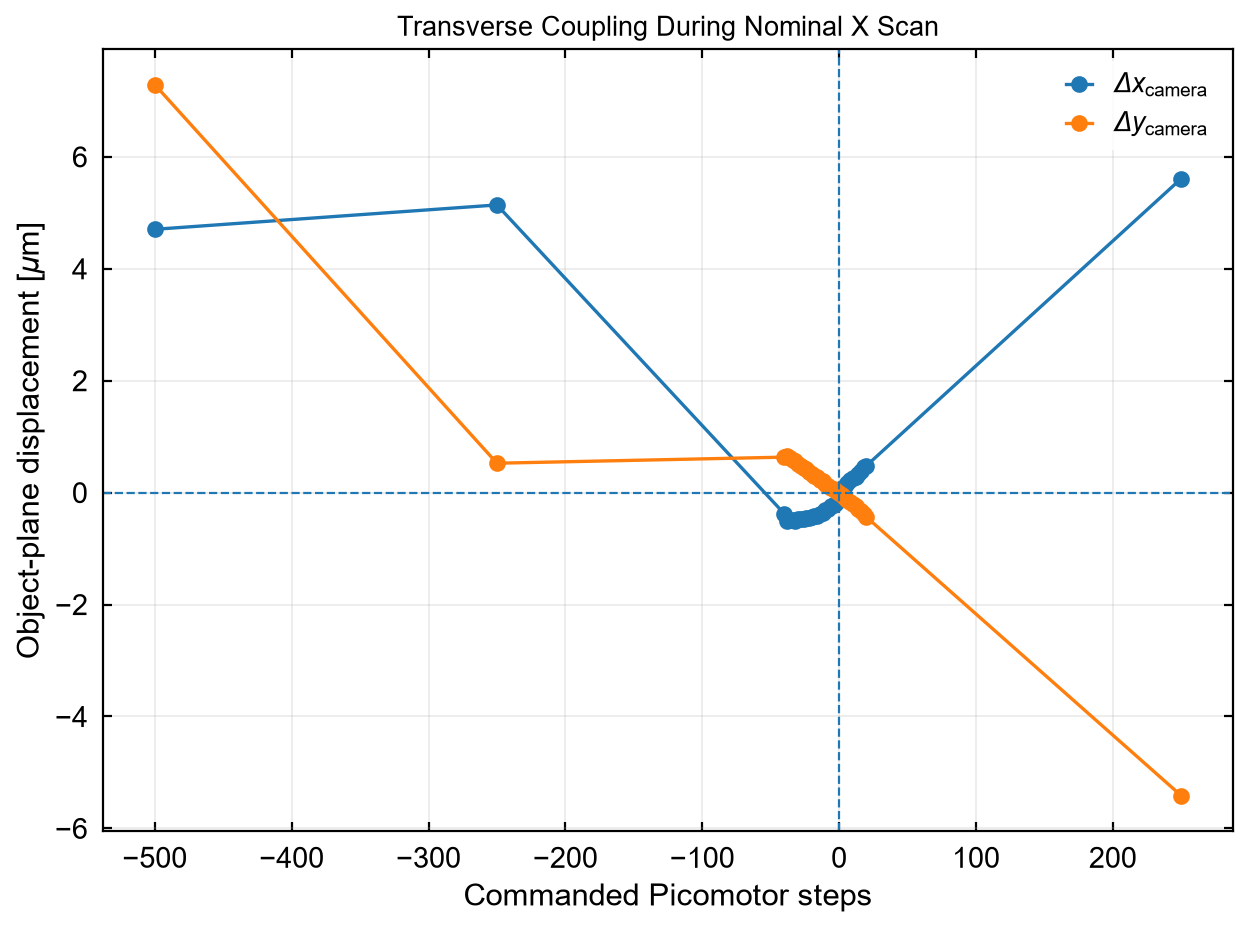

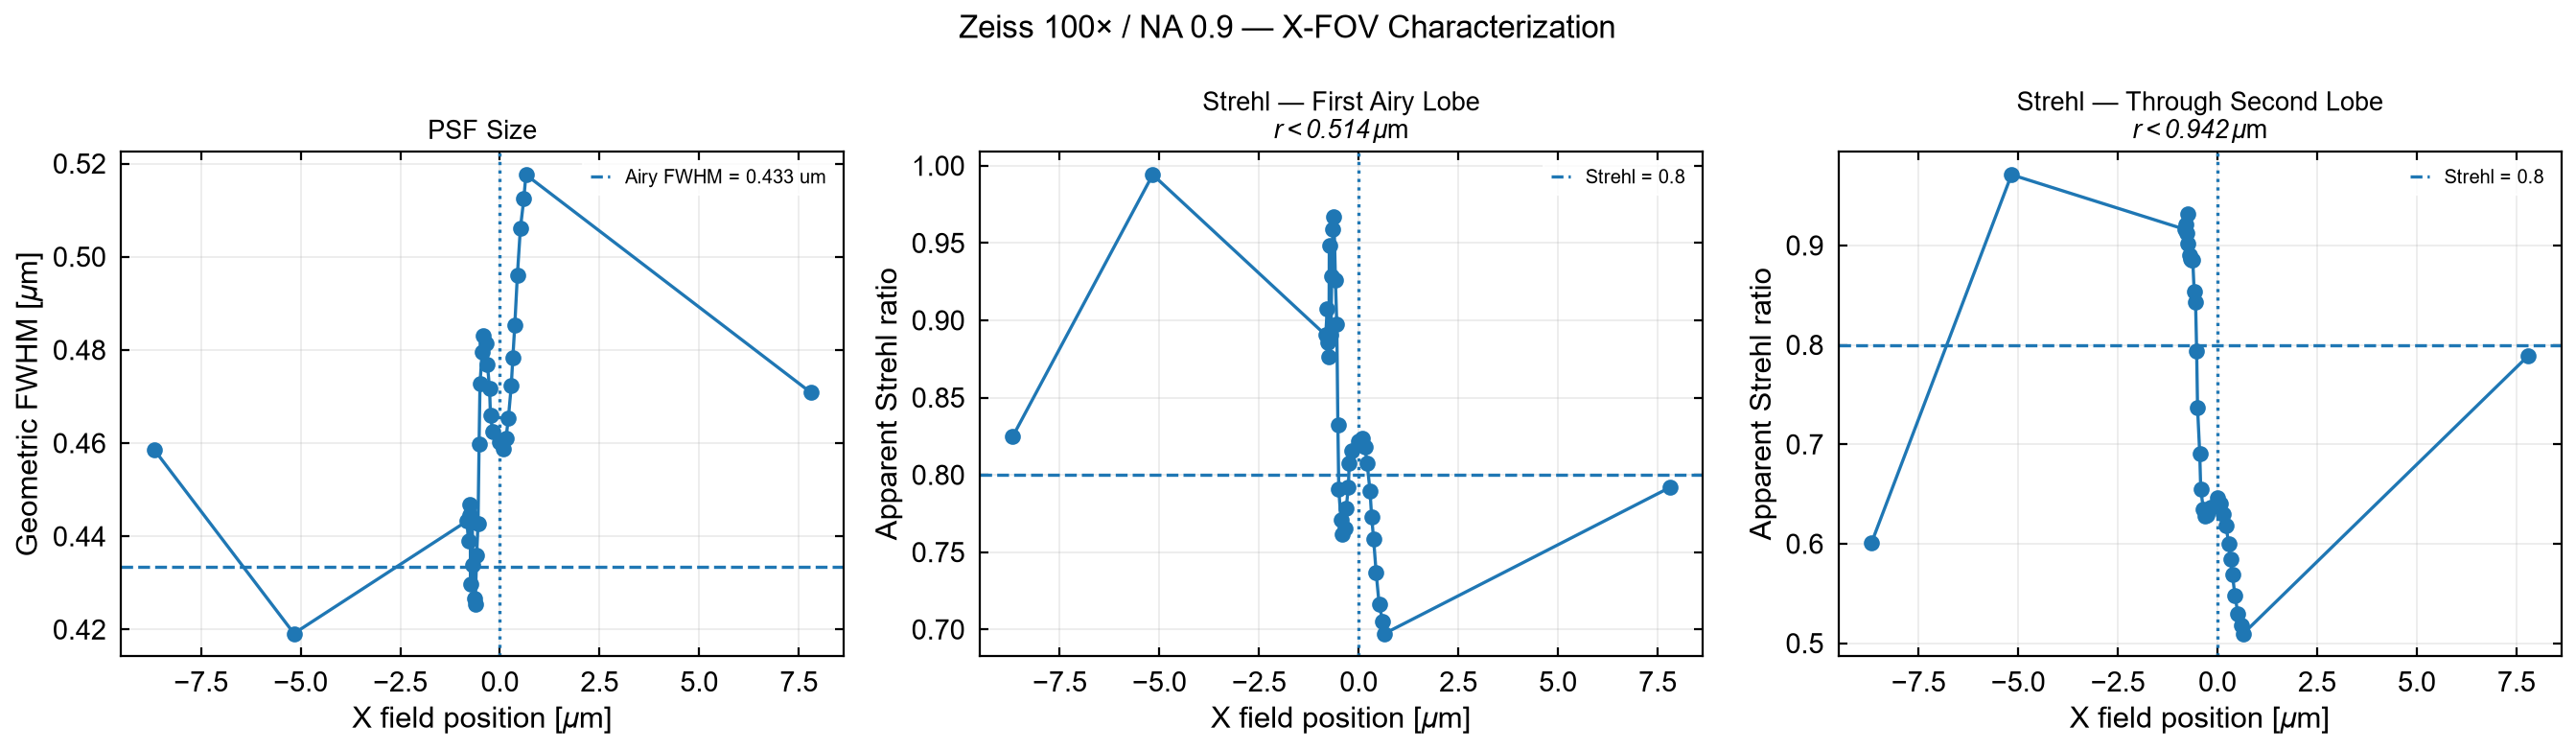


X-FOV SCAN SUMMARY
Central FWHM_geo         : 0.4601 um
Central ellipticity      : 1.0429
Central Strehl — 1st ROI : 0.8218
Central Strehl — 2nd ROI : 0.6458

Measured minimum field   : -8.678 um
Measured maximum field   : +7.800 um
Total measured X span    : 16.477 um

Positive calibration     : 31.183 nm/step
Negative calibration     : 16.524 nm/step


In [13]:
# ============================================================
# ZEISS OBJECTIVE — TRANSVERSE X-FOV SCAN
# ============================================================
#
# Folder:
# C:\Users\admin\Desktop\Projects\Zeiss test\PSFs\x_fov scan
#
# Axial position:
# fixed at previously optimized focus (~ -40 axial steps)
#
# Camera:
#   Thorlabs CS165MU1/M
#   pixel size = 3.45 um
#
# Measured magnification:
#   M = 182.3
#
# Objective:
#   Zeiss 100x / NA 0.9
#
# Lambda:
#   759 nm
#
# Analysis:
#   - auto-find PSF
#   - rotated elliptical Gaussian fit
#   - object-plane FWHM
#   - ellipticity
#   - Strehl using first Airy zero
#   - Strehl using second Airy zero
#   - actual field displacement measured from camera
#   - positive / negative Picomotor calibration separately
#
# ============================================================


from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile

from scipy.optimize import least_squares
from scipy.ndimage import gaussian_filter
from scipy.special import j1


# ============================================================
# SETTINGS
# ============================================================

FOLDER = Path(
    r"C:\Users\admin\Desktop\Projects\Zeiss test\PSFs\x_fov scan"
)

MAGNIFICATION = 182.3

CAMERA_PIXEL_UM = 3.45

OBJECT_PIXEL_UM = (
    CAMERA_PIXEL_UM
    /
    MAGNIFICATION
)

WAVELENGTH_UM = 0.759

NA = 0.90


# Gaussian fitting ROI
ROI_HALF = 70


# Near-field points used for Picomotor calibration
CALIBRATION_MAX_STEP = 40


SAVE_RESULTS = True

PRINT_EACH_IMAGE = True


# ============================================================
# DIFFRACTION REFERENCE
# ============================================================

J1_ZERO_1 = 3.831705970
J1_ZERO_2 = 7.015586670


R_AIRY_1_UM = (
    J1_ZERO_1
    *
    WAVELENGTH_UM
    /
    (2 * np.pi * NA)
)


R_AIRY_2_UM = (
    J1_ZERO_2
    *
    WAVELENGTH_UM
    /
    (2 * np.pi * NA)
)


AIRY_FWHM_UM = (
    0.514
    *
    WAVELENGTH_UM
    /
    NA
)


print("=" * 70)

print(
    f"Object-plane sampling   : "
    f"{OBJECT_PIXEL_UM:.6f} um/pixel"
)

print(
    f"                        = "
    f"{OBJECT_PIXEL_UM*1000:.2f} nm/pixel"
)

print(
    f"Ideal Airy FWHM         : "
    f"{AIRY_FWHM_UM:.4f} um"
)

print(
    f"First Airy zero radius  : "
    f"{R_AIRY_1_UM:.4f} um"
)

print(
    f"Second Airy zero radius : "
    f"{R_AIRY_2_UM:.4f} um"
)

print("=" * 70)


# ============================================================
# ROTATED ELLIPTICAL GAUSSIAN
# ============================================================

def gaussian_2d(params, x, y):

    bg, amp, x0, y0, sx, sy, theta = params

    ct = np.cos(theta)
    st = np.sin(theta)

    xp = (
        (x - x0) * ct
        +
        (y - y0) * st
    )

    yp = (
        -(x - x0) * st
        +
        (y - y0) * ct
    )

    return (
        bg
        +
        amp
        *
        np.exp(
            -0.5
            *
            (
                (xp / sx)**2
                +
                (yp / sy)**2
            )
        )
    )


# ============================================================
# AUTO-LOCATE PSF
# ============================================================

def find_psf_center(image):

    img = image.astype(float)

    img = (
        img
        -
        np.median(img)
    )

    smooth = gaussian_filter(
        img,
        sigma=5
    )

    iy, ix = np.unravel_index(
        np.argmax(smooth),
        smooth.shape
    )

    return (
        float(ix),
        float(iy)
    )


# ============================================================
# INITIAL GAUSSIAN ESTIMATE
# ============================================================

def initial_guess(img):

    h, w = img.shape

    edge = np.concatenate([
        img[:5, :].ravel(),
        img[-5:, :].ravel(),
        img[:, :5].ravel(),
        img[:, -5:].ravel()
    ])

    bg = np.median(edge)

    signal = (
        img.astype(float)
        -
        bg
    )

    signal = np.clip(
        signal,
        0,
        None
    )

    yy, xx = np.indices(
        img.shape
    )


    if signal.max() <= 0:

        return [
            bg,
            1,
            w / 2,
            h / 2,
            10,
            10,
            0
        ]


    threshold = (
        0.1
        *
        signal.max()
    )


    weights = np.where(
        signal > threshold,
        signal,
        0
    )


    if weights.sum() <= 0:
        weights = signal


    norm = weights.sum()


    if norm <= 0:

        return [
            bg,
            signal.max(),
            w / 2,
            h / 2,
            10,
            10,
            0
        ]


    x0 = (
        weights * xx
    ).sum() / norm

    y0 = (
        weights * yy
    ).sum() / norm


    dx = xx - x0
    dy = yy - y0


    var_x = (
        weights * dx**2
    ).sum() / norm

    var_y = (
        weights * dy**2
    ).sum() / norm

    cov_xy = (
        weights * dx * dy
    ).sum() / norm


    covariance = np.array([
        [var_x, cov_xy],
        [cov_xy, var_y]
    ])


    eigvals, eigvecs = np.linalg.eigh(
        covariance
    )


    eigvals = np.clip(
        eigvals,
        1.0,
        None
    )


    order = np.argsort(
        eigvals
    )[::-1]


    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]


    sx = np.sqrt(
        eigvals[0]
    )

    sy = np.sqrt(
        eigvals[1]
    )


    sx = np.clip(
        sx,
        2,
        30
    )

    sy = np.clip(
        sy,
        2,
        30
    )


    vx, vy = eigvecs[:, 0]


    theta = np.arctan2(
        vy,
        vx
    )


    amp = signal.max()


    return [
        bg,
        amp,
        x0,
        y0,
        sx,
        sy,
        theta
    ]


# ============================================================
# GAUSSIAN FIT
# ============================================================

def fit_gaussian(img):

    img = img.astype(float)

    h, w = img.shape

    yy, xx = np.indices(
        img.shape
    )


    p0 = initial_guess(
        img
    )


    p05, p95 = np.percentile(
        img,
        [5, 95]
    )


    scale = max(
        p95 - p05,
        1
    )


    def residuals(params):

        model = gaussian_2d(
            params,
            xx,
            yy
        )

        return (
            (model - img)
            /
            scale
        ).ravel()


    lower = [
        -np.inf,
        0,
        0,
        0,
        0.5,
        0.5,
        -np.pi
    ]


    upper = [
        np.inf,
        np.inf,
        w - 1,
        h - 1,
        ROI_HALF,
        ROI_HALF,
        np.pi
    ]


    fit = least_squares(
        residuals,
        p0,
        bounds=(lower, upper),
        loss="soft_l1",
        f_scale=1.0,
        max_nfev=3000
    )


    params = fit.x


    model = gaussian_2d(
        params,
        xx,
        yy
    )


    ss_res = np.sum(
        (img - model)**2
    )

    ss_tot = np.sum(
        (img - np.mean(img))**2
    )


    if ss_tot > 0:

        r2 = (
            1
            -
            ss_res / ss_tot
        )

    else:

        r2 = np.nan


    return (
        params,
        model,
        r2
    )


# ============================================================
# STREHL RATIO
# ============================================================

def calculate_strehl(
    roi,
    x0,
    y0,
    background,
    radius_um,
    gaussian_peak
):

    roi = roi.astype(float)

    yy, xx = np.indices(
        roi.shape
    )


    dx_um = (
        xx - x0
    ) * OBJECT_PIXEL_UM

    dy_um = (
        yy - y0
    ) * OBJECT_PIXEL_UM


    r_um = np.sqrt(
        dx_um**2
        +
        dy_um**2
    )


    mask = (
        r_um <= radius_um
    )


    # --------------------------------------------------------
    # Check whether entire circular ROI fits
    # --------------------------------------------------------

    max_available_radius = min(

        x0,
        roi.shape[1] - 1 - x0,
        y0,
        roi.shape[0] - 1 - y0

    ) * OBJECT_PIXEL_UM


    if max_available_radius < radius_um:

        return np.nan


    # --------------------------------------------------------
    # Measured PSF
    # --------------------------------------------------------

    measured = (
        roi
        -
        background
    )


    measured_energy = np.sum(
        measured[mask]
    )


    if measured_energy <= 0:

        return np.nan


    # --------------------------------------------------------
    # Ideal Airy PSF
    # --------------------------------------------------------

    u = (
        2
        *
        np.pi
        *
        NA
        *
        r_um
        /
        WAVELENGTH_UM
    )


    ideal = np.ones_like(
        r_um,
        dtype=float
    )


    nz = (
        np.abs(u) > 1e-12
    )


    ideal[nz] = (
        2
        *
        j1(u[nz])
        /
        u[nz]
    )**2


    ideal_energy = np.sum(
        ideal[mask]
    )


    ideal_peak = np.max(
        ideal
    )


    measured_normalized_peak = (
        gaussian_peak
        /
        measured_energy
    )


    ideal_normalized_peak = (
        ideal_peak
        /
        ideal_energy
    )


    return (
        measured_normalized_peak
        /
        ideal_normalized_peak
    )


# ============================================================
# FIND FILES
# ============================================================

files = []


for f in FOLDER.glob("*.tif"):

    try:

        step = int(
            f.stem
        )

        files.append(
            (step, f)
        )

    except ValueError:

        print(
            f"Skipping: {f.name}"
        )


files.sort(
    key=lambda x: x[0]
)


if len(files) == 0:

    raise RuntimeError(
        f"No TIFF files found in:\n{FOLDER}"
    )


print()

print("=" * 70)

print(
    f"Found {len(files)} TIFF images."
)

print(
    f"Commanded range: "
    f"{files[0][0]} to {files[-1][0]} steps"
)

print("=" * 70)


# ============================================================
# ANALYZE EVERY IMAGE
# ============================================================

FWHM_FACTOR = (
    2
    *
    np.sqrt(
        2 * np.log(2)
    )
)


results = []


for command_step, filename in files:


    image = tifffile.imread(
        filename
    )


    image = np.squeeze(
        image
    )


    if image.ndim != 2:

        print(
            f"Skipping {filename.name}: "
            f"shape={image.shape}"
        )

        continue


    # --------------------------------------------------------
    # Find PSF
    # --------------------------------------------------------

    x_guess, y_guess = find_psf_center(
        image
    )


    xc = int(
        round(x_guess)
    )

    yc = int(
        round(y_guess)
    )


    # --------------------------------------------------------
    # ROI
    # --------------------------------------------------------

    x1 = max(
        0,
        xc - ROI_HALF
    )

    x2 = min(
        image.shape[1],
        xc + ROI_HALF + 1
    )

    y1 = max(
        0,
        yc - ROI_HALF
    )

    y2 = min(
        image.shape[0],
        yc + ROI_HALF + 1
    )


    roi = image[
        y1:y2,
        x1:x2
    ]


    if (
        roi.shape[0] < 30
        or
        roi.shape[1] < 30
    ):

        print(
            f"Skipping {filename.name}: "
            f"ROI too small {roi.shape}"
        )

        continue


    # --------------------------------------------------------
    # Fit
    # --------------------------------------------------------

    try:

        params, model, r2 = fit_gaussian(
            roi
        )

    except Exception as exc:

        print(
            f"Fit failed for {filename.name}: "
            f"{exc}"
        )

        continue


    (
        background,
        amplitude,
        x0,
        y0,
        sx,
        sy,
        theta
    ) = params


    # Full camera centroid
    x_global = (
        x1 + x0
    )

    y_global = (
        y1 + y0
    )


    # --------------------------------------------------------
    # Widths
    # --------------------------------------------------------

    sigma_major = max(
        sx,
        sy
    )

    sigma_minor = min(
        sx,
        sy
    )


    fwhm_major_px = (
        FWHM_FACTOR
        *
        sigma_major
    )

    fwhm_minor_px = (
        FWHM_FACTOR
        *
        sigma_minor
    )


    fwhm_geo_px = np.sqrt(
        fwhm_major_px
        *
        fwhm_minor_px
    )


    fwhm_major_um = (
        fwhm_major_px
        *
        OBJECT_PIXEL_UM
    )

    fwhm_minor_um = (
        fwhm_minor_px
        *
        OBJECT_PIXEL_UM
    )

    fwhm_geo_um = (
        fwhm_geo_px
        *
        OBJECT_PIXEL_UM
    )


    ellipticity = (
        fwhm_major_px
        /
        fwhm_minor_px
    )


    # --------------------------------------------------------
    # Strehl
    # --------------------------------------------------------

    strehl_1 = calculate_strehl(

        roi,
        x0,
        y0,
        background,
        R_AIRY_1_UM,
        amplitude

    )


    strehl_2 = calculate_strehl(

        roi,
        x0,
        y0,
        background,
        R_AIRY_2_UM,
        amplitude

    )


    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    results.append({

        "command_step":
            command_step,

        "x_centroid_px":
            x_global,

        "y_centroid_px":
            y_global,

        "fwhm_major_px":
            fwhm_major_px,

        "fwhm_minor_px":
            fwhm_minor_px,

        "fwhm_geo_px":
            fwhm_geo_px,

        "fwhm_major_um":
            fwhm_major_um,

        "fwhm_minor_um":
            fwhm_minor_um,

        "fwhm_geo_um":
            fwhm_geo_um,

        "ellipticity":
            ellipticity,

        "strehl_first_lobe":
            strehl_1,

        "strehl_second_lobe":
            strehl_2,

        "background":
            background,

        "amplitude":
            amplitude,

        "theta_rad":
            theta,

        "R2":
            r2,

        "filename":
            filename.name

    })


    if PRINT_EACH_IMAGE:

        print(

            f"{command_step:+5d}   "

            f"x={x_global:8.2f}   "

            f"y={y_global:8.2f}   "

            f"FWHM={fwhm_geo_um:7.4f} um   "

            f"ellip={ellipticity:6.3f}   "

            f"S1={strehl_1:7.3f}   "

            f"S2={strehl_2:7.3f}   "

            f"R²={r2:7.5f}"

        )


# ============================================================
# DATAFRAME
# ============================================================

df = pd.DataFrame(
    results
)


if len(df) == 0:

    raise RuntimeError(
        "No images successfully analyzed."
    )


df.sort_values(
    "command_step",
    inplace=True
)


df.reset_index(
    drop=True,
    inplace=True
)


# ============================================================
# REFERENCE POSITION = 0.tif
# ============================================================

row0 = df.loc[
    df["command_step"] == 0
]


if len(row0) != 1:

    raise RuntimeError(
        "Could not uniquely identify 0.tif"
    )


x_ref = float(
    row0.iloc[0][
        "x_centroid_px"
    ]
)

y_ref = float(
    row0.iloc[0][
        "y_centroid_px"
    ]
)


# ============================================================
# CAMERA DISPLACEMENT FROM ZERO
# ============================================================

df["dx_camera_px"] = (
    df["x_centroid_px"]
    -
    x_ref
)


df["dy_camera_px"] = (
    df["y_centroid_px"]
    -
    y_ref
)


df["radial_camera_displacement_px"] = np.sqrt(

    df["dx_camera_px"]**2
    +
    df["dy_camera_px"]**2

)


# ============================================================
# ACTUAL OBJECT-PLANE FIELD DISTANCE
#
# IMPORTANT:
#
# We use measured centroid displacement directly.
#
# Positive command -> positive signed field coordinate
# Negative command -> negative signed field coordinate
#
# This avoids forcing the two hysteretic branches onto one
# common motion vector.
# ============================================================

command_sign = np.sign(
    df["command_step"]
)


df["field_position_um"] = (

    command_sign
    *
    df["radial_camera_displacement_px"]
    *
    OBJECT_PIXEL_UM

)


# 0 should explicitly be exactly zero
df.loc[
    df["command_step"] == 0,
    "field_position_um"
] = 0.0


# ============================================================
# DISTANCE FROM CENTER — UNSIGNED
# ============================================================

df["field_radius_um"] = (

    df["radial_camera_displacement_px"]
    *
    OBJECT_PIXEL_UM

)


# ============================================================
# NEAR-FIELD CALIBRATION
# ============================================================

cal = df[
    np.abs(
        df["command_step"]
    )
    <=
    CALIBRATION_MAX_STEP
].copy()


positive = cal[
    cal["command_step"] > 0
].copy()


negative = cal[
    cal["command_step"] < 0
].copy()


# ============================================================
# POSITIVE BRANCH
# ============================================================

pos_fit = None


if len(positive) >= 2:

    pos_fit = np.polyfit(

        positive["command_step"],

        positive["field_radius_um"],

        1

    )


# ============================================================
# NEGATIVE BRANCH
# ============================================================

neg_fit = None


if len(negative) >= 2:

    # Use magnitude of command for physical step calibration

    neg_fit = np.polyfit(

        np.abs(
            negative["command_step"]
        ),

        negative["field_radius_um"],

        1

    )


# ============================================================
# PRINT CALIBRATION
# ============================================================

print()

print("=" * 70)

print("X-SCAN PICOMOTOR CALIBRATION")

print("=" * 70)


if pos_fit is not None:

    print(
        f"Positive direction : "
        f"{pos_fit[0]*1000:.3f} nm/step"
    )


if neg_fit is not None:

    print(
        f"Negative direction : "
        f"{neg_fit[0]*1000:.3f} nm/step"
    )


if (
    pos_fit is not None
    and
    neg_fit is not None
):

    difference = (
        abs(
            pos_fit[0]
            -
            neg_fit[0]
        )
        *
        1000
    )

    print(
        f"Difference          : "
        f"{difference:.3f} nm/step"
    )


print("=" * 70)


# ============================================================
# FAR POINTS
# ============================================================

print()

print("=" * 70)

print("MEASURED FAR-FIELD POSITIONS")

print("=" * 70)


far_commands = [
    -500,
    -250,
    250,
    500
]


for command in far_commands:

    row = df.loc[
        df["command_step"] == command
    ]


    if len(row) == 1:

        field = float(
            row.iloc[0][
                "field_position_um"
            ]
        )

        fwhm = float(
            row.iloc[0][
                "fwhm_geo_um"
            ]
        )

        strehl = float(
            row.iloc[0][
                "strehl_second_lobe"
            ]
        )


        print(

            f"{command:+5d} steps -> "

            f"{field:+8.3f} um   "

            f"FWHM={fwhm:.4f} um   "

            f"S2={strehl:.3f}"

        )


print("=" * 70)


# ============================================================
# SAVE CSV
# ============================================================

CSV_OUT = (
    FOLDER
    /
    "x_fov_analysis.csv"
)


df.to_csv(
    CSV_OUT,
    index=False
)


print(
    f"\nSaved results to:\n{CSV_OUT}"
)


# ============================================================
# SORT BY REAL FIELD POSITION
# ============================================================

df_field = df.sort_values(
    "field_position_um"
).copy()


# ============================================================
# FIGURE 1
#
# COMMAND -> ACTUAL FIELD POSITION
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


ax.scatter(

    df["command_step"],

    df["field_position_um"],

    s=55

)


ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)


ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)


ax.set_xlabel(
    "Commanded transverse Picomotor steps"
)


ax.set_ylabel(
    r"Measured object-plane field position [$\mu$m]"
)


ax.set_title(
    "X-Scan: Commanded vs Measured Position"
)


ax.grid(
    alpha=0.25
)


fig.tight_layout()


if SAVE_RESULTS:

    fig.savefig(

        FOLDER
        /
        "01_x_scan_calibration.png",

        dpi=250,

        bbox_inches="tight"

    )


plt.show()


# ============================================================
# FIGURE 2
#
# FWHM VS ACTUAL FIELD POSITION
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


ax.plot(

    df_field["field_position_um"],

    df_field["fwhm_geo_um"],

    "o-",

    label="Geometric-mean FWHM"

)


ax.plot(

    df_field["field_position_um"],

    df_field["fwhm_major_um"],

    "o--",

    markersize=4,

    label="Major-axis FWHM"

)


ax.plot(

    df_field["field_position_um"],

    df_field["fwhm_minor_um"],

    "o--",

    markersize=4,

    label="Minor-axis FWHM"

)


ax.axhline(

    AIRY_FWHM_UM,

    linestyle=":",

    linewidth=2,

    label=(
        f"Ideal Airy FWHM = "
        f"{AIRY_FWHM_UM:.3f} um"
    )

)


ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)


ax.set_xlabel(
    r"Object-plane X field position [$\mu$m]"
)


ax.set_ylabel(
    r"PSF FWHM [$\mu$m]"
)


ax.set_title(
    "Zeiss PSF Size Across X Field"
)


ax.grid(
    alpha=0.25
)


ax.legend()


fig.tight_layout()


if SAVE_RESULTS:

    fig.savefig(

        FOLDER
        /
        "02_FWHM_vs_x_field.png",

        dpi=250,

        bbox_inches="tight"

    )


plt.show()


# ============================================================
# FIGURE 3
#
# STREHL VS FIELD
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


ax.plot(

    df_field["field_position_um"],

    df_field["strehl_first_lobe"],

    "o-",

    label=(
        f"First Airy zero ROI "
        f"({R_AIRY_1_UM:.3f} um)"
    )

)


ax.plot(

    df_field["field_position_um"],

    df_field["strehl_second_lobe"],

    "o-",

    label=(
        f"Second Airy zero ROI "
        f"({R_AIRY_2_UM:.3f} um)"
    )

)


ax.axhline(

    0.8,

    linestyle="--",

    linewidth=1,

    label="Strehl = 0.8"

)


ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)


ax.set_xlabel(
    r"Object-plane X field position [$\mu$m]"
)


ax.set_ylabel(
    "Apparent Strehl ratio"
)


ax.set_title(
    "Zeiss Strehl Ratio Across X Field"
)


ax.grid(
    alpha=0.25
)


ax.legend()


fig.tight_layout()


if SAVE_RESULTS:

    fig.savefig(

        FOLDER
        /
        "03_strehl_vs_x_field.png",

        dpi=250,

        bbox_inches="tight"

    )


plt.show()


# ============================================================
# FIGURE 4
#
# ELLIPTICITY VS FIELD
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


ax.plot(

    df_field["field_position_um"],

    df_field["ellipticity"],

    "o-"

)


ax.axhline(

    1,

    linestyle="--",

    label="Circular PSF"

)


ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)


ax.set_xlabel(
    r"Object-plane X field position [$\mu$m]"
)


ax.set_ylabel(
    "FWHM major / FWHM minor"
)


ax.set_title(
    "PSF Ellipticity Across X Field"
)


ax.grid(
    alpha=0.25
)


ax.legend()


fig.tight_layout()


if SAVE_RESULTS:

    fig.savefig(

        FOLDER
        /
        "04_ellipticity_vs_x_field.png",

        dpi=250,

        bbox_inches="tight"

    )


plt.show()


# ============================================================
# FIGURE 5
#
# ACTUAL 2D CAMERA TRAJECTORY
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 7)
)


sc = ax.scatter(

    df["x_centroid_px"],

    df["y_centroid_px"],

    c=df["command_step"],

    s=65

)


for _, row in df.iterrows():

    ax.annotate(

        f"{int(row['command_step'])}",

        (
            row["x_centroid_px"],
            row["y_centroid_px"]
        ),

        xytext=(4, 4),

        textcoords="offset points",

        fontsize=7

    )


plt.colorbar(

    sc,

    ax=ax,

    label="Commanded Picomotor steps"

)


ax.set_xlabel(
    "Camera x [pixels]"
)


ax.set_ylabel(
    "Camera y [pixels]"
)


ax.set_title(
    "PSF Centroid Trajectory During X Scan"
)


ax.grid(
    alpha=0.25
)


ax.set_aspect(
    "equal",
    adjustable="box"
)


fig.tight_layout()


if SAVE_RESULTS:

    fig.savefig(

        FOLDER
        /
        "05_x_scan_centroid_trajectory.png",

        dpi=250,

        bbox_inches="tight"

    )


plt.show()


# ============================================================
# FIGURE 6
#
# CAMERA X AND Y MOTION SEPARATELY
#
# Useful because the stage may couple nominal X translation
# into both camera coordinates.
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


ax.plot(

    df["command_step"],

    df["dx_camera_px"]
    *
    OBJECT_PIXEL_UM,

    "o-",

    label=r"$\Delta x_{\rm camera}$"

)


ax.plot(

    df["command_step"],

    df["dy_camera_px"]
    *
    OBJECT_PIXEL_UM,

    "o-",

    label=r"$\Delta y_{\rm camera}$"

)


ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)


ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)


ax.set_xlabel(
    "Commanded Picomotor steps"
)


ax.set_ylabel(
    r"Object-plane displacement [$\mu$m]"
)


ax.set_title(
    "Transverse Coupling During Nominal X Scan"
)


ax.grid(
    alpha=0.25
)


ax.legend()


fig.tight_layout()


if SAVE_RESULTS:

    fig.savefig(

        FOLDER
        /
        "06_x_scan_xy_coupling.png",

        dpi=250,

        bbox_inches="tight"

    )


plt.show()


# ============================================================
# FIGURE 7
#
# THREE-PANEL SUMMARY
# ============================================================

fig, axes = plt.subplots(

    1,
    3,

    figsize=(17, 5)

)


# ------------------------------------------------------------
# FWHM
# ------------------------------------------------------------

ax = axes[0]


ax.plot(

    df_field["field_position_um"],

    df_field["fwhm_geo_um"],

    "o-"

)


ax.axhline(

    AIRY_FWHM_UM,

    linestyle="--",

    label=(
        f"Airy FWHM = "
        f"{AIRY_FWHM_UM:.3f} um"
    )

)


ax.axvline(
    0,
    linestyle=":"
)


ax.set_xlabel(
    r"X field position [$\mu$m]"
)


ax.set_ylabel(
    r"Geometric FWHM [$\mu$m]"
)


ax.set_title(
    "PSF Size"
)


ax.grid(
    alpha=0.25
)


ax.legend(
    fontsize=9
)


# ------------------------------------------------------------
# STREHL FIRST LOBE
# ------------------------------------------------------------

ax = axes[1]


ax.plot(

    df_field["field_position_um"],

    df_field["strehl_first_lobe"],

    "o-"

)


ax.axhline(

    0.8,

    linestyle="--",

    label="Strehl = 0.8"

)


ax.axvline(
    0,
    linestyle=":"
)


ax.set_xlabel(
    r"X field position [$\mu$m]"
)


ax.set_ylabel(
    "Apparent Strehl ratio"
)


ax.set_title(

    "Strehl — First Airy Lobe\n"
    rf"$r<{R_AIRY_1_UM:.3f}\,\mu$m"

)


ax.grid(
    alpha=0.25
)


ax.legend(
    fontsize=9
)


# ------------------------------------------------------------
# STREHL SECOND LOBE
# ------------------------------------------------------------

ax = axes[2]


ax.plot(

    df_field["field_position_um"],

    df_field["strehl_second_lobe"],

    "o-"

)


ax.axhline(

    0.8,

    linestyle="--",

    label="Strehl = 0.8"

)


ax.axvline(
    0,
    linestyle=":"
)


ax.set_xlabel(
    r"X field position [$\mu$m]"
)


ax.set_ylabel(
    "Apparent Strehl ratio"
)


ax.set_title(

    "Strehl — Through Second Lobe\n"
    rf"$r<{R_AIRY_2_UM:.3f}\,\mu$m"

)


ax.grid(
    alpha=0.25
)


ax.legend(
    fontsize=9
)


fig.suptitle(

    "Zeiss 100× / NA 0.9 — X-FOV Characterization",

    fontsize=15

)


fig.tight_layout()


if SAVE_RESULTS:

    fig.savefig(

        FOLDER
        /
        "07_x_FOV_summary.png",

        dpi=250,

        bbox_inches="tight"

    )


plt.show()


# ============================================================
# SUMMARY
# ============================================================

central = df.loc[
    df["command_step"] == 0
].iloc[0]


print()

print("=" * 70)

print("X-FOV SCAN SUMMARY")

print("=" * 70)


print(
    f"Central FWHM_geo         : "
    f"{central['fwhm_geo_um']:.4f} um"
)


print(
    f"Central ellipticity      : "
    f"{central['ellipticity']:.4f}"
)


print(
    f"Central Strehl — 1st ROI : "
    f"{central['strehl_first_lobe']:.4f}"
)


print(
    f"Central Strehl — 2nd ROI : "
    f"{central['strehl_second_lobe']:.4f}"
)


print()


print(
    f"Measured minimum field   : "
    f"{df['field_position_um'].min():+.3f} um"
)


print(
    f"Measured maximum field   : "
    f"{df['field_position_um'].max():+.3f} um"
)


print(
    f"Total measured X span    : "
    f"{df['field_position_um'].max() - df['field_position_um'].min():.3f} um"
)


print()


if pos_fit is not None:

    print(
        f"Positive calibration     : "
        f"{pos_fit[0]*1000:.3f} nm/step"
    )


if neg_fit is not None:

    print(
        f"Negative calibration     : "
        f"{neg_fit[0]*1000:.3f} nm/step"
    )


print("=" * 70)

## only the near points



X SCAN — NEAR-FIELD SUMMARY
Number of points             : 31
Commanded range              : -40 to +20
Measured field range         : -0.8273 to +0.6506 um
Total measured field span    : 1.4780 um

Mean FWHM_geo                : 0.4638 um
Std FWHM_geo                 : 0.0248 um
Minimum FWHM_geo             : 0.4253 um
Maximum FWHM_geo             : 0.5176 um

Mean Strehl — first ROI      : 0.8270
Mean Strehl — second ROI     : 0.7180
Minimum Strehl — second ROI  : 0.5098
Maximum Strehl — second ROI  : 0.9321

Mean ellipticity             : 1.0697
Mean Gaussian R²             : 0.95290

Y SCAN — NEAR-FIELD SUMMARY
Number of points             : 31
Commanded range              : -28 to +32
Measured field range         : -0.6033 to +0.6889 um
Total measured field span    : 1.2922 um

Mean FWHM_geo                : 0.4250 um
Std FWHM_geo                 : 0.0082 um
Minimum FWHM_geo             : 0.4113 um
Maximum FWHM_geo             : 0.4361 um

Mean Strehl — first ROI      : 0.9625
Me

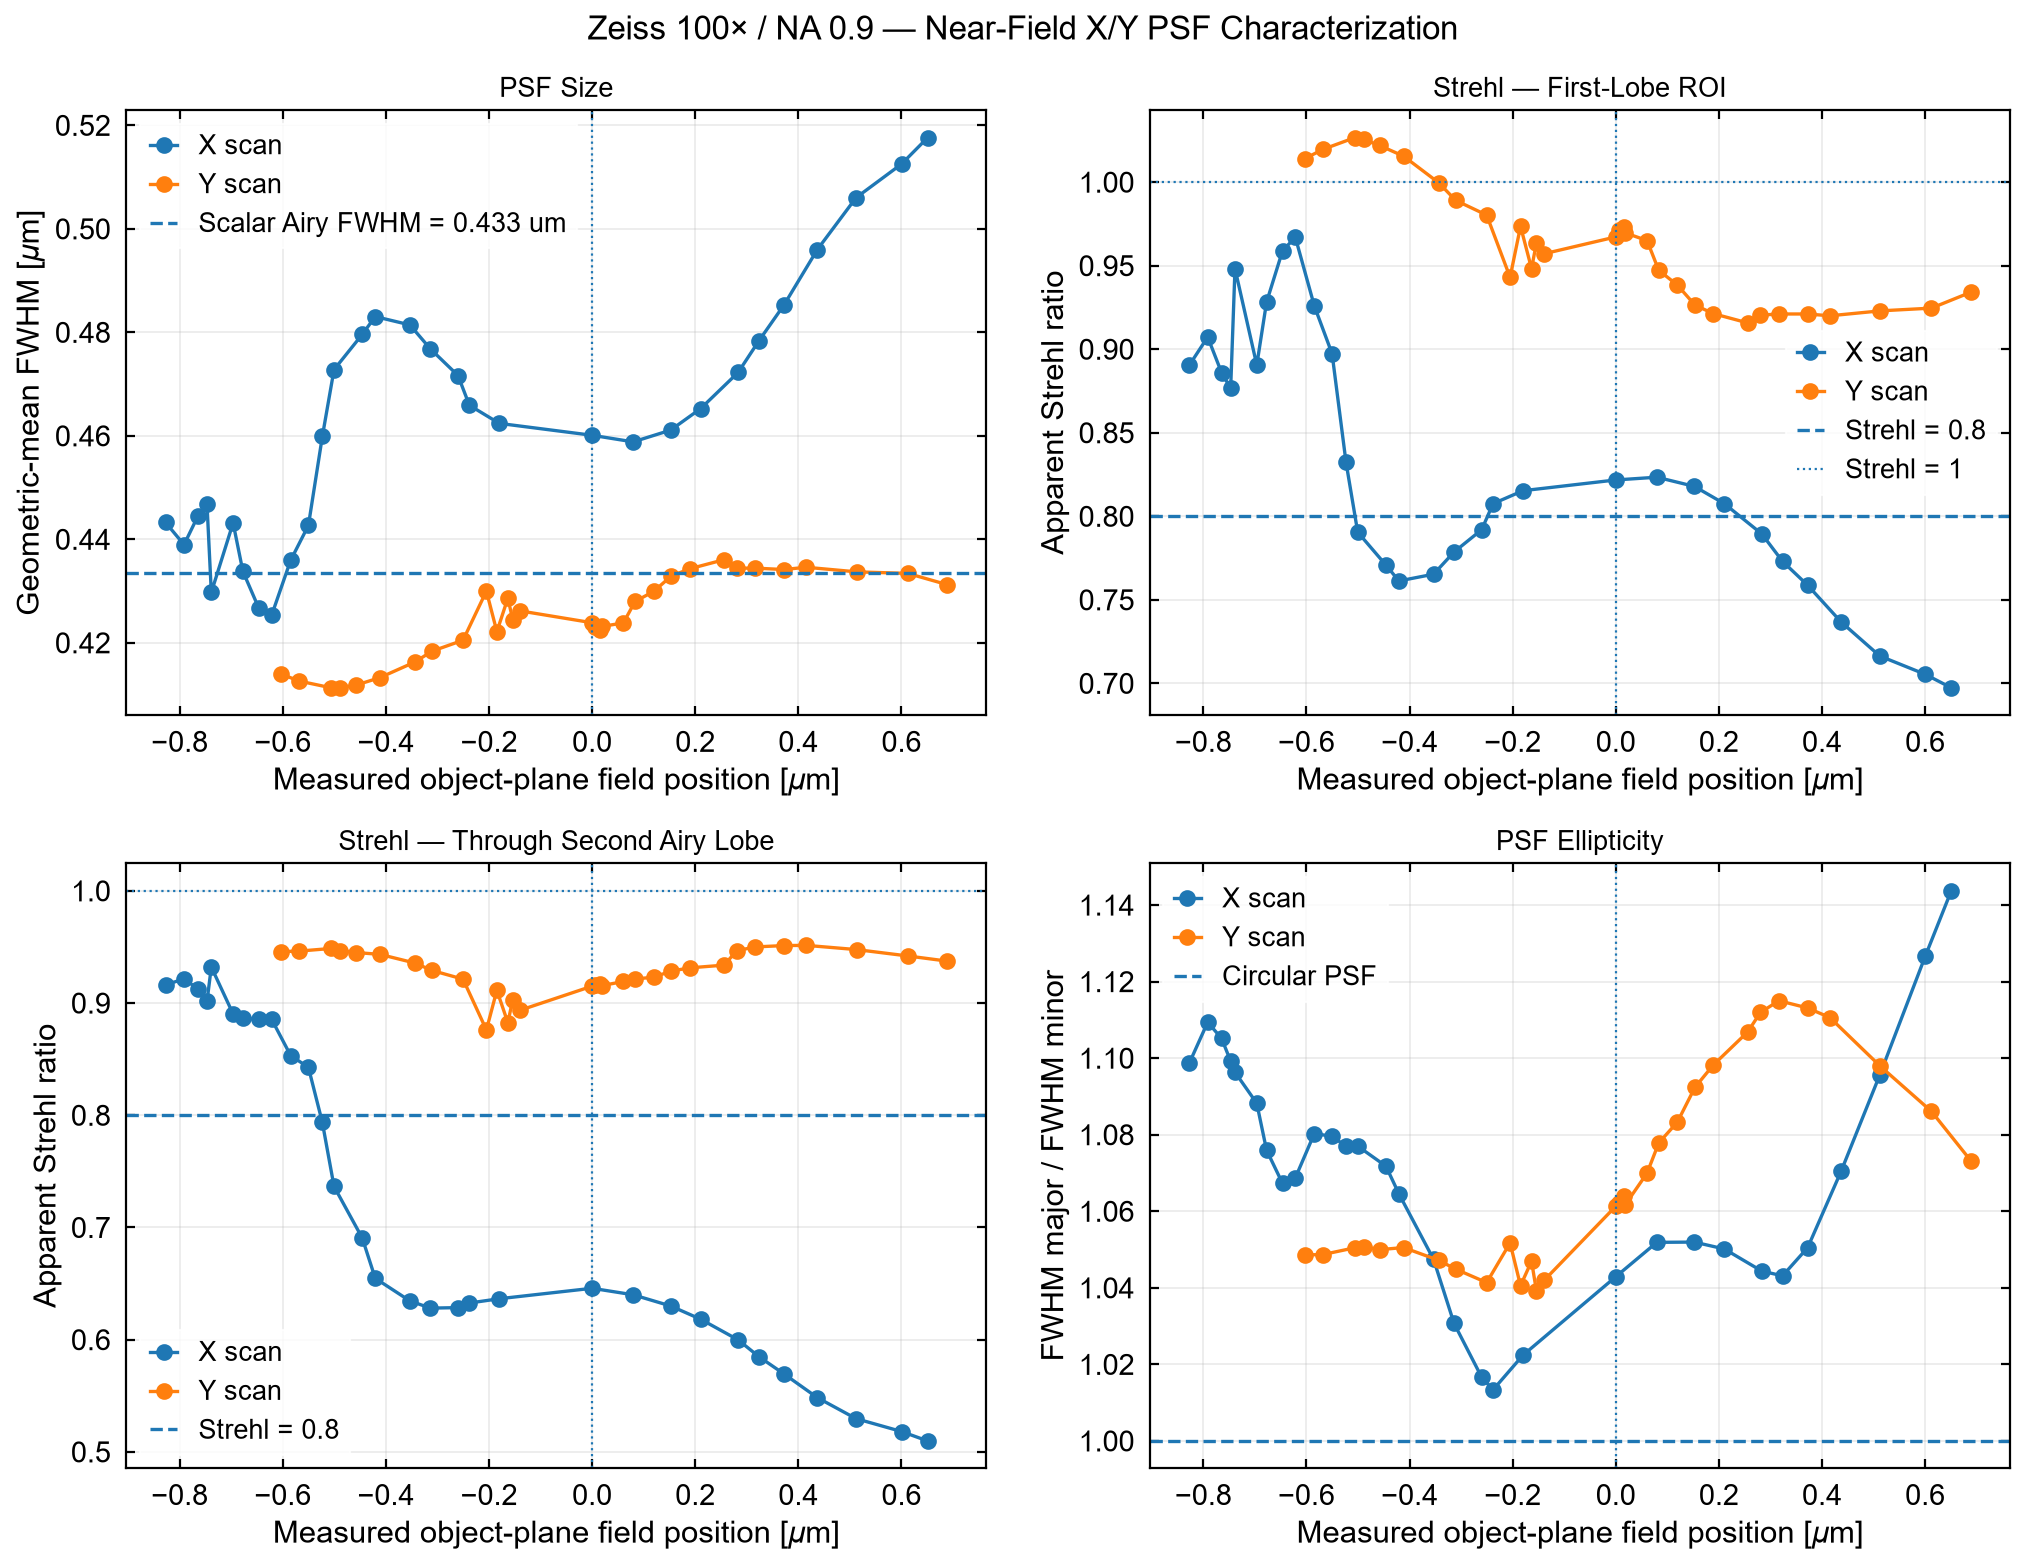

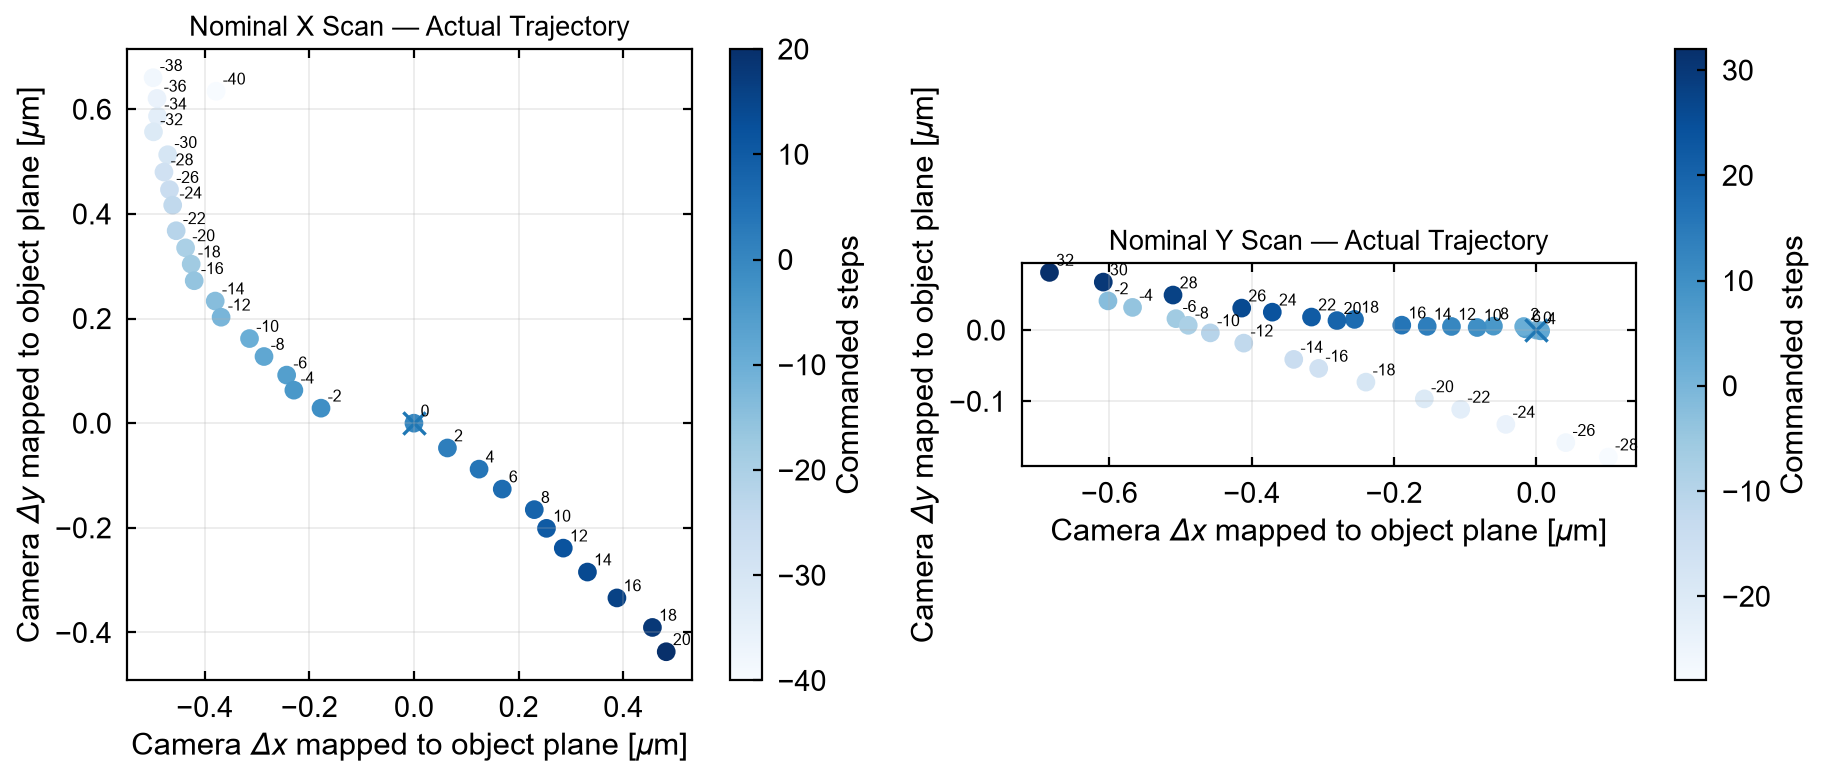

In [14]:
# ============================================================
# COMPARE NEAR-FIELD X AND Y FOV SCANS
#
# Keeps ONLY double-digit Picomotor commands:
#
#       |command step| < 100
#
# Therefore automatically excludes:
#       +/-250, +/-500, +/-600, +/-700, ...
#
# Reads the CSV files already generated:
#
#   x_fov scan\x_fov_analysis.csv
#   y_fov scan\y_fov_analysis.csv
#
# Physical transverse position is recalculated DIRECTLY from
# measured camera-centroid displacement relative to 0.tif.
#
# Camera:
#   Thorlabs CS165MU1/M
#   pixel = 3.45 um
#
# Magnification:
#   M = 182.3
#
# ============================================================


from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# SETTINGS
# ============================================================

BASE = Path(
    r"C:\Users\admin\Desktop\Projects\Zeiss test\PSFs"
)

X_FILE = (
    BASE
    / "x_fov scan"
    / "x_fov_analysis.csv"
)

Y_FILE = (
    BASE
    / "y_fov scan"
    / "y_fov_analysis.csv"
)


MAGNIFICATION = 182.3
CAMERA_PIXEL_UM = 3.45

OBJECT_PIXEL_UM = (
    CAMERA_PIXEL_UM
    /
    MAGNIFICATION
)


WAVELENGTH_UM = 0.759
NA = 0.90


AIRY_FWHM_UM = (
    0.514
    *
    WAVELENGTH_UM
    /
    NA
)


# Only double-digit commands
MAX_NEAR_STEP = 99


# ============================================================
# LOAD DATA
# ============================================================

x = pd.read_csv(X_FILE)
y = pd.read_csv(Y_FILE)


# ============================================================
# KEEP ONLY NEAR-FIELD DATA
# ============================================================

x = x[
    np.abs(x["command_step"])
    <= MAX_NEAR_STEP
].copy()


y = y[
    np.abs(y["command_step"])
    <= MAX_NEAR_STEP
].copy()


# ============================================================
# FUNCTION:
# RECALCULATE ACTUAL FIELD POSITION FROM CAMERA CENTROID
# ============================================================

def calculate_field_position(df):

    """
    Calculate actual physical displacement from 0.tif using
    the measured 2D camera centroid.

        r = sqrt(dx^2 + dy^2)

    Then convert using:

        object pixel = camera pixel / magnification

    Sign is taken from commanded Picomotor direction.

    This avoids assuming any nm/step calibration.
    """

    df = df.copy()


    # --------------------------------------------------------
    # Find 0.tif centroid
    # --------------------------------------------------------

    zero = df[
        df["command_step"] == 0
    ]


    if len(zero) != 1:

        raise RuntimeError(
            "Need exactly one command_step = 0 point."
        )


    x0 = float(
        zero.iloc[0]["x_centroid_px"]
    )

    y0 = float(
        zero.iloc[0]["y_centroid_px"]
    )


    # --------------------------------------------------------
    # Camera displacement
    # --------------------------------------------------------

    dx_px = (
        df["x_centroid_px"]
        -
        x0
    )

    dy_px = (
        df["y_centroid_px"]
        -
        y0
    )


    # --------------------------------------------------------
    # True 2D transverse distance on camera
    # --------------------------------------------------------

    dr_px = np.sqrt(
        dx_px**2
        +
        dy_px**2
    )


    # --------------------------------------------------------
    # Object-plane distance
    # --------------------------------------------------------

    dr_um = (
        dr_px
        *
        OBJECT_PIXEL_UM
    )


    # --------------------------------------------------------
    # Signed field coordinate
    #
    # negative command -> negative field
    # positive command -> positive field
    # --------------------------------------------------------

    sign = np.sign(
        df["command_step"]
    )


    df["field_um"] = (
        sign
        *
        dr_um
    )


    # explicitly make central point exactly zero
    df.loc[
        df["command_step"] == 0,
        "field_um"
    ] = 0.0


    # Save components too
    df["dx_object_um"] = (
        dx_px
        *
        OBJECT_PIXEL_UM
    )

    df["dy_object_um"] = (
        dy_px
        *
        OBJECT_PIXEL_UM
    )


    # sort by physical field coordinate
    df.sort_values(
        "field_um",
        inplace=True
    )


    df.reset_index(
        drop=True,
        inplace=True
    )


    return df


# ============================================================
# CALCULATE X AND Y PHYSICAL FIELD COORDINATES
# ============================================================

x = calculate_field_position(x)
y = calculate_field_position(y)


# ============================================================
# BASIC STATISTICS
# ============================================================

def print_summary(name, df):

    print()
    print("=" * 70)
    print(f"{name} — NEAR-FIELD SUMMARY")
    print("=" * 70)

    print(
        f"Number of points             : "
        f"{len(df)}"
    )

    print(
        f"Commanded range              : "
        f"{int(df['command_step'].min()):+d} "
        f"to "
        f"{int(df['command_step'].max()):+d}"
    )

    print(
        f"Measured field range         : "
        f"{df['field_um'].min():+.4f} "
        f"to "
        f"{df['field_um'].max():+.4f} um"
    )

    print(
        f"Total measured field span    : "
        f"{df['field_um'].max() - df['field_um'].min():.4f} um"
    )

    print()

    print(
        f"Mean FWHM_geo                : "
        f"{df['fwhm_geo_um'].mean():.4f} um"
    )

    print(
        f"Std FWHM_geo                 : "
        f"{df['fwhm_geo_um'].std():.4f} um"
    )

    print(
        f"Minimum FWHM_geo             : "
        f"{df['fwhm_geo_um'].min():.4f} um"
    )

    print(
        f"Maximum FWHM_geo             : "
        f"{df['fwhm_geo_um'].max():.4f} um"
    )

    print()

    print(
        f"Mean Strehl — first ROI      : "
        f"{df['strehl_first_lobe'].mean():.4f}"
    )

    print(
        f"Mean Strehl — second ROI     : "
        f"{df['strehl_second_lobe'].mean():.4f}"
    )

    print(
        f"Minimum Strehl — second ROI  : "
        f"{df['strehl_second_lobe'].min():.4f}"
    )

    print(
        f"Maximum Strehl — second ROI  : "
        f"{df['strehl_second_lobe'].max():.4f}"
    )

    print()

    print(
        f"Mean ellipticity             : "
        f"{df['ellipticity'].mean():.4f}"
    )

    print(
        f"Mean Gaussian R²             : "
        f"{df['R2'].mean():.5f}"
    )

    print("=" * 70)


print_summary(
    "X SCAN",
    x
)

print_summary(
    "Y SCAN",
    y
)


# ============================================================
# PRINT INDIVIDUAL NEAR-FIELD POINTS
# ============================================================

print()
print("\nX SCAN")
print(
    x[
        [
            "command_step",
            "field_um",
            "fwhm_geo_um",
            "ellipticity",
            "strehl_second_lobe",
            "R2"
        ]
    ].to_string(
        index=False
    )
)


print()
print("\nY SCAN")
print(
    y[
        [
            "command_step",
            "field_um",
            "fwhm_geo_um",
            "ellipticity",
            "strehl_second_lobe",
            "R2"
        ]
    ].to_string(
        index=False
    )
)


# ============================================================
# 4-PANEL X/Y COMPARISON
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 10)
)


# ============================================================
# PANEL 1 — FWHM
# ============================================================

ax = axes[0, 0]


ax.plot(
    x["field_um"],
    x["fwhm_geo_um"],
    "o-",
    label="X scan"
)


ax.plot(
    y["field_um"],
    y["fwhm_geo_um"],
    "o-",
    label="Y scan"
)


ax.axhline(
    AIRY_FWHM_UM,
    linestyle="--",
    label=(
        f"Scalar Airy FWHM = "
        f"{AIRY_FWHM_UM:.3f} um"
    )
)


ax.axvline(
    0,
    linestyle=":",
    linewidth=1
)


ax.set_xlabel(
    r"Measured object-plane field position [$\mu$m]"
)


ax.set_ylabel(
    r"Geometric-mean FWHM [$\mu$m]"
)


ax.set_title(
    "PSF Size"
)


ax.grid(
    alpha=0.25
)


ax.legend()


# ============================================================
# PANEL 2 — STREHL FIRST AIRY LOBE
# ============================================================

ax = axes[0, 1]


ax.plot(
    x["field_um"],
    x["strehl_first_lobe"],
    "o-",
    label="X scan"
)


ax.plot(
    y["field_um"],
    y["strehl_first_lobe"],
    "o-",
    label="Y scan"
)


ax.axhline(
    0.8,
    linestyle="--",
    label="Strehl = 0.8"
)


ax.axhline(
    1.0,
    linestyle=":",
    linewidth=1,
    label="Strehl = 1"
)


ax.axvline(
    0,
    linestyle=":",
    linewidth=1
)


ax.set_xlabel(
    r"Measured object-plane field position [$\mu$m]"
)


ax.set_ylabel(
    "Apparent Strehl ratio"
)


ax.set_title(
    "Strehl — First-Lobe ROI"
)


ax.grid(
    alpha=0.25
)


ax.legend()


# ============================================================
# PANEL 3 — STREHL SECOND AIRY LOBE
# ============================================================

ax = axes[1, 0]


ax.plot(
    x["field_um"],
    x["strehl_second_lobe"],
    "o-",
    label="X scan"
)


ax.plot(
    y["field_um"],
    y["strehl_second_lobe"],
    "o-",
    label="Y scan"
)


ax.axhline(
    0.8,
    linestyle="--",
    label="Strehl = 0.8"
)


ax.axhline(
    1.0,
    linestyle=":",
    linewidth=1
)


ax.axvline(
    0,
    linestyle=":",
    linewidth=1
)


ax.set_xlabel(
    r"Measured object-plane field position [$\mu$m]"
)


ax.set_ylabel(
    "Apparent Strehl ratio"
)


ax.set_title(
    "Strehl — Through Second Airy Lobe"
)


ax.grid(
    alpha=0.25
)


ax.legend()


# ============================================================
# PANEL 4 — ELLIPTICITY
# ============================================================

ax = axes[1, 1]


ax.plot(
    x["field_um"],
    x["ellipticity"],
    "o-",
    label="X scan"
)


ax.plot(
    y["field_um"],
    y["ellipticity"],
    "o-",
    label="Y scan"
)


ax.axhline(
    1,
    linestyle="--",
    label="Circular PSF"
)


ax.axvline(
    0,
    linestyle=":",
    linewidth=1
)


ax.set_xlabel(
    r"Measured object-plane field position [$\mu$m]"
)


ax.set_ylabel(
    "FWHM major / FWHM minor"
)


ax.set_title(
    "PSF Ellipticity"
)


ax.grid(
    alpha=0.25
)


ax.legend()


# ============================================================
# FORMATTING
# ============================================================

fig.suptitle(
    "Zeiss 100× / NA 0.9 — Near-Field X/Y PSF Characterization",
    fontsize=15
)


fig.tight_layout()


plt.show()


# ============================================================
# SECOND FIGURE:
# ACTUAL CAMERA TRAJECTORIES
#
# Very useful because the Picomotor motions are coupled.
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)


# ------------------------------------------------------------
# X scan trajectory
# ------------------------------------------------------------

ax = axes[0]


sc1 = ax.scatter(
    x["dx_object_um"],
    x["dy_object_um"],
    c=x["command_step"],
    s=55
)


for _, row in x.iterrows():

    ax.annotate(
        f"{int(row['command_step'])}",
        (
            row["dx_object_um"],
            row["dy_object_um"]
        ),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=7
    )


ax.scatter(
    [0],
    [0],
    marker="x",
    s=100
)


ax.set_xlabel(
    r"Camera $\Delta x$ mapped to object plane [$\mu$m]"
)

ax.set_ylabel(
    r"Camera $\Delta y$ mapped to object plane [$\mu$m]"
)

ax.set_title(
    "Nominal X Scan — Actual Trajectory"
)

ax.grid(
    alpha=0.25
)

ax.set_aspect(
    "equal",
    adjustable="box"
)


plt.colorbar(
    sc1,
    ax=ax,
    label="Commanded steps"
)


# ------------------------------------------------------------
# Y scan trajectory
# ------------------------------------------------------------

ax = axes[1]


sc2 = ax.scatter(
    y["dx_object_um"],
    y["dy_object_um"],
    c=y["command_step"],
    s=55
)


for _, row in y.iterrows():

    ax.annotate(
        f"{int(row['command_step'])}",
        (
            row["dx_object_um"],
            row["dy_object_um"]
        ),
        xytext=(3, 3),
        textcoords="offset points",
        fontsize=7
    )


ax.scatter(
    [0],
    [0],
    marker="x",
    s=100
)


ax.set_xlabel(
    r"Camera $\Delta x$ mapped to object plane [$\mu$m]"
)

ax.set_ylabel(
    r"Camera $\Delta y$ mapped to object plane [$\mu$m]"
)

ax.set_title(
    "Nominal Y Scan — Actual Trajectory"
)

ax.grid(
    alpha=0.25
)

ax.set_aspect(
    "equal",
    adjustable="box"
)


plt.colorbar(
    sc2,
    ax=ax,
    label="Commanded steps"
)


fig.tight_layout()

plt.show()

Diffraction-limited FWHM = 0.4335 um
First Airy-zero radius   = 0.5144 um


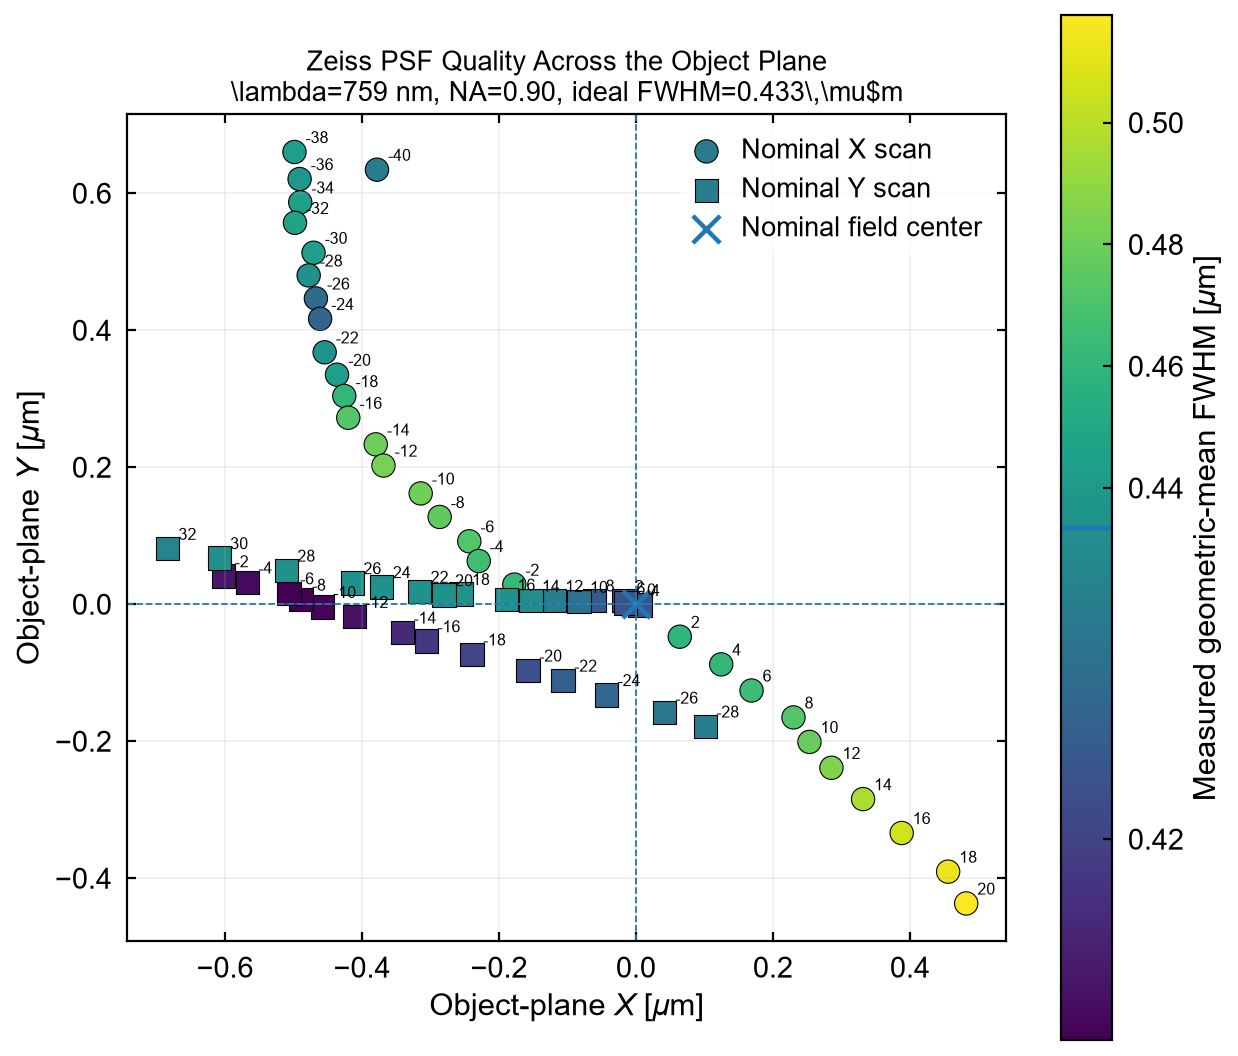

In [16]:
# ============================================================
# 2D MAP OF MEASURED PSF QUALITY
#
# Nominal X scan + nominal Y scan shown in the actual
# object-plane coordinates measured from camera centroids.
#
# Dot color = measured geometric-mean PSF FWHM
#
# Far points are excluded by default:
#       |command_step| < 100
#
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm


# ============================================================
# SETTINGS
# ============================================================

BASE = Path(
    r"C:\Users\admin\Desktop\Projects\Zeiss test\PSFs"
)

X_FILE = (
    BASE
    / "x_fov scan"
    / "x_fov_analysis.csv"
)

Y_FILE = (
    BASE
    / "y_fov scan"
    / "y_fov_analysis.csv"
)


MAGNIFICATION = 182.3
CAMERA_PIXEL_UM = 3.45

OBJECT_PIXEL_UM = (
    CAMERA_PIXEL_UM
    /
    MAGNIFICATION
)

WAVELENGTH_UM = 0.759
NA = 0.90


# Keep only ordinary / near scan points
MAX_STEP = 99


# ============================================================
# DIFFRACTION REFERENCES
# ============================================================

# FWHM of scalar Airy PSF
AIRY_FWHM_UM = (
    0.514
    *
    WAVELENGTH_UM
    /
    NA
)

# Radius to first Airy zero
AIRY_RADIUS_UM = (
    0.61
    *
    WAVELENGTH_UM
    /
    NA
)


print(
    f"Diffraction-limited FWHM = "
    f"{AIRY_FWHM_UM:.4f} um"
)

print(
    f"First Airy-zero radius   = "
    f"{AIRY_RADIUS_UM:.4f} um"
)


# ============================================================
# LOAD DATA
# ============================================================

xdata = pd.read_csv(
    X_FILE
)

ydata = pd.read_csv(
    Y_FILE
)


# ============================================================
# KEEP ONLY NEAR POINTS
# ============================================================

xdata = xdata[
    np.abs(xdata["command_step"]) <= MAX_STEP
].copy()

ydata = ydata[
    np.abs(ydata["command_step"]) <= MAX_STEP
].copy()


# ============================================================
# CONVERT CAMERA CENTROIDS TO ACTUAL OBJECT-PLANE COORDINATES
#
# Each dataset is referenced to its own 0.tif.
# ============================================================

def add_object_coordinates(df):

    df = df.copy()

    zero = df.loc[
        df["command_step"] == 0
    ]

    if len(zero) != 1:
        raise RuntimeError(
            "Could not uniquely identify 0.tif"
        )

    x0 = float(
        zero.iloc[0]["x_centroid_px"]
    )

    y0 = float(
        zero.iloc[0]["y_centroid_px"]
    )

    df["X_um"] = (
        df["x_centroid_px"] - x0
    ) * OBJECT_PIXEL_UM

    df["Y_um"] = (
        df["y_centroid_px"] - y0
    ) * OBJECT_PIXEL_UM

    return df


xdata = add_object_coordinates(
    xdata
)

ydata = add_object_coordinates(
    ydata
)


# ============================================================
# REMOVE DUPLICATE CENTRAL POINT FROM Y SCAN
# ============================================================

yplot = ydata[
    ydata["command_step"] != 0
].copy()


# ============================================================
# COMBINE DATA FOR COLOR RANGE
# ============================================================

all_fwhm = np.concatenate([
    xdata["fwhm_geo_um"].to_numpy(),
    yplot["fwhm_geo_um"].to_numpy()
])


# ============================================================
# COLOR NORMALIZATION
#
# Center the color scale at the diffraction-limited FWHM.
# ============================================================

vmin = np.min(all_fwhm)
vmax = np.max(all_fwhm)

# TwoSlopeNorm requires:
# vmin < vcenter < vmax
if (
    vmin
    <
    AIRY_FWHM_UM
    <
    vmax
):

    norm = TwoSlopeNorm(
        vmin=vmin,
        vcenter=AIRY_FWHM_UM,
        vmax=vmax
    )

else:

    norm = None


# ============================================================
# 2D PSF MAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 7)
)


# ------------------------------------------------------------
# X scan
# ------------------------------------------------------------

sc_x = ax.scatter(

    xdata["X_um"],

    xdata["Y_um"],

    c=xdata["fwhm_geo_um"],

    cmap="viridis",

    norm=norm,

    s=110,

    marker="o",

    edgecolors="black",

    linewidths=0.5,

    label="Nominal X scan"

)


# ------------------------------------------------------------
# Y scan
# ------------------------------------------------------------

sc_y = ax.scatter(

    yplot["X_um"],

    yplot["Y_um"],

    c=yplot["fwhm_geo_um"],

    cmap="viridis",

    norm=norm,

    s=110,

    marker="s",

    edgecolors="black",

    linewidths=0.5,

    label="Nominal Y scan"

)


# ============================================================
# CENTRAL FIELD POINT
# ============================================================

ax.scatter(

    0,
    0,

    marker="x",

    s=150,

    linewidths=2,

    label="Nominal field center"

)


# ============================================================
# OPTIONAL LABEL EACH POINT WITH COMMAND
# ============================================================

for _, row in xdata.iterrows():

    ax.annotate(

        f"{int(row['command_step'])}",

        (
            row["X_um"],
            row["Y_um"]
        ),

        xytext=(5, 4),

        textcoords="offset points",

        fontsize=7

    )


for _, row in yplot.iterrows():

    ax.annotate(

        f"{int(row['command_step'])}",

        (
            row["X_um"],
            row["Y_um"]
        ),

        xytext=(5, 4),

        textcoords="offset points",

        fontsize=7

    )


# ============================================================
# COLORBAR
# ============================================================

cbar = fig.colorbar(
    sc_x,
    ax=ax
)

cbar.set_label(
    r"Measured geometric-mean FWHM [$\mu$m]"
)


# Mark diffraction limit on colorbar
cbar.ax.axhline(
    AIRY_FWHM_UM,
    linewidth=2
)


# ============================================================
# AXES
# ============================================================

ax.axhline(
    0,
    linestyle="--",
    linewidth=0.8
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=0.8
)


ax.set_xlabel(
    r"Object-plane $X$ [$\mu$m]"
)

ax.set_ylabel(
    r"Object-plane $Y$ [$\mu$m]"
)


ax.set_title(

    "Zeiss PSF Quality Across the Object Plane\n"
    rf"\lambda={WAVELENGTH_UM*1000:.0f} nm, "
    rf"NA={NA:.2f}, "
    rf"ideal FWHM={AIRY_FWHM_UM:.3f}\,\mu$m"

)


ax.grid(
    alpha=0.2
)

ax.legend()


# Equal physical scaling of x and y
ax.set_aspect(
    "equal",
    adjustable="box"
)


fig.tight_layout()

plt.show()

Object-plane scale        = 18.92 nm/pixel
Diffraction-limited FWHM  = 0.4335 um
First Airy-zero radius    = 0.5144 um


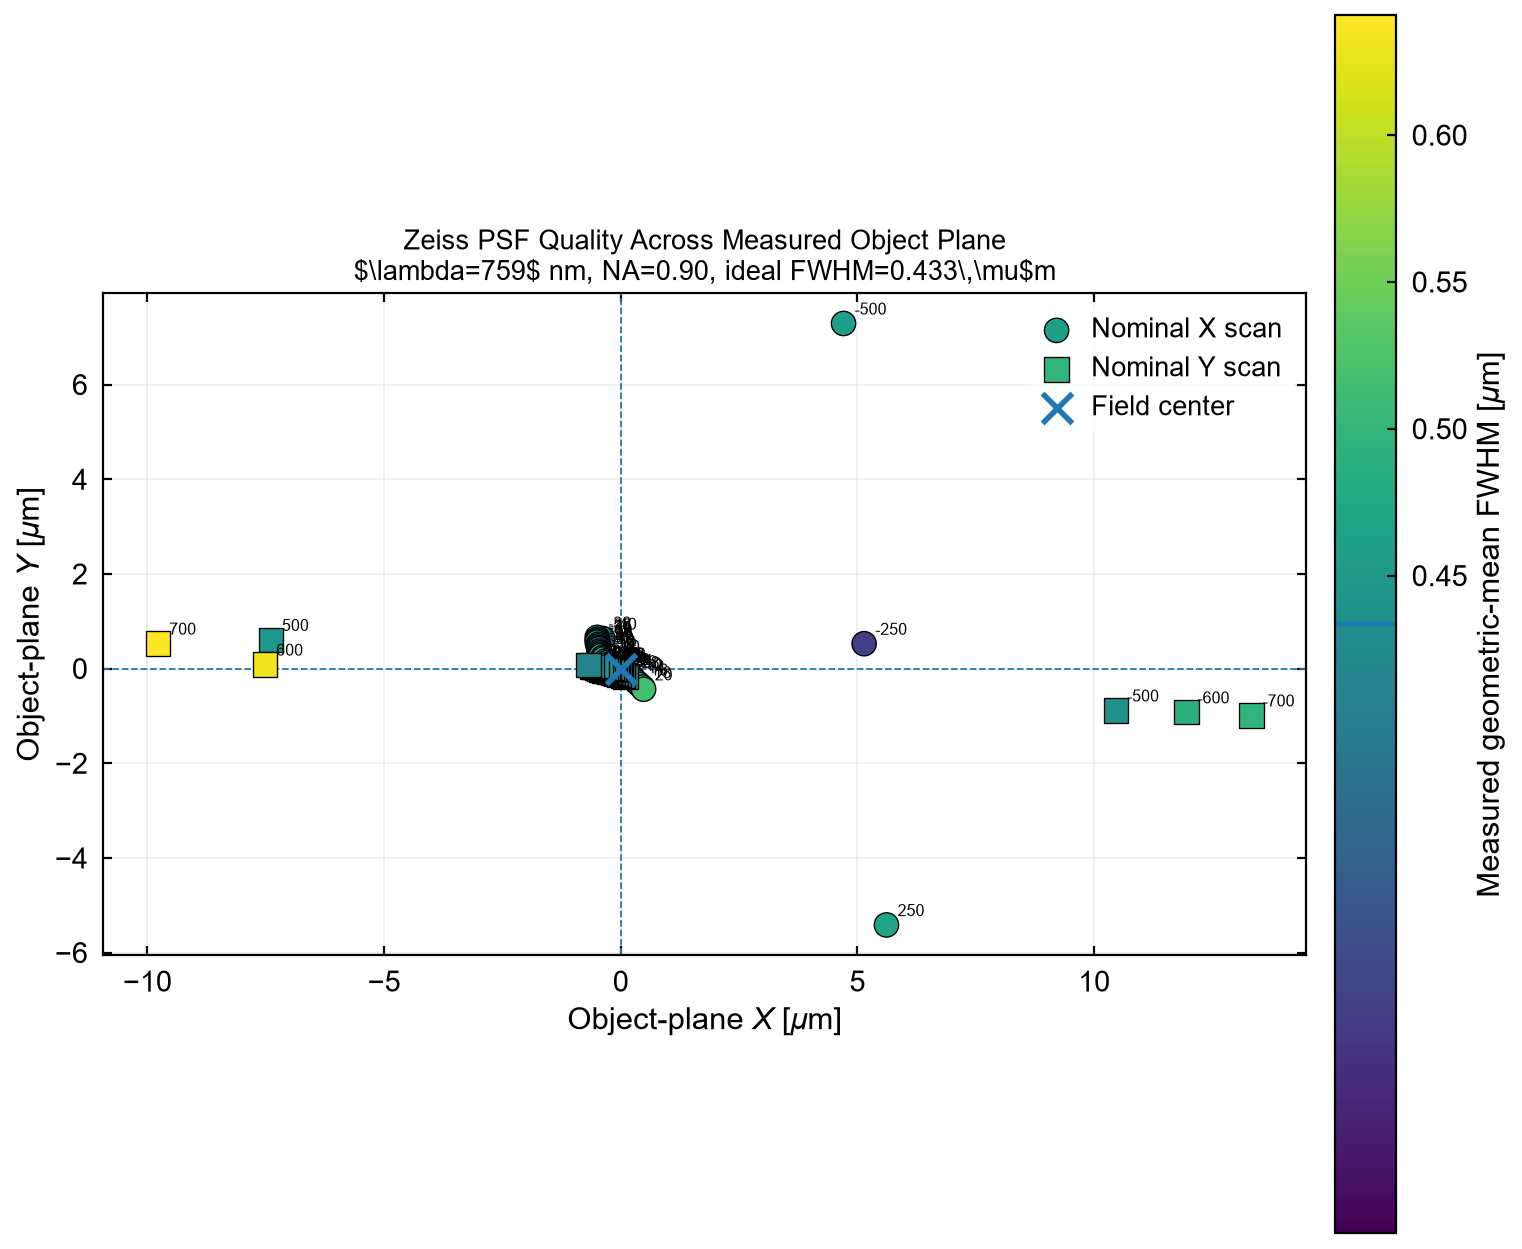

In [17]:
# ============================================================
# 2D PSF MAP — ALL X AND Y SCAN POINTS
#
# Includes EVERYTHING:
#   near points
#   +/-250
#   +/-500
#   +/-600
#   +/-700
#   etc.
#
# Dot color = measured geometric-mean PSF FWHM
#
# Coordinates are determined from the actual camera centroid
# displacement relative to each scan's 0.tif.
#
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm


# ============================================================
# SETTINGS
# ============================================================

BASE = Path(
    r"C:\Users\admin\Desktop\Projects\Zeiss test\PSFs"
)

X_FILE = (
    BASE
    / "x_fov scan"
    / "x_fov_analysis.csv"
)

Y_FILE = (
    BASE
    / "y_fov scan"
    / "y_fov_analysis.csv"
)


# Camera / imaging parameters
MAGNIFICATION = 182.3

CAMERA_PIXEL_UM = 3.45

OBJECT_PIXEL_UM = (
    CAMERA_PIXEL_UM
    /
    MAGNIFICATION
)


# Optical parameters
WAVELENGTH_UM = 0.759

NA = 0.90


# ============================================================
# DIFFRACTION REFERENCES
# ============================================================

# Scalar Airy FWHM
AIRY_FWHM_UM = (
    0.514
    *
    WAVELENGTH_UM
    /
    NA
)

# First Airy zero radius
AIRY_RADIUS_UM = (
    0.61
    *
    WAVELENGTH_UM
    /
    NA
)


print("=" * 65)

print(
    f"Object-plane scale        = "
    f"{OBJECT_PIXEL_UM*1000:.2f} nm/pixel"
)

print(
    f"Diffraction-limited FWHM  = "
    f"{AIRY_FWHM_UM:.4f} um"
)

print(
    f"First Airy-zero radius    = "
    f"{AIRY_RADIUS_UM:.4f} um"
)

print("=" * 65)


# ============================================================
# LOAD ALL DATA
# ============================================================

xdata = pd.read_csv(
    X_FILE
)

ydata = pd.read_csv(
    Y_FILE
)


# ============================================================
# FUNCTION:
# CONVERT CAMERA CENTROIDS TO OBJECT-PLANE COORDINATES
# ============================================================

def add_object_coordinates(df):

    df = df.copy()


    # --------------------------------------------------------
    # Find the centroid of 0.tif
    # --------------------------------------------------------

    zero = df[
        df["command_step"] == 0
    ]


    if len(zero) != 1:

        raise RuntimeError(
            "Could not uniquely identify command_step = 0"
        )


    x0 = float(
        zero.iloc[0]["x_centroid_px"]
    )

    y0 = float(
        zero.iloc[0]["y_centroid_px"]
    )


    # --------------------------------------------------------
    # Actual displacement on camera
    # --------------------------------------------------------

    dx_px = (
        df["x_centroid_px"]
        -
        x0
    )

    dy_px = (
        df["y_centroid_px"]
        -
        y0
    )


    # --------------------------------------------------------
    # Convert to object-plane coordinates
    # --------------------------------------------------------

    df["X_um"] = (
        dx_px
        *
        OBJECT_PIXEL_UM
    )

    df["Y_um"] = (
        dy_px
        *
        OBJECT_PIXEL_UM
    )


    # Physical radial displacement from center
    df["R_um"] = np.sqrt(
        df["X_um"]**2
        +
        df["Y_um"]**2
    )


    # PSF width relative to diffraction limit
    df["PSF_ratio"] = (
        df["fwhm_geo_um"]
        /
        AIRY_FWHM_UM
    )


    return df


# ============================================================
# APPLY TO BOTH SCANS
# ============================================================

xdata = add_object_coordinates(
    xdata
)

ydata = add_object_coordinates(
    ydata
)


# ============================================================
# REMOVE DUPLICATE Y-SCAN ZERO POINT
#
# Both datasets have their own 0.tif.
# Keep X zero as the plotted central reference.
# ============================================================

yplot = ydata[
    ydata["command_step"] != 0
].copy()


# ============================================================
# COMBINE FWHM VALUES FOR COMMON COLOR SCALE
# ============================================================

all_fwhm = np.concatenate([

    xdata["fwhm_geo_um"].to_numpy(),

    yplot["fwhm_geo_um"].to_numpy()

])


vmin = np.nanmin(
    all_fwhm
)

vmax = np.nanmax(
    all_fwhm
)


# Center color normalization at diffraction limit
if (
    vmin
    <
    AIRY_FWHM_UM
    <
    vmax
):

    norm = TwoSlopeNorm(
        vmin=vmin,
        vcenter=AIRY_FWHM_UM,
        vmax=vmax
    )

else:

    norm = None


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 8)
)


# ------------------------------------------------------------
# X-SCAN DATA
# ------------------------------------------------------------

sc_x = ax.scatter(

    xdata["X_um"],

    xdata["Y_um"],

    c=xdata["fwhm_geo_um"],

    cmap="viridis",

    norm=norm,

    s=120,

    marker="o",

    edgecolors="black",

    linewidths=0.6,

    label="Nominal X scan",

    zorder=3

)


# ------------------------------------------------------------
# Y-SCAN DATA
# ------------------------------------------------------------

sc_y = ax.scatter(

    yplot["X_um"],

    yplot["Y_um"],

    c=yplot["fwhm_geo_um"],

    cmap="viridis",

    norm=norm,

    s=120,

    marker="s",

    edgecolors="black",

    linewidths=0.6,

    label="Nominal Y scan",

    zorder=3

)


# ============================================================
# CENTRAL POINT
# ============================================================

ax.scatter(

    0,
    0,

    marker="x",

    s=180,

    linewidths=2.5,

    label="Field center",

    zorder=5

)


# ============================================================
# ANNOTATE EVERY POINT WITH PICOMOTOR COMMAND
# ============================================================

for _, row in xdata.iterrows():

    ax.annotate(

        f"{int(row['command_step'])}",

        (
            row["X_um"],
            row["Y_um"]
        ),

        xytext=(5, 4),

        textcoords="offset points",

        fontsize=7

    )


for _, row in yplot.iterrows():

    ax.annotate(

        f"{int(row['command_step'])}",

        (
            row["X_um"],
            row["Y_um"]
        ),

        xytext=(5, 4),

        textcoords="offset points",

        fontsize=7

    )


# ============================================================
# COLORBAR
# ============================================================

cbar = fig.colorbar(
    sc_x,
    ax=ax,
    pad=0.02
)


cbar.set_label(
    r"Measured geometric-mean FWHM [$\mu$m]"
)


# Mark diffraction-limited FWHM on color bar
cbar.ax.axhline(
    AIRY_FWHM_UM,
    linewidth=2
)


# ============================================================
# AXES
# ============================================================

ax.axhline(
    0,
    linestyle="--",
    linewidth=0.8
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=0.8
)


ax.set_xlabel(
    r"Object-plane $X$ [$\mu$m]"
)

ax.set_ylabel(
    r"Object-plane $Y$ [$\mu$m]"
)


ax.set_title(

    "Zeiss PSF Quality Across Measured Object Plane\n"
    rf"$\lambda={WAVELENGTH_UM*1000:.0f}$ nm, "
    rf"NA={NA:.2f}, "
    rf"ideal FWHM={AIRY_FWHM_UM:.3f}\,\mu$m"

)


ax.grid(
    alpha=0.20
)

ax.legend()


# Correct physical aspect ratio
ax.set_aspect(
    "equal",
    adjustable="box"
)


fig.tight_layout()

plt.show()